# Graph spectra and late-time concurrence in a lossy reservoir network: numerical code

This notebook computes Figs. 1 to 5 of the article and the numerical checks described in its Appendix E. No precomputed trajectory, external project module, or prior result file is read.

Run every cell in order in a clean environment with Python 3.11 to 3.13, NumPy, SciPy, Matplotlib, IPython, and mpmath. Fixed seeds and exact parameters are recorded below. Figures are written to `figs/` and numerical records to `results/`.

Display data are recomputed on finer grids, with locally optimized extrema and bracketed zero boundaries. No uniform raw-concurrence cutoff is applied. Small positive values, numerical zero intervals, and unresolved boundary residues are distinguished. All comparisons are finite numerical checks. They are not universal error bounds and do not replace the proofs in the article.


In [1]:
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
from pathlib import Path
from dataclasses import dataclass
from itertools import combinations, combinations_with_replacement
import itertools
import json
import hashlib
import time
import platform
import sys
import numpy as np
import scipy
import mpmath as mp
from scipy import linalg as la, sparse as sp
from scipy.sparse.linalg import expm_multiply
from scipy.integrate import solve_ivp, quad_vec
from scipy.optimize import brentq, minimize_scalar
from scipy.signal import find_peaks
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
from IPython.display import display, Markdown, Image
%matplotlib inline

np.random.seed(20261124)

OUTPUT_DIR = Path('results')
FIGURE_DIR = Path('figs')
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)
STARTED = time.time()
summary = {'parameters': {'lambda': 1.0, 'g': 0.3, 'eta': 3.0},
           'environment': {'python': sys.version, 'numpy': np.__version__,
                           'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__,
                           'platform': platform.platform(), 'mpmath': mp.__version__}}
summary["display_convention"] = {"raw_height_cutoff": None}
arrays = {}
validation = {}
print('Figures:', FIGURE_DIR, ' Numerical records:', OUTPUT_DIR)

Figures: figs  Numerical records: results


## Exact dynamics

The basis includes every memory occupation allowed by the total-excitation cutoff. Boson annihilation uses the occupation square root. Sparse matrix exponentials evolve the complete density matrix, including all cross-sector coherences.

In [2]:
def adjacency(n, edges):
    """Make a real symmetric adjacency matrix from zero based undirected edges."""
    a = np.zeros((n, n), dtype=float)
    for i, j in edges:
        if i == j or not (0 <= i < n and 0 <= j < n):
            raise ValueError('Invalid simple graph edge')
        a[i, j] = a[j, i] = 1.0
    return a

def graph_catalog():
    """Return the graphs used in the figures and spectral checks."""
    return {
        'P3': adjacency(3, [(0, 1), (1, 2)]),
        'P4': adjacency(4, [(0, 1), (1, 2), (2, 3)]),
        'K3': adjacency(3, [(0, 1), (1, 2), (0, 2)]),
        'G0': adjacency(4, [(0, 1), (1, 2), (0, 2), (2, 3)]),
        'G0+24': adjacency(4, [(0, 1), (1, 2), (0, 2), (2, 3), (1, 3)]),
        'K33': adjacency(6, [(i, j) for i in range(3) for j in range(3, 6)]),
        'prism': adjacency(6, [(0, 1), (1, 2), (0, 2), (3, 4), (4, 5),
                               (3, 5), (0, 3), (1, 4), (2, 5)]),
    }

@dataclass
class Model:
    A: np.ndarray
    states: list
    index: dict
    sectors: list
    H: sp.csr_matrix
    jumps: list
    memories: list
    qubit_lowering: list
    qubit_number: list
    g: float
    eta: float
    lam: float
    delta: float

    @property
    def n(self):
        return self.A.shape[0]

    @property
    def dim(self):
        return len(self.states)

    def no_jump_hamiltonian(self):
        return self.H - 0.5j * sum((j.conj().T @ j for j in self.jumps),
                                   sp.csr_matrix(self.H.shape, dtype=complex))

def _basis(n, include_memory=True):
    states, sectors = [], []
    for total in range(3):
        current = []
        for nq in range(min(total, n), -1, -1):
            nm = total - nq
            if nm and not include_memory:
                continue
            for qs in combinations(range(n), nq):
                mask = sum(1 << q for q in qs)
                for occupied in combinations_with_replacement(range(n), nm):
                    memory = [0] * n
                    for r in occupied:
                        memory[r] += 1
                    current.append(len(states))
                    states.append((mask, tuple(memory)))
        sectors.append(np.asarray(current, dtype=int))
    return states, {s: k for k, s in enumerate(states)}, sectors

def _operators(n, states, index):
    dim = len(states)
    memories, lowering, numbers = [], [], []
    for r in range(n):
        mr, mc, mv, sr, sc = [], [], [], [], []
        occupation = np.zeros(dim)
        for col, (mask, mem) in enumerate(states):
            occupation[col] = (mask >> r) & 1
            if mem[r]:
                reduced = list(mem)
                reduced[r] -= 1
                mr.append(index[(mask, tuple(reduced))])
                mc.append(col)
                mv.append(np.sqrt(mem[r]))
            if occupation[col]:
                sr.append(index[(mask ^ (1 << r), mem)])
                sc.append(col)
        memories.append(sp.csr_matrix((mv, (mr, mc)), shape=(dim, dim), dtype=complex))
        lowering.append(sp.csr_matrix((np.ones(len(sr)), (sr, sc)),
                                      shape=(dim, dim), dtype=complex))
        numbers.append(sp.diags(occupation, format='csr', dtype=complex))
    return memories, lowering, numbers

In [3]:
def build_model(A, g=0.3, eta=3.0, lam=1.0, delta=0.0):
    """Construct the exact model on the space with at most two total excitations."""
    A = np.asarray(A, dtype=float)
    n = len(A)
    if A.shape != (n, n) or not np.allclose(A, A.T):
        raise ValueError('Adjacency matrix must be real and symmetric')
    if min(g, lam) <= 0 or eta < 0:
        raise ValueError('Rates are outside their allowed ranges')
    states, index, sectors = _basis(n)
    memories, lowering, numbers = _operators(n, states, index)
    dim = len(states)
    H = sp.csr_matrix((dim, dim), dtype=complex)
    for r in range(n):
        H += delta * (memories[r].conj().T @ memories[r])
        exchange = lowering[r].conj().T @ memories[r]
        H += g * (exchange + exchange.conj().T)
        for s in range(r + 1, n):
            if A[r, s]:
                hop = memories[r].conj().T @ memories[s]
                H += eta * A[r, s] * (hop + hop.conj().T)
    jumps = [np.sqrt(2 * lam) * m for m in memories]
    return Model(A, states, index, sectors, H.tocsr(), jumps, memories,
                 lowering, numbers, g, eta, lam, delta)

def preparation(model, pair=(0, 2)):
    """Return the normalized pure state of Eq. (prep) as a density matrix."""
    psi = np.zeros(model.dim, dtype=complex)
    zero = (0,) * model.n
    psi[model.index[(0, zero)]] = np.sqrt(0.1) * np.exp(0.4j)
    profile = np.zeros(model.n)
    profile[list(pair)] = 1 / np.sqrt(2)
    for r in range(model.n):
        psi[model.index[(1 << r, zero)]] = np.sqrt(0.8) * profile[r]
    psi[model.index[((1 << pair[0]) | (1 << pair[1]), zero)]] = np.sqrt(0.1) * np.exp(0.7j)
    return np.outer(psi, psi.conj())

def liouvillian(model):
    """Return the column vectorized full Lindblad generator as a sparse matrix."""
    identity = sp.eye(model.dim, format='csr', dtype=complex)
    heff = model.no_jump_hamiltonian()
    L = -1j * (sp.kron(identity, heff) - sp.kron(heff.conj(), identity))
    for jump in model.jumps:
        L += sp.kron(jump.conj(), jump)
    return L.tocsr()

def pair_reduction(model, pair):
    """Sparse partial trace from a vectorized full state to a four by four pair."""
    i, j = pair
    groups = {}
    for k, (mask, mem) in enumerate(model.states):
        env = (mask & ~((1 << i) | (1 << j)), mem)
        row = 2 * (1 - ((mask >> i) & 1)) + 1 - ((mask >> j) & 1)
        groups.setdefault(env, []).append((k, row))
    rows, cols = [], []
    for states in groups.values():
        for k, a in states:
            for ell, b in states:
                rows.append(4 * a + b)
                cols.append(k + model.dim * ell)
    return sp.csr_matrix((np.ones(len(rows)), (rows, cols)),
                         shape=(16, model.dim * model.dim))

In [4]:
CONCURRENCE_CORRELATION_TOL = 1e-8

def propagate(model, rho, times, pairs=((0, 2),), max_batch_elements=2000000):
    """Propagate an initial density matrix on an arbitrary increasing time grid.

    Matrix exponential batches bound working memory and avoid storing full
    density trajectories. The output maps each pair tuple to pair states of
    shape (time, 4, 4).
    """
    times = np.asarray(times, dtype=float)
    if times.ndim != 1 or len(times) == 0 or times[0] != 0 or np.any(np.diff(times) <= 0):
        raise ValueError('Times must start at zero and then increase strictly')
    rho = np.asarray(rho, dtype=complex)
    state = rho.reshape(-1, order='F')
    L = liouvillian(model)
    reductions = {tuple(pair): pair_reduction(model, pair) for pair in pairs}
    outputs = {pair: [] for pair in reductions}

    def collect(sol):
        for pair, red in reductions.items():
            outputs[pair].append((red @ sol.T).T.reshape(-1, 4, 4))

    collect(state[None, ...])
    k = 0
    max_steps = max(1, max_batch_elements // state.size)
    traceL = L.diagonal().sum()
    while k < len(times) - 1:
        dt = times[k + 1] - times[k]
        stop = k + 1
        limit = min(len(times) - 1, k + max_steps, k + max(1, int(100 / dt)))
        while stop < limit and np.isclose(times[stop + 1] - times[stop], dt, rtol=1e-10, atol=1e-11):
            stop += 1
        count = stop - k
        sol = expm_multiply(L, state, start=0, stop=times[stop] - times[k],
                            num=count + 1, endpoint=True, traceA=traceL)
        collect(sol[1:])
        state = sol[-1]
        k = stop
    return {pair: np.concatenate(chunks) for pair, chunks in outputs.items()}

def state_diagnostics(rhos):
    rr = (rhos + rhos.swapaxes(-1, -2).conj()) / 2
    return {'min_pair_eigenvalue': float(np.linalg.eigvalsh(rr).min()),
            'max_trace_error': float(np.max(abs(np.trace(rr, axis1=-2, axis2=-1) - 1)))}

def stable_concurrence(rhos):
    # Factor the diagonal-normalized correlation matrix before restoring each
    # row scale. Direct sqrt(rho), even after determinant-one balancing, can
    # turn eigenvalue roundoff into a spurious square-root contribution.
    global last_factor_qa
    rr=np.asarray(rhos)
    single=rr.ndim==2
    if single:rr=rr[None]
    rr=(rr+rr.swapaxes(-1,-2).conj())/2
    sd=np.sqrt(np.maximum(np.diagonal(rr,axis1=-2,axis2=-1).real,0))
    div=sd[:,:,None]*sd[:,None,:]
    corr=np.divide(rr,div,out=np.zeros_like(rr),where=div>0)
    vals,vecs=np.linalg.eigh(corr)
    if vals.min() < -CONCURRENCE_CORRELATION_TOL:
        raise ValueError("Correlation matrix is outside the accepted positivity tolerance")
    L=sd[:,:,None]*vecs*np.sqrt(np.maximum(vals,0))[:,None,:]
    Y=np.array([[0,0,0,-1],[0,0,1,0],[0,1,0,0],[-1,0,0,0]])
    reconstructed=L@L.swapaxes(-1,-2).conj()
    last_factor_qa=dict(min_correlation_eigenvalue=float(vals.min()),max_factor_reconstruction_error=float(np.max(abs(reconstructed-rr))),first_bad_sample=int(np.flatnonzero(vals[:,0]<-CONCURRENCE_CORRELATION_TOL)[0]) if np.any(vals[:,0]<-CONCURRENCE_CORRELATION_TOL) else None)
    sig=np.linalg.svd(L.swapaxes(-1,-2)@Y@L,compute_uv=False)
    C=np.maximum(sig[:,0]-sig[:,1:].sum(axis=1),0)
    return float(C[0]) if single else C

def rates(m):return {k:v for k,v in sector_rates(m).items() if not k.startswith('spectrum')}

last_factor_qa = {}

### Coefficients of the slow spectral contributions

`coefficient_matrix` computes $Q$ from the initial one-excitation block and the convergent integral of loss from two excitations. It retains every eigenvector whose channel root has the smallest amplitude decay rate. Repeated adjacency eigenvalues retain their multiplicities. An optional `channels="extreme"` calculation includes the roots at both extremal graph eigenvalues only after checking $2\gamma_2>\gamma_a+\gamma_b$ for every integral. A finite Sylvester solution alone does not establish convergence.

In [5]:
def channel_roots(theta, g=0.3, eta=3.0, lam=1.0, delta=0.0):
    roots = np.roots([1, -(delta + eta * theta - 1j * lam), -g * g])
    return roots[np.argsort(abs(roots))]

def sector_rates(model):
    heff = model.no_jump_hamiltonian().toarray()
    spectra = [la.eigvals(heff[np.ix_(s, s)]) for s in model.sectors[1:]]
    gamma1, gamma2 = [float(np.min(-z.imag)) for z in spectra]
    return {'R': float(la.eigvalsh(model.A)[-1]), 'gamma1': gamma1, 'gamma2': gamma2,
            'gap': gamma2 - 2 * gamma1, 'gap_per_g2': (gamma2 - 2 * gamma1) / model.g ** 2,
            'spectrum1': spectra[0], 'spectrum2': spectra[1]}

def leading_concurrence(coefficient, pair, times):
    Q, z, v = coefficient['Q'], coefficient['roots'], coefficient['vectors']
    t = np.asarray(times)
    coherence = np.zeros(len(t), complex)
    for a in range(len(z)):
        for b in range(len(z)):
            coherence += Q[a, b] * v[pair[0], a] * v[pair[1], b] * np.exp(-1j * (z[a] - z[b].conjugate()) * t)
    return 2 * abs(coherence)

def peak_list(times, curve, tmin=50, floor=0.0):
    indices, _ = find_peaks(curve)
    indices = indices[(times[indices] >= tmin) & (curve[indices] >= floor)]
    return [[float(times[k]), float(curve[k])] for k in indices]

def _json_ready(obj):
    if isinstance(obj, dict):
        return {str(k): _json_ready(v) for k, v in obj.items()}
    if isinstance(obj, (tuple, list)):
        return [_json_ready(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return _json_ready(obj.tolist())
    if isinstance(obj, complex):
        return {'real': float(obj.real), 'imag': float(obj.imag)}
    if isinstance(obj, np.generic):
        return _json_ready(obj.item())
    return obj

def coefficient_matrix(model, rho, channels='slow'):
    """Load the actual slow modes, including adjacency multiplicities.

    channels='extreme' is an explicit request for the smallest-modulus root
    at each extremal adjacency eigenvalue. All selected pair integrals must
    lie in the certified convergence domain. Numerical slow-root matching
    uses rtol=1e-8 and atol=1e-12 in the rate units. This optional choice is
    not a claim that both roots are slow.
    """
    if channels not in ('slow', 'extreme'):
        raise ValueError('Choose slow or extreme channels')
    vals, vecs = la.eigh(model.A)
    candidates = []
    for k, theta in enumerate(vals):
        for root_index, z in enumerate(channel_roots(theta, model.g, model.eta, model.lam, model.delta)):
            candidates.append((k, root_index, z))
    slow_rate = min(-z.imag for k, root_index, z in candidates)
    if channels == 'slow':
        selected = [(k, root_index, z) for k, root_index, z in candidates
                    if np.isclose(-z.imag, slow_rate, rtol=1e-8, atol=1e-12)]
    else:
        R = vals[-1]
        selected = [(k, root_index, z) for k, root_index, z in candidates
                    if root_index == 0 and (np.isclose(vals[k], vals[0], rtol=1e-10, atol=1e-10) or np.isclose(vals[k], R, rtol=1e-10, atol=1e-10))]
    selected.sort(key=lambda item: (-vals[item[0]], item[1]))
    vectors = np.column_stack([vecs[:, k] for k, root_index, z in selected])
    for col in range(vectors.shape[1]):
        nonzero = np.flatnonzero(abs(vectors[:, col]) > 1e-12)
        if vectors[nonzero[0], col] < 0:
            vectors[:, col] *= -1
    zs = np.array([z for k, root_index, z in selected])
    if np.any(abs(1 + zs * zs / model.g**2) < 1e-9):
        raise ValueError('A selected exceptional root needs a Jordan coefficient formula')
    s1, s2 = model.sectors[1:]
    H2 = model.no_jump_hamiltonian().toarray()[np.ix_(s2, s2)]
    gamma2 = float(min(-la.eigvals(H2).imag))
    damping = -zs.imag
    margins = 2 * gamma2 - damping[:, None] - damping[None, :]
    if np.any(margins <= 1e-12 * max(1.0, model.lam)):
        raise ValueError('The selected coefficient integral is outside the certified convergence domain: require 2 gamma2 > gamma_a + gamma_b')
    left = []
    for col, z in enumerate(zs):
        v = vectors[:, col]
        right = np.array([sum(v[r] for r in range(model.n) if (model.states[index][0] >> r) & 1)
                          + z/model.g * np.dot(v, model.states[index][1]) for index in s1])
        left.append(right / (1 + z*z/model.g**2))
    left = np.array(left)
    direct = left @ rho[np.ix_(s1, s1)] @ left.conj().T
    feeding = np.zeros_like(direct)
    rho2 = rho[np.ix_(s2, s2)]
    jumps = [jump.toarray()[np.ix_(s1, s2)] for jump in model.jumps]
    eye = np.eye(len(s2))
    residuals = []
    for a in range(len(zs)):
        for b in range(len(zs)):
            aa = -1j * (H2 - zs[a]*eye)
            bb = 1j * (H2.conj().T - zs[b].conjugate()*eye)
            X = la.solve_sylvester(aa, bb, -rho2)
            residuals.append(la.norm(aa @ X + X @ bb + rho2))
            feeding[a, b] = sum(left[a] @ jump @ X @ jump.conj().T @ left[b].conj() for jump in jumps)
    Q = direct + feeding
    result = {'Q': Q, 'direct': direct, 'feeding': feeding, 'roots': zs,
              'vectors': vectors, 'left': left, 'adjacency_values': vals[[k for k, _, _ in selected]],
              'trace': float(np.trace(Q).real), 'min_integral_margin': float(margins.min()),
              'max_sylvester_residual': float(max(residuals)),
              'feeding_fraction': float(np.trace(feeding).real / np.trace(Q).real) if np.trace(Q).real > 0 else 0.0}
    resonant_bipartite_pair = (model.delta == 0 and len(zs) == 2
        and np.isclose(result['adjacency_values'][0], vals[-1], rtol=1e-10, atol=1e-12)
        and np.isclose(result['adjacency_values'][1], -vals[-1], rtol=1e-10, atol=1e-12)
        and abs(zs[0].real-zs[1].real)>1e-10 and np.isclose(damping[0],damping[1]))
    result['bipartite_profile_available'] = bool(resonant_bipartite_pair)
    if resonant_bipartite_pair:
        omega = abs(zs[0].real-zs[1].real)
        result.update(nu=float(2*abs(Q[0, 1])/np.trace(Q).real),
                      threshold=float(2*damping[0]/np.hypot(2*damping[0], omega)),
                      period=float(2*np.pi/omega), omega=float(omega))
    return result

### Numerical precision and display convention

Concurrence is evaluated using a diagonal-normalized factorization and a singular-value spin-flip calculation. Hermiticity, trace, positivity, and reconstruction diagnostics are retained. Original arrays are not clamped to any display floor. The final figure cells use separate refined trajectories and local extrema/zero-boundary solves. Independent propagation and arbitrary-precision checks cover the low-value regions and distinguish numerical errors from errors of the asymptotic formulas.


In [6]:
BLUE = '#0072B2'
ORANGE = '#D55E00'
GRAY = '#666666'
plt.rcParams.update({'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix',
                     'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9,
                     'legend.fontsize': 8, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
                     'lines.linewidth': 1.25, 'axes.linewidth': 0.6,
                     'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'savefig.dpi': 240, 'axes.spines.top': False, 'axes.spines.right': False})

def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / (name + '.pdf'), bbox_inches='tight', pad_inches=0.035)
    fig.savefig(FIGURE_DIR / (name + '.png'), dpi=220, bbox_inches='tight', pad_inches=0.035)
    display(Image(filename=str(FIGURE_DIR / (name + '.png'))))
    plt.close(fig)

def show_table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(str(value) for value in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

def coefficient_diagnostics(load):
    return {key: value for key, value in load.items() if key not in ['vectors', 'left']}


## Model and graph labels

Memory hopping follows the graph. Loss feeds lower excitation blocks. Vertex labels are used consistently in the later preparations and pair observables. Red and blue mark the two parts of each bipartite graph. Yellow marks the vertices of nonbipartite graphs.

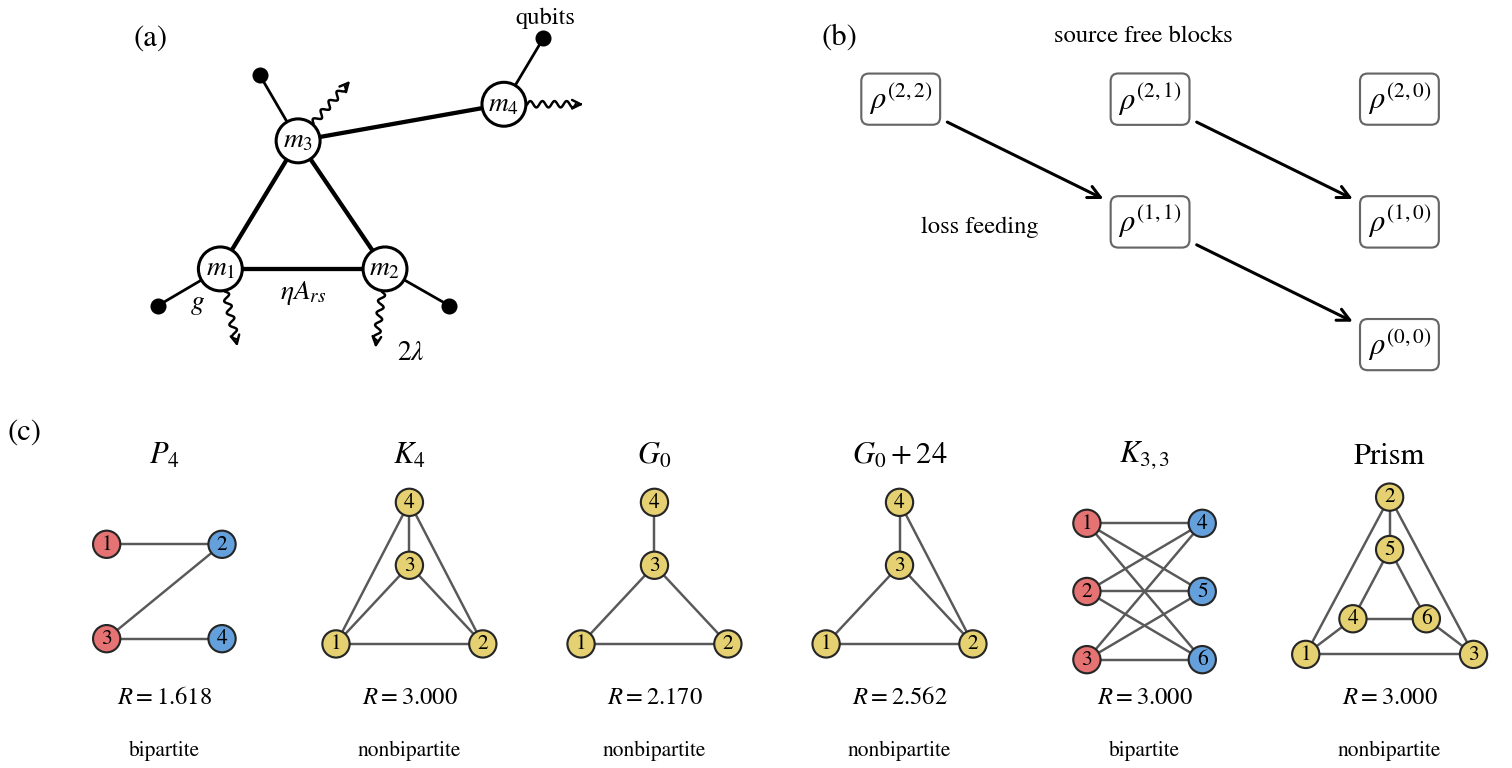

In [7]:
def draw_model_figure(output_dir=None):
    plt.rcParams.update({'font.family':'STIXGeneral', 'mathtext.fontset':'stix',
                         'font.size':9, 'pdf.fonttype':42, 'ps.fonttype':42})
    fig=plt.figure(figsize=(7.05,3.65))
    ax=fig.add_axes([.02,.51,.45,.45])
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_xlim(-.75,4.4)
    ax.set_ylim(-1.25,2.7)
    ax.text(-.7,2.4,'(a)',fontsize=10)
    pos=np.array([[.25,-.05],[2.05,-.05],[1.10,1.35],[3.35,1.75]])
    for i,j in [(0,1),(0,2),(1,2),(2,3)]:
        ax.plot(*pos[[i,j]].T,color='black',lw=1.4,zorder=1)
    offsets=np.array([[-.68,-.40],[.70,-.40],[-.42,.72],[.43,.72]])
    directions=np.array([[.22,-1.0],[-.12,-1.0],[.65,.75],[1.,0.]])
    for i,(x,y) in enumerate(pos):
        q=pos[i]+offsets[i]
        ax.plot([x,q[0]],[y,q[1]],color='black',lw=.9,zorder=1)
        ax.scatter(*q,s=18,color='black',zorder=4)
        ax.add_patch(Circle((x,y),.24,fc='white',ec='black',lw=1.0,zorder=3))
        ax.text(x,y,rf'$m_{i+1}$',ha='center',va='center',fontsize=9,zorder=5)
        direction=directions[i]/np.linalg.norm(directions[i])
        normal=np.array([-direction[1],direction[0]])
        start=pos[i]+.255*direction
        z=np.linspace(0,1,85)
        wave=start[None,:]+.53*z[:,None]*direction[None,:]+.035*np.sin(8*np.pi*z)[:,None]*normal[None,:]
        ax.plot(*wave.T,lw=.8,color='black',zorder=2)
        ax.add_patch(FancyArrowPatch(wave[-1]-.04*direction,wave[-1]+.15*direction,
                                     arrowstyle='->',mutation_scale=7,lw=.8,color='black'))
    ax.text(.90,-.38,r'$\eta A_{rs}$',fontsize=9)
    ax.text(-.08,-.48,r'$g$',fontsize=9)
    ax.text(2.18,-1.04,r'$2\lambda$',fontsize=9)
    ax.text(3.80,2.63,'qubits',ha='center',fontsize=8)

    ax=fig.add_axes([.54,.51,.44,.45])
    ax.axis('off')
    ax.set_xlim(-.5,4.7)
    ax.set_ylim(-.25,2.4)
    ax.text(-.5,2.2,'(b)',fontsize=10)
    block={(2,2):(.1,1.8),(2,1):(2,1.8),(2,0):(3.9,1.8),
           (1,1):(2,.9),(1,0):(3.9,.9),(0,0):(3.9,0)}
    for (n,m),(x,y) in block.items():
        ax.text(x,y,rf'$\rho^{{({n},{m})}}$',ha='center',va='center',fontsize=10,
                bbox={'boxstyle':'round,pad=.25','fc':'white','ec':'.4','lw':.7})
    for a,b in [((2,2),(1,1)),((2,1),(1,0)),((1,1),(0,0))]:
        ax.add_patch(FancyArrowPatch(block[a],block[b],arrowstyle='->',
                                    shrinkA=17,shrinkB=17,mutation_scale=10,lw=1))
    ax.text(1.95,2.22,'source free blocks',ha='center',fontsize=8)
    ax.text(.7,.82,'loss feeding',ha='center',fontsize=8)

    # The last entry gives the part of each vertex of a bipartite graph, None for a nonbipartite graph.
    part_colors=('#E57373','#64A0DC')
    nonbipartite_color='#E5D171'
    graphs=[('P4',4,[(0,1),(1,2),(2,3)],r'$P_4$',(0,1,0,1)),
            ('K4',4,[(0,1),(0,2),(0,3),(1,2),(1,3),(2,3)],r'$K_4$',None),
            ('G0',4,[(0,1),(0,2),(1,2),(2,3)],r'$G_0$',None),
            ('G0+24',4,[(0,1),(0,2),(1,2),(2,3),(1,3)],r'$G_0+24$',None),
            ('K33',6,[(i,j) for i in range(3) for j in range(3,6)],r'$K_{3,3}$',(0,0,0,1,1,1)),
            ('prism',6,[(0,1),(1,2),(0,2),(3,4),(4,5),(3,5),(0,3),(1,4),(2,5)],'Prism',None)]
    fig.text(.015,.435,'(c)',fontsize=10)
    for k,(name,n,edges,title,parts) in enumerate(graphs):
        ax=fig.add_axes([.045+.158*k,.08,.142,.33])
        ax.set_aspect('equal')
        ax.axis('off')
        if name=='P4': xy=np.array([[-.55,.45],[.55,.45],[-.55,-.45],[.55,-.45]])
        elif name in ('K4','G0','G0+24'):xy=np.array([[-.7,-.5],[.7,-.5],[0,.25],[0,.85]])
        elif name=='K33':xy=np.array([[-.55,.65],[-.55,0],[-.55,-.65],[.55,.65],[.55,0],[.55,-.65]])
        else:xy=np.array([[-.8,-.6],[0,.9],[.8,-.6],[-.35,-.26],[0,.4],[.35,-.26]])
        A=np.zeros((n,n))
        for i,j in edges:
            A[i,j]=A[j,i]=1
            ax.plot(*xy[[i,j]].T, lw=.8, color='.35', ls='-', zorder=1)
        assert parts is None or all(parts[i]!=parts[j] for i,j in edges)
        for i,(x,y) in enumerate(xy):
            ax.add_patch(Circle((x,y),.13,fc=nonbipartite_color if parts is None else part_colors[parts[i]],ec='.15',lw=.7,zorder=2))
            ax.text(x,y,str(i+1),ha='center',va='center',fontsize=7,zorder=3)
        R=np.linalg.eigvalsh(A)[-1]
        ax.set_xlim(-1.05,1.05)
        ax.set_ylim(-1.15,1.15)
        ax.set_title(title,fontsize=10,pad=0)
        ax.text(0,-1.07,rf'$R={R:.3f}$',ha='center',fontsize=8)
        fig.text(.116+.158*k,.041,'bipartite' if parts else 'nonbipartite',ha='center',fontsize=7)
    if output_dir is not None:
        out=Path(output_dir)
        out.mkdir(parents=True,exist_ok=True)
        fig.savefig(out/'fig1_model.pdf',bbox_inches='tight',pad_inches=.03)
        fig.savefig(out/'fig1_model.png',dpi=180,bbox_inches='tight',pad_inches=.03)
    return fig

fig = draw_model_figure()
save_figure(fig, 'fig1_model')

## Graph-selected decay and pair ratios

The preparation on the labeled pair $(i,j)$ is
$|\psi\rangle=\sqrt{0.1}e^{0.4i}|0\rangle+\sqrt{0.8}(|i\rangle+|j\rangle)/\sqrt{2}+\sqrt{0.1}e^{0.7i}|ij\rangle$.
We use $(1,3)$ for $G_0$ and $G_0+24$, and $(1,2)$ for $K_{3,3}$ and the prism. All four graphs use $g=0.3$, $\eta=3$, and $\lambda=1$. Solid curves are exact concurrence. Dashed curves in the equal-radius comparison are the leading term computed from $Q$.

In [8]:
summary['graphs'] = {}
summary['six_graph_rates'] = {name:rates(build_model(graph_catalog()[name])) for name in ['P4','K3','G0','G0+24','K33','prism']}
for name in ['G0', 'G0+24', 'K33', 'prism']:
    model = build_model(graph_catalog()[name])
    pair = (0, 1) if model.n == 6 else (0, 2)
    stop, step = (3000.0, 0.5) if model.n == 6 else (2000.0, 0.25)
    times = np.arange(0, stop + step/2, step)
    pairs = [pair, (0, 3)] if model.n == 4 else [pair]
    initial = preparation(model, pair)
    reduced = propagate(model, initial, times, pairs)
    load = coefficient_matrix(model, initial)
    curve = stable_concurrence(reduced[pair])
    arrays[name+'_t'] = times
    arrays[name+'_C'] = curve
    arrays[name+'_rho'] = reduced[pair]
    arrays[name+'_leading'] = leading_concurrence(load, pair, times)
    rec = {'rates': rates(model), 'coefficient': coefficient_diagnostics(load), 'pair': [j+1 for j in pair],
           'grid': {'start': 0, 'stop': stop, 'step': step, 'count': len(times)},
           'factor_qa': last_factor_qa.copy(), **state_diagnostics(reduced[pair])}
    if model.n == 4:
        arrays[name+'_C14'] = stable_concurrence(reduced[(0, 3)])
        arrays[name+'_rho14'] = reduced[(0, 3)]
        rec['final_pair_ratio'] = float(curve[-1]/arrays[name+'_C14'][-1])
        _, vectors = la.eigh(model.A)
        v = abs(vectors[:, -1])
        rec['Perron_pair_ratio'] = float(v[2]/v[3])
    summary['graphs'][name] = rec
    print(name, 'complete')

diff = arrays['G0_C'] - arrays['G0+24_C']
t = arrays['G0_t']
cross = np.flatnonzero(diff[:-1]*diff[1:] < 0)
summary['G0_G0+24_crossings'] = [float(t[k]-(t[k+1]-t[k])*diff[k]/(diff[k+1]-diff[k])) for k in cross]
show_table(['Graph', 'R', 'gamma1', 'gamma2', 'Positive gap'], [
    [name] + [f"{summary['graphs'][name]['rates'][key]:.9f}" for key in ['R','gamma1','gamma2','gap']]
    for name in summary['graphs']])

G0 complete
G0+24 complete
K33 complete
prism complete


| Graph | R | gamma1 | gamma2 | Positive gap |
| --- | --- | --- | --- | --- |
| G0 | 2.170086487 | 0.002062089 | 0.009450656 | 0.005326478 |
| G0+24 | 2.561552813 | 0.001492095 | 0.007814434 | 0.004830245 |
| K33 | 3.000000000 | 0.001094018 | 0.007466479 | 0.005278442 |
| prism | 3.000000000 | 0.001094018 | 0.006851636 | 0.004663599 |

## Loss feeding at a fixed one-excitation block

On $P_4$, let $|v\rangle=\sum_rv_r|r\rangle$ with $v_r=\sqrt{2/5}\sin(r\pi/5)$ and
$\rho_S(0)=0.15|v\rangle\langle v|+p_2|13\rangle\langle13|+(0.85-p_2)|0\rangle\langle0|$.
Only the two-excitation population and the compensating vacuum population change. The contribution from the initial one-excitation block has $Q_{R,-R}=0$. The ratio $\nu$ crosses the threshold at $p_2\simeq0.29626396$. For the opposite-part pair 34, $U=Q_{RR}-Q_{-R,-R}$ does not depend on $p_2$, and $F^2/U^2$ crosses $2\nu_{\mathrm{crit}}/(1-\nu_{\mathrm{crit}})$ at a larger $p_2$. We compare $p_2=0.1$ and $0.8$, which lie on opposite sides of both thresholds. The logarithmic panels plot raw concurrence of pairs 13 and 34 rather than removing their decay envelope.

In [9]:
def feeding_preparation(model, p2, p1=0.15):
    if not 0 <= p2 <= 1-p1:
        raise ValueError('Invalid mixture probabilities')
    zero = (0,)*model.n
    v = np.sqrt(2/5)*np.sin(np.pi*np.arange(1, 5)/5)    # unit Perron vector of P4
    one = np.zeros(model.dim, complex)
    for j in range(4):
        one[model.index[(1<<j, zero)]] = v[j]
    rho = p1*np.outer(one, one.conj())
    rho[model.index[(5,zero)], model.index[(5,zero)]] = p2
    rho[model.index[(0,zero)], model.index[(0,zero)]] = 1-p1-p2
    return rho

feed_model = build_model(graph_catalog()['P4'])
feed_rates = rates(feed_model)
direct_load = coefficient_matrix(feed_model, feeding_preparation(feed_model, 0))
pure_two = feeding_preparation(feed_model, 1, p1=0)
feed_load = coefficient_matrix(feed_model, pure_two)
threshold = feed_load['threshold']
direct_trace = direct_load['trace']
feed_trace = feed_load['trace']
feed_interference = 2*abs(feed_load['Q'][0,1])
crossing = threshold*direct_trace/(feed_interference-threshold*feed_trace)
p2_grid = np.linspace(0,0.85,171)
nu_grid = feed_interference*p2_grid/(direct_trace+feed_trace*p2_grid)
arrays['feeding_p2'] = p2_grid
arrays['feeding_nu'] = nu_grid
# Opposite-part criterion. The initial one-excitation block |v><v| loads only Q_RR, since w = Jv is orthogonal to v.
# Q^(2)_RR = Q^(2)_{-R,-R}, because a symmetry of H_eff that fixes |13> exchanges the R and -R channels.
# Hence U = Q_RR - Q_{-R,-R} does not depend on p2, and F is proportional to p2.
assert abs(direct_load['Q'][0,1]) < 1e-14 and abs(direct_load['Q'][1,1]) < 1e-14
U_direct = float((direct_load['Q'][0,0]-direct_load['Q'][1,1]).real)
assert abs(feed_load['Q'][0,0]-feed_load['Q'][1,1]) < 1e-12*abs(U_direct)
cross_threshold = 2*threshold/(1-threshold)
cross_crossing = np.sqrt(cross_threshold)*abs(U_direct)/feed_interference
times = np.arange(0,1200.0001,0.5)
summary['feeding'] = {'p1': 0.15, 'rates': feed_rates, 'threshold': threshold,
                      'crossing_p2': float(crossing), 'U': U_direct, 'cross_threshold': float(cross_threshold),
                      'cross_crossing_p2': float(cross_crossing), 'pure_two_coefficient': coefficient_diagnostics(feed_load),
                      'direct_coefficient': coefficient_diagnostics(direct_load),
                      'grid': {'start':0,'stop':1200,'step':0.5,'count':len(times)}, 'preparations': []}
feeding_pair_states = {}
for p2 in [0.1,0.8]:
    rho = feeding_preparation(feed_model,p2)
    load = coefficient_matrix(feed_model,rho)
    states = propagate(feed_model,rho,times,pairs=[(0,2),(2,3)])
    rr = states[(0,2)]
    cc = stable_concurrence(rr)
    lead = leading_concurrence(load,(0,2),times)
    key = f'feed_{p2:g}'
    arrays[key+'_t'], arrays[key+'_C'], arrays[key+'_leading'] = times,cc,lead
    arrays[key+'_rho'] = rr
    feeding_pair_states[p2] = rr
    late = times >= 500
    late_step = times[:-1] >= 500
    rec = {'p2':p2, 'nu':load['nu'], 'F':float(2*abs(load['Q'][0,1])),
           'cross_ratio':float((2*abs(load['Q'][0,1]))**2/(load['Q'][0,0]-load['Q'][1,1]).real**2), 'coefficient':coefficient_diagnostics(load),
           'late_peaks_after_500':peak_list(times,cc,tmin=500),
           'positive_steps_after_500':int(np.sum(np.diff(cc)[late_step]>1e-14)),
           'scaled_slope_range_after_500': [float(x) for x in [np.min(np.diff(cc)[late_step]/np.diff(times)[late_step]*np.exp(2*feed_rates['gamma1']*times[:-1][late_step])), np.max(np.diff(cc)[late_step]/np.diff(times)[late_step]*np.exp(2*feed_rates['gamma1']*times[:-1][late_step]))]],
           'late_scaled_error_after_800':float(np.max(np.exp(2*feed_rates['gamma1']*times[times>=800])*abs(cc[times>=800]-lead[times>=800]))),
           'factor_qa':last_factor_qa.copy(), **state_diagnostics(rr)}
    summary['feeding']['preparations'].append(rec)
    arrays[key+'_23_t'], arrays[key+'_23_C'] = times, stable_concurrence(states[(2,3)])
    arrays[key+'_23_leading'], arrays[key+'_23_rho'] = leading_concurrence(load,(2,3),times), states[(2,3)]
assert abs(crossing-0.2962639565927054) < 1e-9
show_table(['p2','nu','Threshold','F^2/U^2','Cross threshold','C13 late positive steps','C13 late peaks'], [
    [r['p2'],f"{r['nu']:.9f}",f'{threshold:.9f}',f"{r['cross_ratio']:.9f}",f'{cross_threshold:.9f}',r['positive_steps_after_500'],len(r['late_peaks_after_500'])]
    for r in summary['feeding']['preparations']])

| p2 | nu | Threshold | F^2/U^2 | Cross threshold | C13 late positive steps | C13 late peaks |
| --- | --- | --- | --- | --- | --- | --- |
| 0.1 | 0.095853678 | 0.200369612 | 0.014819711 | 0.501155570 | 0 | 0 |
| 0.8 | 0.308176203 | 0.200369612 | 0.948461481 | 0.501155570 | 376 | 4 |

## Late revival times

For the feeding preparation with $p_2=0.8$, pair 13 lies in one part with $\nu_{\mathrm{crit}}<\nu<1$, and pair 34 joins the two parts with $F^2(1-\nu_{\mathrm{crit}})>2\nu_{\mathrm{crit}}U^2$. Eqs. (times) and (times-cross) give the local maxima $t_n$ and $t_n'$ of the leading concurrence. They are first checked against the leading concurrence built from $Q$, and then compared with every local maximum of the exact concurrence after its last zero. A time predicted inside the last zero interval is paired with the first exact maximum after it.

The state has no coherence between excitation numbers. Each pair matrix therefore has only diagonal entries and $X_{23}$, and $C=2\max\{0,|X_{23}|-\sqrt{X_{11}X_{44}}\}$. Each exact maximum is a root of $dC/dt$, bracketed by a sign change on a grid of step $0.5/\lambda$. $X_{11}$ comes from the $|11\rangle$ row of $e^{-iH_2t}$. The vacuum population feeds no other entry. It is removed before propagation and restored from the unit trace. Otherwise this population of order one sets the error scale of the sparse exponential, and entries of order $10^{-11}$ lose relative accuracy. A closed form in 40-digit arithmetic, built from the eigenvalues of $H_1$ and $H_2$ without propagation, checks every maximum. One maximum per pair is repeated with 60 digits.

In [10]:
# Late revival times. Eqs. (times) and (times-cross) against the exact local maxima for Eq. (feeding-prep) with p2 = 0.8.


def closed_form_pair(model, rho, pair, dps=40):
    """Pair entries as exponential sums, for a state without coherence between excitation numbers.

    rho^(2,2)(t) = e^{-iH2t} B22 e^{iH2^dag t}. rho^(1,1) adds the loss from rho^(2,2) by variation of
    constants. The eigenvalues of H1 and H2 give every entry in closed form, evaluated with dps digits.
    Returns f(t) = |X23| - sqrt(X11 X44), whose positive part is C/2, and root finders for f and df/dt.
    """
    with mp.workdps(dps):
        K = model.no_jump_hamiltonian().toarray()
        s1, s2 = model.sectors[1:]
        M = lambda a: mp.matrix(np.asarray(a).tolist())
        (mu, X1), (ev2, X2) = mp.eig(M(K[np.ix_(s1, s1)])), mp.eig(M(K[np.ix_(s2, s2)]))
        Y1, Y2 = mp.inverse(X1), mp.inverse(X2)
        B1, B2 = Y1 * M(rho[np.ix_(s1, s1)]) * Y1.H, Y2 * M(rho[np.ix_(s2, s2)]) * Y2.H
        jumps = [Y1 * M(jump.toarray()[np.ix_(s1, s2)]) * X2 for jump in model.jumps]
        e1 = {(k, q): -1j * (mu[k] - mp.conj(mu[q])) for k in range(len(mu)) for q in range(len(mu))}
        e2 = {(l, p): -1j * (ev2[l] - mp.conj(ev2[p])) for l in range(len(ev2)) for p in range(len(ev2))}
        source = {(k, q, l, p): mp.fsum(R[k, l] * B2[l, p] * mp.conj(R[q, p]) for R in jumps)
                  for k, q in e1 for l, p in e2}
        assert min(abs(e2[l, p] - e1[k, q]) for (k, q, l, p), x in source.items() if x != 0) > 1e-12
        red = pair_reduction(model, pair).tocsr()

        def exponential_sum(entry):
            c1, c2 = dict.fromkeys(e1, mp.mpc(0)), dict.fromkeys(e2, mp.mpc(0))
            for col in red.indices[red.indptr[entry]:red.indptr[entry + 1]]:
                a, b = col % model.dim, col // model.dim
                if a in s1 and b in s1:
                    a, b = int(np.flatnonzero(s1 == a)[0]), int(np.flatnonzero(s1 == b)[0])
                    for k, q in e1:
                        w = X1[a, k] * mp.conj(X1[b, q])
                        c1[k, q] += w * B1[k, q]
                        for l, p in e2:
                            x = w * source[k, q, l, p] / (e2[l, p] - e1[k, q])
                            c2[l, p] += x
                            c1[k, q] -= x
                else:
                    assert a in s2 and b in s2, 'coherence between excitation numbers'
                    a, b = int(np.flatnonzero(s2 == a)[0]), int(np.flatnonzero(s2 == b)[0])
                    for l, p in e2:
                        c2[l, p] += X2[a, l] * B2[l, p] * mp.conj(X2[b, p])
            return [(c, e1[key]) for key, c in c1.items() if c] + [(c, e2[key]) for key, c in c2.items() if c]

        sums = [exponential_sum(entry) for entry in (0, 5, 10, 6)]      # X11, X22, X33, X23

    def entries(t, derivative):
        t = mp.mpf(t)
        out = []
        for terms in sums:
            powers = [mp.exp(s * t) for c, s in terms]
            out.append([mp.fsum(c * s ** d * e for (c, s), e in zip(terms, powers)) for d in range(1 + derivative)])
        return out

    def value(t):
        with mp.workdps(dps):
            (X11,), (X22,), (X33,), (X23,) = entries(t, False)
            X11 = mp.re(X11)
            return abs(X23) - mp.sqrt(max(X11 * (1 - X11 - mp.re(X22 + X33)), 0))

    def rate(t):
        (X11, D11), (X22, D22), (X33, D33), (X23, D23) = entries(t, True)
        X11, D11 = mp.re(X11), mp.re(D11)
        X44, D44 = 1 - X11 - mp.re(X22 + X33), -D11 - mp.re(D22 + D33)
        return mp.re(mp.conj(X23) * D23) / abs(X23) - (D11 * X44 + X11 * D44) / (2 * mp.sqrt(X11 * X44))

    def root_near(t0, width=1e-6, of_rate=False):
        with mp.workdps(dps):
            return mp.findroot(rate if of_rate else value, (mp.mpf(t0) - width, mp.mpf(t0) + width), solver='anderson')
    return value, root_near


def revival_time_comparison(model, rho, pair, window, step=0.5):
    """Predicted maxima of the leading concurrence and the exact local maxima of C on the window.

    Same part pairs use Eq. (times) and pairs in opposite parts Eq. (times-cross). The window starts after
    the last zero of C, so C = 2(|X23| - sqrt(X11 X44)) is positive and smooth on it. Predicted times less
    than half a spacing before the window are included, since such a time can lie inside the last zero interval.
    """
    load = coefficient_matrix(model, rho)
    Q, z, v = load['Q'], load['roots'], load['vectors']
    gamma, Omega, nu_c = -z[0].imag, load['omega'], load['threshold']
    J = [v[k, 1] / v[k, 0] for k in pair]                              # w_k/v_k = J_kk with w = Jv
    assert z[0].real < 0 and all(abs(abs(x) - 1) < 1e-12 for x in J)
    vartheta = np.arctan(Omega / (2 * gamma))
    if J[0] * J[1] > 0:
        nu = load['nu']
        assert nu_c < nu < 1
        phase, chi = np.angle(Q[0, 1]) + np.pi * (1 - np.sign(J[0])) / 2, np.arccos(-nu_c / nu)
        shift, spacing, ratio_name, ratio = (vartheta - chi - phase) / Omega, 2 * np.pi / Omega, 'nu', nu
    else:
        U, F = (Q[0, 0] - Q[1, 1]).real, 2 * abs(Q[0, 1])
        assert F**2 * (1 - nu_c) > 2 * nu_c * U**2
        phase, chi = np.angle(Q[0, 1]), np.arccos(nu_c * (1 + 2 * U**2 / F**2))
        shift, spacing, ratio_name, ratio = (vartheta + chi - 2 * phase) / (2 * Omega), np.pi / Omega, 'F^2/U^2', F**2 / U**2
    n = np.arange(np.ceil((window[0] - spacing / 2 - shift) / spacing), np.floor((window[1] - shift) / spacing) + 1).astype(int)
    t_pred = shift + spacing * n
    # The predicted times against the leading concurrence of Eq. (general-Phi), built from Q and the slow roots.
    exponent = -1j * (z[:, None] - z.conj()[None, :])

    def leading_log_rate(t):
        c = Q * np.outer(v[pair[0]], v[pair[1]]) * np.exp(exponent * t)
        return (c.sum().conjugate() * (exponent * c).sum()).real / abs(c.sum()) ** 2
    assert max(abs(leading_log_rate(t)) for t in t_pred) < 1e-12 * Omega
    assert all(leading_concurrence(load, pair, [t - step, t + step]).max() < leading_concurrence(load, pair, [t])[0] for t in t_pred)
    # Exact concurrence on the space without the vacuum population.
    L, red = liouvillian(model), pair_reduction(model, pair)
    vac = model.index[(0, (0,) * model.n)] * (model.dim + 1)
    assert L[:, vac].count_nonzero() == 0
    keep = np.arange(model.dim ** 2) != vac
    L, red = L[keep][:, keep].tocsr(), red[:, keep]
    trace = L.diagonal().sum()
    s2 = model.sectors[2]
    H2 = model.no_jump_hamiltonian().toarray()[np.ix_(s2, s2)]
    row = int(np.flatnonzero(s2 == model.index[((1 << pair[0]) | (1 << pair[1]), (0,) * model.n)])[0])
    ev, ve = la.eigh(rho[np.ix_(s2, s2)])
    F2 = ve * np.sqrt(np.maximum(ev, 0))

    def advance(u, dt):
        return expm_multiply(L * dt, u, traceA=trace * dt) if dt else u

    def f_and_rate(u, t):
        X, Xd = (red @ u).reshape(4, 4), (red @ (L @ u)).reshape(4, 4)
        assert not np.any(X[[0, 0, 0, 1, 2], [1, 2, 3, 3, 3]])
        a = la.expm(-1j * H2 * t)[row]
        f, fd = a @ F2, -1j * (a @ H2) @ F2
        X11, D11 = np.vdot(f, f).real, 2 * np.vdot(f, fd).real
        X44, D44 = 1 - X11 - X[1, 1].real - X[2, 2].real, -(D11 + Xd[1, 1].real + Xd[2, 2].real)
        root = np.sqrt(X11 * X44)
        return (abs(X[1, 2]) - root,
                (X[1, 2].conjugate() * Xd[1, 2]).real / abs(X[1, 2]) - (D11 * X44 + X11 * D44) / (2 * root))
    u, previous, maxima, values, minima = rho.reshape(-1, order='F')[keep], (None, 0., 0.), [], [], 0
    for t in np.arange(window[0], window[1] + step / 2, step):
        u = advance(u, t - previous[1])
        f, rate = f_and_rate(u, t)
        assert f > 0
        if previous[0] is not None and previous[2] > 0 > rate:
            u0, t0 = previous[:2]
            t_max = brentq(lambda s: f_and_rate(advance(u0, s - t0), s)[1], t0, t, xtol=1e-12, rtol=4 * np.finfo(float).eps)
            maxima.append(t_max)
            values.append(2 * f_and_rate(advance(u0, t_max - t0), t_max)[0])
        minima += previous[0] is not None and previous[2] < 0 < rate
        previous = (u, t, rate)
    t_exact = np.array(maxima)
    # One exact maximum within half a spacing of each predicted time.
    assert len(t_exact) == len(t_pred) and np.all(abs(t_exact - t_pred) < spacing / 2)
    r = rates(model)
    return {'pair': pair, 'window': list(window), 'step': step, 'n': n, 't_pred': t_pred, 't_exact': t_exact,
            'difference': t_exact - t_pred, 'C_exact': np.array(values), 'leading_at_pred': leading_concurrence(load, pair, t_pred),
            'exact_minima': int(minima), 'gamma1': r['gamma1'], 'gamma2': r['gamma2'], 'Omega': float(Omega),
            'nu_crit': float(nu_c), ratio_name: float(ratio), 'phase': float(phase), 'vartheta': float(vartheta),
            'chi': float(chi), 'shift': float(shift), 'spacing': float(spacing),
            'max_leading_log_rate_over_Omega': float(max(abs(leading_log_rate(t)) for t in t_pred) / Omega)}


revival_times = {}
for pair, window in [((0, 2), (100, 3000)), ((2, 3), (215, 3000))]:
    key = f'{pair[0] + 1}{pair[1] + 1}'
    rho = feeding_preparation(feed_model, 0.8)
    rec = revival_time_comparison(feed_model, rho, pair, window)
    # Independent check of every exact maximum, and of the last one with 60 digits.
    value, root_near = closed_form_pair(feed_model, rho, pair)
    reference = [root_near(t, of_rate=True) for t in rec['t_exact']]
    rec['closed_form_difference'] = float(max(abs(float(x) - t) for x, t in zip(reference, rec['t_exact'])))
    rec['digits_40_60_difference'] = float(abs(closed_form_pair(feed_model, rho, pair, dps=60)[1](reference[-1], of_rate=True) - reference[-1]))
    assert rec['closed_form_difference'] < 1e-10 and rec['digits_40_60_difference'] < 1e-30
    # Successive differences approach the factor exp(-(gamma2 - 2 gamma1) spacing).
    d = rec['difference']
    rec['ratio_limit'] = float(np.exp(-(rec['gamma2'] - 2 * rec['gamma1']) * rec['spacing']))
    assert np.all(d > 0) and np.all(abs(d[-6:][1:] / d[-6:][:-1] / rec['ratio_limit'] - 1) < 1e-4)
    revival_times[key] = rec
    for name in ['n', 't_pred', 't_exact', 'difference']:
        arrays[f'revival_{key}_{name}'] = rec[name]
summary['revival_times'] = revival_times
show_table(['Pair', 'Exact maxima', 'Window', 'First difference', 'Last difference', 'Last ratio', 'exp(-(gamma2-2gamma1) spacing)', 'Closed form difference'],
           [[key, len(r['t_exact']), r['window'], f"{r['difference'][0]:.6g}", f"{r['difference'][-1]:.6g}",
             f"{r['difference'][-1] / r['difference'][-2]:.6f}", f"{r['ratio_limit']:.6f}", f"{r['closed_form_difference']:.2g}"]
            for key, r in revival_times.items()])
show_table(['Pair', 'n', 'Predicted', 'Exact maximum', 'Difference'],
           [[key, k, f'{tp:.6f}', f'{te:.9f}', f'{x:.6e}'] for key, r in revival_times.items()
            for k, tp, te, x in zip(r['n'], r['t_pred'], r['t_exact'], r['difference'])])
# This figure is rendered after the refined sampling and independent precision checks below.

| Pair | Exact maxima | Window | First difference | Last difference | Last ratio | exp(-(gamma2-2gamma1) spacing) | Closed form difference |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 13 | 17 | [100, 3000] | 18.9525 | 1.05385e-06 | 0.389386 | 0.389386 | 5e-12 |
| 34 | 32 | [215, 3000] | 31.9349 | 6.79366e-06 | 0.624008 | 0.624008 | 5.5e-12 |

| Pair | n | Predicted | Exact maximum | Difference |
| --- | --- | --- | --- | --- |
| 13 | 1 | 151.540131 | 170.492586507 | 1.895246e+01 |
| 13 | 2 | 328.712318 | 329.880710747 | 1.168392e+00 |
| 13 | 3 | 505.884506 | 506.339366628 | 4.548609e-01 |
| 13 | 4 | 683.056693 | 683.286622829 | 2.299296e-01 |
| 13 | 5 | 860.228881 | 860.315335973 | 8.645529e-02 |
| 13 | 6 | 1037.401068 | 1037.434803237 | 3.373510e-02 |
| 13 | 7 | 1214.573256 | 1214.586403863 | 1.314826e-02 |
| 13 | 8 | 1391.745443 | 1391.750563614 | 5.120554e-03 |
| 13 | 9 | 1568.917631 | 1568.919624500 | 1.993981e-03 |
| 13 | 10 | 1746.089818 | 1746.090594429 | 7.764493e-04 |
| 13 | 11 | 1923.262005 | 1923.262307782 | 3.023412e-04 |
| 13 | 12 | 2100.434193 | 2100.434310628 | 1.177278e-04 |
| 13 | 13 | 2277.606380 | 2277.606426203 | 4.584157e-05 |
| 13 | 14 | 2454.778568 | 2454.778585671 | 1.785006e-05 |
| 13 | 15 | 2631.950755 | 2631.950762232 | 6.950556e-06 |
| 13 | 16 | 2809.122943 | 2809.122945448 | 2.706446e-06 |
| 13 | 17 | 2986.295130 | 2986.295131256 | 1.053851e-06 |
| 34 | 2 | 209.155945 | 241.090893676 | 3.193495e+01 |
| 34 | 3 | 297.742039 | 304.329873275 | 6.587835e+00 |
| 34 | 4 | 386.328132 | 390.546325623 | 4.218193e+00 |
| 34 | 5 | 474.914226 | 478.523638280 | 3.609412e+00 |
| 34 | 6 | 563.500320 | 565.671850815 | 2.171531e+00 |
| 34 | 7 | 652.086414 | 653.467236757 | 1.380823e+00 |
| 34 | 8 | 740.672507 | 741.549250794 | 8.767435e-01 |
| 34 | 9 | 829.258601 | 829.809076886 | 5.504759e-01 |
| 34 | 10 | 917.844695 | 918.190494647 | 3.457999e-01 |
| 34 | 11 | 1006.430788 | 1006.647313198 | 2.165247e-01 |
| 34 | 12 | 1095.016882 | 1095.152240461 | 1.353583e-01 |
| 34 | 13 | 1183.602976 | 1183.687569211 | 8.459327e-02 |
| 34 | 14 | 1272.189070 | 1272.241900640 | 5.283097e-02 |
| 34 | 15 | 1360.775163 | 1360.808147360 | 3.298396e-02 |
| 34 | 16 | 1449.361257 | 1449.381846216 | 2.058909e-02 |
| 34 | 17 | 1537.947351 | 1537.960201282 | 1.285042e-02 |
| 34 | 18 | 1626.533445 | 1626.541464364 | 8.019776e-03 |
| 34 | 19 | 1715.119538 | 1715.124543125 | 5.004806e-03 |
| 34 | 20 | 1803.705632 | 1803.708755241 | 3.123192e-03 |
| 34 | 21 | 1892.291726 | 1892.293674736 | 1.948957e-03 |
| 34 | 22 | 1980.877820 | 1980.879035697 | 1.216187e-03 |
| 34 | 23 | 2069.463913 | 2069.464672159 | 7.589195e-04 |
| 34 | 24 | 2158.050007 | 2158.050480545 | 4.735752e-04 |
| 34 | 25 | 2246.636101 | 2246.636396216 | 2.955159e-04 |
| 34 | 26 | 2335.222194 | 2335.222378834 | 1.844048e-04 |
| 34 | 27 | 2423.808288 | 2423.808403230 | 1.150702e-04 |
| 34 | 28 | 2512.394382 | 2512.394453695 | 7.180477e-05 |
| 34 | 29 | 2600.980476 | 2600.980520427 | 4.480676e-05 |
| 34 | 30 | 2689.566569 | 2689.566597310 | 2.795978e-05 |
| 34 | 31 | 2778.152663 | 2778.152680528 | 1.744712e-05 |
| 34 | 32 | 2866.738757 | 2866.738767698 | 1.088714e-05 |
| 34 | 33 | 2955.324851 | 2955.324857334 | 6.793659e-06 |

## Independent checks

The following checks build local tensor operators independently and integrate the matrix density equation for the feeding preparation. Separate quadrature verifies loss feeding. The random density checks are generic positive two-qubit matrices rather than model-specific X states.

In [11]:
def tensor_model(A,g=.3,eta=3,lam=1,delta=0):
    n=len(A)
    dims=[2]*n+[3]*n
    allstates=np.array(list(itertools.product(*(range(d) for d in dims))))
    keep=np.flatnonzero(allstates.sum(axis=1)<=2)
    states=allstates[keep]
    operators=[]
    for site,d in enumerate(dims):
        local=sp.diags(np.sqrt(np.arange(1,d)),1,shape=(d,d),format='csr')
        op=sp.csr_matrix([[1.]])
        for j,dj in enumerate(dims):op=sp.kron(op,local if j==site else sp.eye(dj),format='csr')
        operators.append(op[keep][:,keep].toarray())
    q=operators[:n]
    b=operators[n:]
    H=np.zeros((len(keep),len(keep)),complex)
    for i in range(n):
        H+=g*(q[i].T@b[i]+b[i].T@q[i])+delta*b[i].T@b[i]
        for j in range(n):H+=eta*A[i,j]*b[i].T@b[j]
    jumps=[np.sqrt(2*lam)*x for x in b]
    K=H-.5j*sum(x.T@x for x in jumps)
    sectors=[np.flatnonzero(states.sum(axis=1)==i) for i in range(3)]
    return states,H,jumps,K,sectors

def pair_trace(rho,states,pair=(0,2)):
    n=states.shape[1]//2
    out=np.zeros((4,4),complex)
    for a,s in enumerate(states):
        i=3-2*s[pair[0]]-s[pair[1]]
        for b,t in enumerate(states):
            if all(s[k]==t[k] for k in range(2*n) if k not in pair):
                j=3-2*t[pair[0]]-t[pair[1]]
                out[i,j]+=rho[a,b]
    return out

def density_ode(rho,H,jumps,times):
    dim=len(H)
    diss=sum(j.conj().T@j for j in jumps)
    def rhs(t,x):
        r=x.reshape(dim,dim)
        return (-1j*(H@r-r@H)+sum(j@r@j.conj().T for j in jumps)-.5*(diss@r+r@diss)).ravel()
    sol=solve_ivp(rhs,(0,times[-1]),rho.ravel(),t_eval=times,method='DOP853',rtol=2e-12,atol=2e-14)
    assert sol.success
    return sol.y.T.reshape(-1,dim,dim)

def wootters(r):
    ev,u=la.eigh((r+r.conj().T)/2)
    root=(u*np.sqrt(np.maximum(ev,0)))@u.conj().T
    sandwich=root@Y@r.conj()@Y@root
    vals=la.eigvalsh((sandwich+sandwich.conj().T)/2)
    roots=np.sqrt(np.maximum(vals,0))
    return max(0,float(roots[-1]-sum(roots[:-1])))

Y = np.array([[0,0,0,-1],[0,0,1,0],[0,1,0,0],[-1,0,0,0]])

In [12]:
validation['independent_models'] = []
for g,kind in [(0.3,'feeding')]:
    A = graph_catalog()['P4']
    states,H,jumps,K,sectors = tensor_model(A,g=g)
    model = build_model(A,g=g)
    lookup = {tuple(s):k for k,s in enumerate(states)}
    order = [lookup[tuple([(mask>>j)&1 for j in range(4)]+list(mem))] for mask,mem in model.states]
    inverse = np.argsort(order)
    primary_initial = feeding_preparation(model,0.8)
    independent_initial = primary_initial[np.ix_(inverse,inverse)]
    check_times = np.linspace(0,400,81)
    trajectory = density_ode(independent_initial,H,jumps,check_times)
    independent_pair = np.array([pair_trace(r,states) for r in trajectory])
    primary_pair = propagate(model,primary_initial,check_times)[(0,2)]
    independent_C = np.array([wootters(r) for r in independent_pair])
    primary_C = stable_concurrence(primary_pair)
    eigenvalues,eigenvectors = la.eig(K[np.ix_(sectors[2],sectors[2])])
    eigen_residual = la.norm(K[np.ix_(sectors[2],sectors[2])]@eigenvectors-eigenvectors*eigenvalues)/max(1,la.norm(K[np.ix_(sectors[2],sectors[2])]))
    rec = {'g':g,'preparation':kind,
           'Hamiltonian_max_error':float(np.max(abs(H[np.ix_(order,order)]-model.H.toarray()))),
           'jump_max_error':float(max(np.max(abs(j[np.ix_(order,order)]-b.toarray())) for j,b in zip(jumps,model.jumps))),
           'pair_entry_max_error':float(np.max(abs(primary_pair-independent_pair))),
           'concurrence_max_error':float(np.max(abs(primary_C-independent_C))),
           'maximum_concurrence_in_check':float(independent_C.max()),
           'time_window':[0,float(check_times[-1])],
           'max_non_X_entry':float(abs(independent_pair[:,[0,0,1,2],[1,2,3,3]]).max()),
           'H2_eigenpair_relative_residual':float(eigen_residual),
           'H2_eigenvector_condition_number':float(np.linalg.cond(eigenvectors)),
           **state_diagnostics(independent_pair)}
    assert rec['Hamiltonian_max_error'] < 1e-12 and rec['jump_max_error'] < 1e-12
    assert rec['pair_entry_max_error'] < 1e-10 and rec['concurrence_max_error'] < 1e-9
    assert rec['min_pair_eigenvalue'] > -1e-10 and rec['max_trace_error'] < 1e-10
    assert rec['H2_eigenpair_relative_residual'] < 1e-12
    validation['independent_models'].append(rec)

# This quadrature uses the independent tensor operator construction.
independent_g = 0.3
states,H,jumps,K,sectors = tensor_model(graph_catalog()['P4'],g=independent_g)
lookup = {tuple(s):k for k,s in enumerate(states)}
s1,s2 = sectors[1:]
K2 = K[np.ix_(s2,s2)]
rho2 = np.zeros((len(s2),len(s2)),complex)
two_index = np.flatnonzero(s2==lookup[(1,0,1,0,0,0,0,0)])[0]
rho2[two_index,two_index] = 1
J = [jump[np.ix_(s1,s2)] for jump in jumps]
bras = []
for z,v in zip(feed_load['roots'],feed_load['vectors'].T):
    right = np.array([np.dot(v,s[:4])+z/independent_g*np.dot(v,s[4:]) for s in states[s1]])
    bras.append(right/(right@right))
def independent_feed_integrand(t):
    propagator = la.expm(-1j*K2*t)
    r = propagator@rho2@propagator.conj().T
    feed = sum(j@r@j.conj().T for j in J)
    return np.array([[bras[a]@feed@bras[b].conj()*np.exp(1j*(feed_load['roots'][a]-feed_load['roots'][b].conjugate())*t)
                      for b in range(2)] for a in range(2)])
quad_stop = 20/(feed_rates['gamma2']-feed_rates['gamma1'])
integral,quad_error = quad_vec(independent_feed_integrand,0,quad_stop,epsabs=1e-11,epsrel=2e-10)
quad_difference = float(np.max(abs(integral-feed_load['Q'])))
assert quad_difference < 1e-9
independent_crossing = threshold*direct_trace/(2*abs(integral[0,1])-threshold*np.trace(integral).real)
assert abs(independent_crossing-crossing) < 1e-8
validation['feeding_quadrature'] = {'stop':float(quad_stop),'quadrature_error_estimate':float(quad_error),
    'max_coefficient_difference':quad_difference,'independent_crossing':float(independent_crossing),
    'min_coefficient_eigenvalue':float(la.eigvalsh(integral).min()),'feeding_trace':float(np.trace(integral).real)}

default_eta = build_model(graph_catalog()['P3']).eta
validation['coefficient_domain'] = []
for name,delta in [('P3',default_eta*np.sqrt(2)),('K3',-2*default_eta)]:
    model = build_model(graph_catalog()[name],delta=delta)
    initial = preparation(model)
    load = coefficient_matrix(model,initial)
    rec_rates = rates(model)
    assert np.max(abs(-load['roots'].imag-rec_rates['gamma1'])) < 1e-10
    rejected = False
    try:
        coefficient_matrix(model,initial,channels='extreme')
    except ValueError as exc:
        rejected = 'certified convergence domain' in str(exc)
    assert rejected
    if name=='K3':
        assert len(load['roots'])==2 and np.allclose(load['adjacency_values'],-1)
    validation['coefficient_domain'].append({'graph':name,'delta':float(delta),'slow_mode_count':len(load['roots']),
        'slow_adjacency_values':load['adjacency_values'].tolist(),'rates':rec_rates,
        'min_integral_margin':load['min_integral_margin'],'extreme_request_rejected':rejected})

# A detuned tie on a nonbipartite graph does not imply the bipartite pair formula.
adj = graph_catalog()['G0']
eigenvalues = la.eigvalsh(adj)
tie_delta = -default_eta/2*(eigenvalues[-1]+eigenvalues[0])
model = build_model(adj,delta=tie_delta)
tie_load = coefficient_matrix(model,preparation(model))
assert len(tie_load['roots'])==2
assert not tie_load['bipartite_profile_available'] and 'nu' not in tie_load
validation['nonbipartite_tied_roots'] = {'graph':'G0','delta':float(tie_delta),
    'slow_mode_count':len(tie_load['roots']), 'bipartite_profile_fields_omitted':True}

rng = np.random.default_rng(20260922)
concurrence_errors = []
bound_violations = []
for _ in range(200):
    B = rng.normal(size=(4,4))+1j*rng.normal(size=(4,4))
    rho = B@B.conj().T
    rho /= np.trace(rho)
    a,b = stable_concurrence(rho),wootters(rho)
    concurrence_errors.append(abs(a-b))
    bound_violations.append(abs(a-2*abs(rho[1,2]))-2*np.sqrt(rho[0,0].real*rho[3,3].real))
assert max(concurrence_errors)<1e-9 and max(bound_violations)<1e-10
validation['random_two_qubit'] = {'count':200,'max_concurrence_difference':max(concurrence_errors),
    'max_universal_bound_violation':max(bound_violations)}
show_table(['Independent comparison','Maximum error'],[
    ['Pair entries',f"{max(r['pair_entry_max_error'] for r in validation['independent_models']):.3g}"],
    ['Concurrence',f"{max(r['concurrence_max_error'] for r in validation['independent_models']):.3g}"],
    ['Feeding coefficient',f'{quad_difference:.3g}'],
    ['Random state concurrence',f'{max(concurrence_errors):.3g}']])

# Enforce the accepted positivity domain before clipping eigenvalues.
bad_state = np.eye(4, dtype=complex)/4
bad_state[0,1] = bad_state[1,0] = 0.3
rejected = False
try:
    stable_concurrence(bad_state)
except ValueError as exc:
    rejected = 'positivity tolerance' in str(exc)
assert rejected
roundoff_state = np.eye(4, dtype=complex)/4
roundoff_state[0,1] = roundoff_state[1,0] = 0.25 + 1e-16
roundoff_concurrence = stable_concurrence(roundoff_state)
assert np.isfinite(roundoff_concurrence)
assert -CONCURRENCE_CORRELATION_TOL < last_factor_qa['min_correlation_eigenvalue'] < 0
validation['correlation_clipping_guard'] = {
    'acceptance_tolerance': CONCURRENCE_CORRELATION_TOL,
    'large_negative_eigenvalue_rejected': rejected,
    'roundoff_negative_eigenvalue_accepted': True,
    'accepted_min_correlation_eigenvalue': last_factor_qa['min_correlation_eigenvalue']}


| Independent comparison | Maximum error |
| --- | --- |
| Pair entries | 9.83e-14 |
| Concurrence | 1.71e-14 |
| Feeding coefficient | 2.97e-15 |
| Random state concurrence | 6.6e-14 |

In [13]:
assert all(summary['graphs'][name]['rates']['gap'] > 0 for name in summary['graphs'])
assert (FIGURE_DIR/'fig1_model.pdf').exists()


The manuscript proves $\gamma_2\ge2\gamma_1$ at every uniform detuning, with strict inequality for $\Delta\ge0$ or a simple smallest adjacency eigenvalue. The detuned $K_4$ example realizes equality. All concurrence decays to zero in this undriven model.

## Helpers for the equal-rate case

The following helpers construct the critical matrix from projectors and convergent feed integrals. They do not fit a tail. The $K_4$ helper is restricted to its equality point.

In [14]:
def critical_preparation(model,p=0.01,mixture=0.0):
    """Analytic even-parity state, optionally mixed with a generic qubit state."""
    if model.n!=4 or not 0<p<1 or not 0<=mixture<=1:
        raise ValueError('Use K4 and valid preparation probabilities')
    zero=(0,)*4
    psi=np.zeros(model.dim,complex)
    psi[model.index[(0,zero)]]=np.sqrt(1-p)
    for mask,sign in [(3,1),(5,-1),(10,-1),(12,1)]:
        psi[model.index[(mask,zero)]]=sign*np.sqrt(p)/2
    rho=np.outer(psi,psi.conj())
    if mixture:
        qubit_indices=[k for k,(mask,memory) in enumerate(model.states) if sum(memory)==0]
        rng=np.random.default_rng(20260923)
        T=rng.normal(size=(len(qubit_indices),len(qubit_indices)))+1j*rng.normal(size=(len(qubit_indices),len(qubit_indices)))
        random_state=T@T.conj().T
        random_state/=np.trace(random_state)
        perturbation=np.zeros_like(rho)
        perturbation[np.ix_(qubit_indices,qubit_indices)]=random_state
        rho=(1-mixture)*rho+mixture*perturbation
    return rho


def critical_profile_k4(model,rho,pair=(0,1)):
    """Build the full critical X0 from exact slow projectors and coefficients.

    This implementation is deliberately restricted to the certified K4 point,
    with one common slow H1 frequency and its double in H2.
    """
    if (model.n!=4 or not np.allclose(model.A,np.ones((4,4))-np.eye(4))
            or not np.allclose([model.g,model.eta,model.lam,model.delta],[1,1,1,-2])):
        raise ValueError('This helper is for the certified K4 benchmark')
    load=coefficient_matrix(model,rho)
    z=channel_roots(-1,g=model.g,eta=model.eta,lam=model.lam,delta=model.delta)[0]
    assert len(load['roots'])==3 and np.max(abs(load['roots']-z))<1e-12
    s0,s1,s2=model.sectors
    no_jump=model.no_jump_hamiltonian().toarray()
    H1=no_jump[np.ix_(s1,s1)]
    H2=no_jump[np.ix_(s2,s2)]
    right=load['left'].T*(1+load['roots']**2/model.g**2)[None,:]
    P1=right@load['left']
    V2=la.null_space(H2-2*z*np.eye(len(s2)),rcond=1e-10)
    assert V2.shape[1]==2
    P2=V2@la.inv(V2.T@V2)@V2.T
    K11=right@load['Q']@right.conj().T
    B10=rho[np.ix_(s1,s0)]
    B20=rho[np.ix_(s2,s0)]
    B21=rho[np.ix_(s2,s1)]
    B22=rho[np.ix_(s2,s2)]
    R2=[jump.toarray()[np.ix_(s1,s2)] for jump in model.jumps]
    R1=[jump.toarray()[np.ix_(s0,s1)] for jump in model.jumps]
    aa=-1j*(H2-z*np.eye(len(s2)))
    bb=1j*H1.conj().T
    integral21=la.solve_sylvester(aa,bb,-B21)
    K10_direct=P1@B10
    K10_feed=P1@sum(a@integral21@b.conj().T for a,b in zip(R2,R1))
    K10=K10_direct+K10_feed
    vacuum_memory=(0,)*model.n
    double=model.index[((1<<pair[0])|(1<<pair[1]),vacuum_memory)]
    two_position=int(np.flatnonzero(s2==double)[0])
    one_positions=[int(np.flatnonzero(s1==model.index[(1<<k,vacuum_memory)])[0]) for k in pair]
    X0=np.zeros((4,4),complex)
    X0[0,0]=(P2@B22@P2.conj().T)[two_position,two_position]
    X0[0,3]=(P2@B20)[two_position,0]
    X0[0,1:3]=(P2@B21@P1.conj().T)[two_position,one_positions]
    X0[1:3,1:3]=K11[np.ix_(one_positions,one_positions)]
    X0[1:3,3]=K10[one_positions,0]
    X0[3,3]=1
    for i in range(4):
        for j in range(i+1,4):
            X0[j,i]=X0[i,j].conjugate()
    X0=(X0+X0.conj().T)/2
    diagnostics={'z':z,'H1_slow_rank':3,'H2_slow_rank':2,
        'P1_idempotence_error':float(la.norm(P1@P1-P1)),
        'P2_idempotence_error':float(la.norm(P2@P2-P2)),
        'H2_slow_projector_residual':float(la.norm((H2-2*z*np.eye(len(s2)))@P2)),
        'X0_minimum_eigenvalue':float(la.eigvalsh(X0).min()),
        'profile':float(stable_concurrence(X0)),
        'K10_direct_norm':float(la.norm(K10_direct)),
        'K10_feeding_norm':float(la.norm(K10_feed)),
        'K10_sylvester_residual':float(la.norm(aa@integral21+integral21@bb+B21)),
        'max_Q_sylvester_residual':load['max_sylvester_residual'],
        'minimum_Q_integral_margin':load['min_integral_margin'],
        'rho10_norm':float(la.norm(B10)),'rho20_norm':float(la.norm(B20)),
        'rho21_norm':float(la.norm(B21))}
    extra={'P1':P1,'P2':P2,'H1':H1,'H2':H2,'R1':R1,'R2':R2,
           'B21':B21,'K10_feed':K10_feed,'one_positions':one_positions,
           'two_position':two_position,'coefficient':load}
    return X0,diagnostics,extra


def balanced_critical_pair(pair_states,times,gamma):
    diagonal=np.column_stack([np.exp(gamma*times),np.ones((len(times),2)),np.exp(-gamma*times)])
    return np.exp(2*gamma*times)[:,None,None]*diagonal[:,:,None]*pair_states*diagonal[:,None,:]


def critical_phase_profile(X0,times,omega):
    phases=np.exp(-1j*omega*np.asarray(times)[:,None]*np.array([2,1,1,0]))
    return phases[:,:,None]*X0*phases[:,None,:].conj()


## Bounded spectral checks

The first scan covers seven connected graphs, four couplings, and two hopping strengths at resonance, followed by the detuned $K_4$ equality point. The 56 resonant samples have strictly positive computed gaps.

In [15]:
def occupations(n, total):
    if n == 1:
        yield (total,)
    else:
        for k in range(total + 1):
            for tail in occupations(n - 1, total - k):
                yield (k,) + tail

def sector_matrices(A, excitation=2):
    n = len(A)
    basis = []
    for qnum in range(min(n, excitation) + 1):
        for occupied in itertools.combinations(range(n), qnum):
            q = sum(1 << j for j in occupied)
            for b in occupations(n, excitation - qnum):
                basis.append((q, b))
    index = {s: k for k, s in enumerate(basis)}
    exchange = np.zeros((len(basis), len(basis)), complex)
    hopping = np.zeros_like(exchange)
    number = np.zeros_like(exchange)
    for col, (q, b) in enumerate(basis):
        number[col, col] = sum(b)
        for j in range(n):
            if q & (1 << j):
                out = list(b)
                out[j] += 1
                row = index[(q ^ (1 << j), tuple(out))]
                exchange[row, col] += np.sqrt(b[j] + 1)
            elif b[j]:
                out = list(b)
                out[j] -= 1
                row = index[(q | (1 << j), tuple(out))]
                exchange[row, col] += np.sqrt(b[j])
            if b[j]:
                for i in range(n):
                    if A[i, j]:
                        out = list(b)
                        out[j] -= 1
                        out[i] += 1
                        row = index[(q, tuple(out))]
                        hopping[row, col] += A[i, j] * np.sqrt(b[j] * (b[i] + 1))
    assert len(basis) == (2*n*n if excitation == 2 else 2*n)
    assert np.max(np.abs(exchange-exchange.conj().T)) < 1e-14
    assert np.max(np.abs(hopping-hopping.conj().T)) < 1e-14
    return basis, exchange, hopping, number

def slow_root(D, g, lam):
    h = D - 1j*lam
    d = np.sqrt(h*h + 4*g*g)
    denom = h+d if abs(h+d) >= abs(h-d) else h-d
    return -2*g*g/denom

def independent_scan_rates(A, matrices, g, eta, delta=0., lam=1., vectors=False):
    basis, V, T, N = matrices
    adj = np.linalg.eigvalsh(A)
    d = delta + eta*adj
    roots = np.array([slow_root(x,g,lam) for x in d])
    gamma1 = float(np.min(-roots.imag))
    H = g*V + eta*T + (delta-1j*lam)*N
    if vectors:
        zs, vs = la.eig(H)
    else:
        zs = la.eigvals(H,check_finite=False)
    k = int(np.argmax(zs.imag))
    gamma2 = float(-zs[k].imag)
    row = dict(g=float(g),eta=float(eta),delta=float(delta),gamma1=gamma1,
        gamma2=gamma2,gap=gamma2-2*gamma1,ratio=gamma2/(2*gamma1),
        slow_H2_eigenvalue=[float(zs[k].real),float(zs[k].imag)])
    if vectors:
        v = vs[:,k]
        row['slow_eigenpair_relative_residual'] = float(np.linalg.norm(H@v-zs[k]*v)/(np.linalg.norm(H,2)*np.linalg.norm(v)))
    return row


scan_records=[]
scan_graphs={name:graph_catalog()[name] for name in ['P4','K3','G0','G0+24','K33','prism']}
scan_graphs['K4']=np.ones((4,4))-np.eye(4)
for name,A in scan_graphs.items():
    matrices=sector_matrices(A)
    for g in [.1,.5,1.,2.]:
        for eta in [.3,3.]:
            row=independent_scan_rates(A,matrices,g,eta)
            row['graph']=name
            scan_records.append(row)
resonant_records=list(scan_records)
assert all(row['gap']>0 for row in resonant_records)
critical_scan=independent_scan_rates(scan_graphs['K4'],sector_matrices(scan_graphs['K4']),1,1,-2,vectors=True)
critical_scan['graph']='K4 equality point'
scan_records.append(critical_scan)
scan_summary={'default_count':57,'executed_count':len(scan_records),
    'negative_gaps_below_minus_1e_8':sum(row['gap'] < -1e-8 for row in scan_records),
    'minimum_floating_gap':min(row['gap'] for row in scan_records),
    'resonant_count':len(resonant_records),
    'minimum_resonant_gap':min(row['gap'] for row in resonant_records),
    'resonant_nonpositive_floating_gaps':sum(row['gap']<=0 for row in resonant_records)}
validation['bounded_spectral_scan']=scan_summary
(OUTPUT_DIR/'spectral_scan.json').write_text(json.dumps(_json_ready({'summary':scan_summary,'records':scan_records}),indent=2))
print(json.dumps(scan_summary,indent=2))


{
  "default_count": 57,
  "executed_count": 57,
  "negative_gaps_below_minus_1e_8": 0,
  "minimum_floating_gap": -3.885780586188048e-16,
  "resonant_count": 56,
  "minimum_resonant_gap": 0.00044012153066977486,
  "resonant_nonpositive_floating_gaps": 0
}


## Detuned and strong-coupling checks of the proved bound

A second bounded scan uses five explicit connected graphs, $g/\lambda=0.03,0.5,1,3,10,30$, two hopping strengths, and detunings on both sides of the endpoint selection transition. Duplicate zero-detuning cases on bipartite graphs are merged. The certified $K_4$ equality is added separately. Every least damped two-excitation eigenpair has its residual checked.

In [16]:
# Bounded detuned and strong-coupling checks of the proved spectral bound.
stress_graphs = {name: graph_catalog()[name] for name in ['P4', 'K3', 'G0', 'K33']}
stress_graphs['K4'] = np.ones((4, 4)) - np.eye(4)
stress_g_values = [0.03, 0.5, 1.0, 3.0, 10.0, 30.0]
stress_eta_values = [0.2, 2.0]
stress_records = []
for stress_name, stress_A in stress_graphs.items():
    stress_matrices = sector_matrices(stress_A)
    stress_adj = la.eigvalsh(stress_A)
    stress_R = stress_adj[-1]
    stress_low = stress_adj[0]
    for stress_eta in stress_eta_values:
        stress_detunings = [-3 * stress_eta * stress_R,
                           -stress_eta * (stress_R + stress_low) / 2,
                           0.0, 0.7 * stress_eta * stress_R,
                           3 * stress_eta * stress_R]
        # Merge a resonant tie with the zero-detuning entry on bipartite graphs.
        stress_detunings = sorted(set(0.0 if abs(x) < 1e-12 else float(x)
                                     for x in stress_detunings))
        for stress_g in stress_g_values:
            for stress_delta in stress_detunings:
                stress_row = independent_scan_rates(stress_A, stress_matrices,
                                                     stress_g, stress_eta,
                                                     stress_delta, vectors=True)
                stress_row['graph'] = stress_name
                assert stress_row['slow_eigenpair_relative_residual'] < 1e-12
                assert stress_row['gap'] > -1e-9
                stress_records.append(stress_row)
stress_equality = independent_scan_rates(stress_graphs['K4'],
                                          sector_matrices(stress_graphs['K4']),
                                          1.0, 1.0, -2.0, vectors=True)
stress_equality['graph'] = 'K4 certified equality'
assert abs(stress_equality['gap']) < 1e-12
stress_records.append(stress_equality)
stress_summary = {'executed_count': len(stress_records),
                  'graphs': list(stress_graphs),
                  'g_over_lambda': stress_g_values,
                  'eta_over_lambda': stress_eta_values,
                  'lambda': 1.0,
                  'detuning_rule': 'minus 3 eta R, tied endpoints, zero, 0.7 eta R, and 3 eta R, with duplicate zero entries merged',
                  'extra_exact_point': 'K4, g=eta=lambda=1, Delta=-2',
                  'minimum_floating_gap': min(row['gap'] for row in stress_records),
                  'maximum_slow_eigenpair_relative_residual': max(row['slow_eigenpair_relative_residual'] for row in stress_records),
                  'violations_below_minus_1e_9': sum(row['gap'] < -1e-9 for row in stress_records)}
validation['sector_rate_bound_stress'] = stress_summary
(OUTPUT_DIR/'sector_rate_bound_stress.json').write_text(json.dumps(_json_ready({'summary': stress_summary, 'records': stress_records}), indent=2))
print(json.dumps(stress_summary, indent=2))


{
  "executed_count": 277,
  "graphs": [
    "P4",
    "K3",
    "G0",
    "K33",
    "K4"
  ],
  "g_over_lambda": [
    0.03,
    0.5,
    1.0,
    3.0,
    10.0,
    30.0
  ],
  "eta_over_lambda": [
    0.2,
    2.0
  ],
  "lambda": 1.0,
  "detuning_rule": "minus 3 eta R, tied endpoints, zero, 0.7 eta R, and 3 eta R, with duplicate zero entries merged",
  "extra_exact_point": "K4, g=eta=lambda=1, Delta=-2",
  "minimum_floating_gap": -6.5503158452884236e-15,
  "maximum_slow_eigenpair_relative_residual": 6.0613198825513825e-15,
  "violations_below_minus_1e_9": 0
}


## Critical concurrence without a fitted coefficient

At $K_4$ with `g = eta = lambda = 1` and `Delta = -2`, use the even-parity state in the article with `p = 0.01`. The leading profile is positive and constant. A second preparation mixes in 2% of a deterministic full qubit random density matrix, preserving nonzero coherence between every excitation sector. Its entire critical matrix is checked, including the loss feeding from the $(2,1)$ block into the $(1,0)$ block.

The `p = 0.5` assertion is a boundary check. Its leading critical concurrence vanishes, although the exact concurrence is positive and decays faster.

In [17]:
# Critical equality: analytic state and a general state with inter-sector coherence.
critical_model = build_model(np.ones((4,4))-np.eye(4),g=1,eta=1,delta=-2)
critical_rates = rates(critical_model)
critical_times = np.arange(0,100.0001,0.25)
critical_records = {}
critical_pairs = {}
for label,p,mixture in [('analytic',0.01,0.0),('general',0.01,0.02),('zero_leading',0.5,0.0)]:
    initial = critical_preparation(critical_model,p=p,mixture=mixture)
    X0,info,aux = critical_profile_k4(critical_model,initial)
    pair_states = propagate(critical_model,initial,critical_times,pairs=[(0,1)])[(0,1)]
    concurrence = stable_concurrence(pair_states)
    factor_qa = last_factor_qa.copy()
    gamma = -info['z'].imag
    scaled = np.exp(2*gamma*critical_times)*concurrence
    balanced = balanced_critical_pair(pair_states,critical_times,gamma)
    predicted = critical_phase_profile(X0,critical_times,info['z'].real)
    late = critical_times>=60
    info.update(p=p,random_mixture=mixture,seed=20260923 if mixture else None,
        last_scaled_concurrence=float(scaled[-1]),
        last_balanced_entry_error=float(abs(balanced[-1]-predicted[-1]).max()),
        max_balanced_entry_error_60_100=float(abs(balanced[late]-predicted[late]).max()),
        max_scaled_concurrence_error_60_100=float(abs(scaled[late]-info['profile']).max()),
        max_non_X_entry=float(abs(pair_states[:,[0,0,1,2],[1,2,3,3]]).max()),
        X0=X0,factor_qa=factor_qa,**state_diagnostics(pair_states))
    if not mixture:
        z = info['z']
        alpha = critical_model.g**2/(critical_model.g**2+z*z)
        fast = critical_model.delta-critical_model.eta-1j*critical_model.lam-z  # other root of the channel with adjacency eigenvalue -1
        f = alpha*np.exp(-1j*z*critical_times)+(1-alpha)*np.exp(-1j*fast*critical_times)
        u = abs(f)**2
        exact_matrix = np.zeros_like(pair_states)
        exact_matrix[:,0,0] = p*u*u/4
        exact_matrix[:,1,1] = exact_matrix[:,2,2] = p*(u/2-u*u/4)
        exact_matrix[:,0,3] = np.sqrt(p*(1-p))*f*f/2
        exact_matrix[:,3,0] = exact_matrix[:,0,3].conj()
        exact_matrix[:,3,3] = 1-p*u+p*u*u/4
        exact_C = np.maximum(u*(np.sqrt(p*(1-p))-p)+p*u*u/2,0)
        exact_profile = abs(alpha)**2*max(np.sqrt(p*(1-p))-p,0)
        info.update(analytic_profile=float(exact_profile),
            finite_time_matrix_max_error=float(abs(pair_states-exact_matrix).max()),
            finite_time_concurrence_max_error=float(abs(concurrence-exact_C).max()),
            exact_C_at_t100=float(exact_C[-1]),
            zero_profile_faster_tail=bool(p==0.5 and exact_C[-1]>0))
        assert info['finite_time_matrix_max_error']<1e-11
        assert info['finite_time_concurrence_max_error']<1e-10
        assert abs(exact_profile-info['profile'])<1e-10
    else:
        # Integrate the rho21 source independently of its Sylvester solve.
        z=info['z']
        def coherence_integrand(t):
            source=la.expm(-1j*aux['H2']*t)@aux['B21']@la.expm(1j*aux['H1'].conj().T*t)
            return np.exp(1j*z*t)*aux['P1']@sum(a@source@b.conj().T for a,b in zip(aux['R2'],aux['R1']))
        coherence_stop=20/critical_rates['gamma2']
        coherence_integral,coherence_quad_error=quad_vec(coherence_integrand,0,coherence_stop,epsabs=1e-11,epsrel=2e-10)
        info['K10_quadrature_difference']=float(abs(coherence_integral-aux['K10_feed']).max())
        info['K10_quadrature_error_estimate']=float(coherence_quad_error)
        info['K10_quadrature_stop']=float(coherence_stop)
        assert info['K10_quadrature_difference']<1e-10
    assert info['min_pair_eigenvalue']>-1e-10 and info['max_trace_error']<1e-10
    assert info['last_balanced_entry_error']<(1e-7 if p==0.5 else 1e-8)
    critical_records[label]=info
    critical_pairs[label]=pair_states
    arrays['critical_'+label+'_t']=critical_times
    arrays['critical_'+label+'_C']=concurrence
    arrays['critical_'+label+'_rho']=pair_states
    arrays['critical_'+label+'_scaled_C']=scaled
    arrays['critical_'+label+'_X0']=X0
summary['critical']={'parameters':{'graph':'K4','g':1,'eta':1,'lambda':1,'Delta':-2},
    'rates':critical_rates,'time_grid':[0,100,0.25],'records':critical_records}
validation['critical_profiles']=critical_records
show_table(['Critical preparation','C(X0)','Minimum eigenvalue X0','Final balanced entry error'],[
    [label,f"{r['profile']:.12g}",f"{r['X0_minimum_eigenvalue']:.3g}",f"{r['last_balanced_entry_error']:.3g}"]
    for label,r in critical_records.items()])


| Critical preparation | C(X0) | Minimum eigenvalue X0 | Final balanced entry error |
| --- | --- | --- | --- |
| analytic | 0.0775296082618 | 1.87e-05 | 1.14e-09 |
| general | 0.0684831815746 | 0.000458 | 2.13e-09 |
| zero_leading | 2.44249065418e-15 | 0.0447 | 5.69e-08 |

## Uniform detuning and exact equality of sector rates

The detuning comparison uses the same graph and initial state at $\Delta=0$ and $\Delta=\lambda$. Nonzero detuning makes one of the two extremal channel roots decay more slowly. The raw concurrence is compared with the leading expression computed from $Q$. Finite early revivals can coexist with eventual strict decrease. The adjacent $K_4$ panel tests the equality formula $\gamma_2=2\gamma_1$.


In [18]:
EP_model=build_model(graph_catalog()['P3'],g=0.5)
EP_times=np.linspace(0,30,151)
zero_vector=np.array([1.,0.,-1.])/np.sqrt(2)
perron=la.eigh(EP_model.A)[1][:,-1]
if perron[0]<0: perron=-perron
H1_EP=EP_model.no_jump_hamiltonian().toarray()[np.ix_(EP_model.sectors[1],EP_model.sectors[1])]
def channel_initial_vector(model,v):
    return np.array([sum(v[j] for j in range(model.n) if (model.states[k][0]>>j)&1) for k in model.sectors[1]],complex)
x0=channel_initial_vector(EP_model,zero_vector)
xP=channel_initial_vector(EP_model,perron)
qubit_positions=[int(np.flatnonzero(EP_model.sectors[1]==EP_model.index[(1<<j,(0,0,0))])[0]) for j in range(3)]
EP_states=np.array([la.expm(-1j*H1_EP*t)@x0 for t in EP_times])
P_states=np.array([la.expm(-1j*H1_EP*t)@xP for t in EP_times])
EP_channel=np.array([[0,EP_model.g],[EP_model.g,-1j*EP_model.lam]])
N_EP=EP_channel+.5j*EP_model.lam*np.eye(2)
EP_formula=np.array([(np.eye(2)-1j*t*N_EP)*np.exp(-EP_model.lam*t/2) for t in EP_times])
EP_operator=np.array([la.expm(-1j*EP_channel*t) for t in EP_times])
EP_amplitude=EP_states[:,qubit_positions]@zero_vector
P_amplitude=P_states[:,qubit_positions]@perron
EP_expected=(1+EP_model.lam*EP_times/2)*np.exp(-EP_model.lam*EP_times/2)
EP_info={'parameters':{'graph':'P3','g':.5,'eta':3,'lambda':1,'Delta':0},
    'time_grid':[0,30,.2],'nilpotent_square_norm':float(la.norm(N_EP@N_EP)),
    'operator_max_error':float(abs(EP_formula-EP_operator).max()),
    'full_H1_amplitude_max_error':float(abs(EP_amplitude-EP_expected).max()),
    'global_gamma1':rates(EP_model)['gamma1'],'exceptional_channel_gamma':.5,
    'scope':'The Jordan channel is transient. It is not the global slow mode.'}
assert EP_info['operator_max_error']<1e-13 and EP_info['full_H1_amplitude_max_error']<1e-13
summary['exceptional_channel']=EP_info
validation['exceptional_channel']=EP_info
arrays.update(EP_t=EP_times,EP_amplitude=EP_amplitude,EP_expected=EP_expected,EP_Perron_amplitude=P_amplitude)

detuning_records=[]
detuning_times=np.arange(0,2000.0001,.5)
for delta in [0.,1.]:
    model=build_model(graph_catalog()['P4'],delta=delta)
    initial=preparation(model)
    load=coefficient_matrix(model,initial)
    pair_states=propagate(model,initial,detuning_times)[(0,2)]
    concurrence=stable_concurrence(pair_states)
    factor_qa=last_factor_qa.copy()
    rr=rates(model)
    leading=leading_concurrence(load,(0,2),detuning_times)
    record={'Delta':delta,'rates':rr,'slow_adjacency_values':load['adjacency_values'],
        'slow_mode_count':len(load['roots']),'coefficient_trace':load['trace'],
        'peak_times_after_50':[a[0] for a in peak_list(detuning_times,concurrence,tmin=50)],
        'positive_increments_after_1000':int(np.count_nonzero(np.diff(concurrence)[detuning_times[:-1]>=1000]>1e-15)),
        'last_scaled_concurrence':float(np.exp(2*rr['gamma1']*detuning_times[-1])*concurrence[-1]),
        'last_scaled_leading':float(np.exp(2*rr['gamma1']*detuning_times[-1])*leading[-1]),
        'factor_qa':factor_qa,**state_diagnostics(pair_states)}
    assert record['min_pair_eigenvalue']>-1e-10 and record['max_trace_error']<1e-10
    detuning_records.append(record)
    arrays[f'detuning_{delta:g}_t']=detuning_times
    arrays[f'detuning_{delta:g}_C']=concurrence
    arrays[f'detuning_{delta:g}_rho']=pair_states
    arrays[f'detuning_{delta:g}_leading']=leading
summary['detuning']={'parameters':{'graph':'P4','g':.3,'eta':3,'lambda':1},
    'time_grid':[0,2000,.5],'records':detuning_records}
validation['detuning_states']=detuning_records
show_table(['Delta','Slow theta','Peaks after 50','Positive increments after 1000'],[
    [r['Delta'],np.round(r['slow_adjacency_values'],6).tolist(),len(r['peak_times_after_50']),r['positive_increments_after_1000']]
    for r in detuning_records])

arrays['critical_analytic_leading']=critical_records['analytic']['analytic_profile']*np.exp(-2*critical_rates['gamma1']*critical_times)


| Delta | Slow theta | Peaks after 50 | Positive increments after 1000 |
| --- | --- | --- | --- |
| 0.0 | [1.618034, -1.618034] | 11 | 872 |
| 1.0 | [1.618034] | 5 | 0 |

## Independent general critical validation

A tensor-product implementation independently reconstructs all qubit and memory operators before restricting the total excitation number. A DOP853 integration of the density equation is compared with the primary sparse exponential propagation. This check includes non-X pair entries and a conventional Wootters calculation. The rectangular coherence feeding integral was also independently integrated above, rather than merely checking its Sylvester residual.

In [19]:
# Independent normalized tensor construction and ODE for the general critical state.
states,H,jumps,K,sectors=tensor_model(critical_model.A,g=1,eta=1,delta=-2)
lookup={tuple(s):k for k,s in enumerate(states)}
order=[lookup[tuple([(mask>>j)&1 for j in range(4)]+list(mem))] for mask,mem in critical_model.states]
inverse=np.argsort(order)
primary_initial=critical_preparation(critical_model,mixture=.02)
independent_initial=primary_initial[np.ix_(inverse,inverse)]
check_times=np.linspace(0,12,49)
independent_trajectory=density_ode(independent_initial,H,jumps,check_times)
independent_pair=np.array([pair_trace(r,states,pair=(0,1)) for r in independent_trajectory])
primary_pair=propagate(critical_model,primary_initial,check_times,pairs=[(0,1)])[(0,1)]
primary_C=stable_concurrence(primary_pair)
independent_C=np.array([wootters(r) for r in independent_pair])
critical_independent={'window':[0,12],'samples':49,'rtol':2e-12,'atol':2e-14,
    'Hamiltonian_max_error':float(abs(H[np.ix_(order,order)]-critical_model.H.toarray()).max()),
    'jump_max_error':float(max(abs(j[np.ix_(order,order)]-b.toarray()).max() for j,b in zip(jumps,critical_model.jumps))),
    'pair_entry_max_error':float(abs(primary_pair-independent_pair).max()),
    'concurrence_max_error':float(abs(primary_C-independent_C).max()),
    'max_non_X_entry':float(abs(independent_pair[:,[0,0,1,2],[1,2,3,3]]).max()),
    **state_diagnostics(independent_pair)}
assert critical_independent['Hamiltonian_max_error']<1e-12 and critical_independent['jump_max_error']<1e-12
assert critical_independent['pair_entry_max_error']<1e-10 and critical_independent['concurrence_max_error']<1e-9
assert critical_independent['max_non_X_entry']>1e-5
assert critical_independent['min_pair_eigenvalue']>-1e-10 and critical_independent['max_trace_error']<1e-10
validation['critical_independent']=critical_independent
show_table(['General critical comparison','Maximum error'],[
    ['Independent tensor operators',f"{critical_independent['Hamiltonian_max_error']:.3g}"],
    ['Independent ODE pair matrix',f"{critical_independent['pair_entry_max_error']:.3g}"],
    ['Independent Wootters concurrence',f"{critical_independent['concurrence_max_error']:.3g}"],
    ['Rectangular coherence feeding quadrature',f"{critical_records['general']['K10_quadrature_difference']:.3g}"]])


| General critical comparison | Maximum error |
| --- | --- |
| Independent tensor operators | 0 |
| Independent ODE pair matrix | 1.44e-12 |
| Independent Wootters concurrence | 1.35e-12 |
| Rectangular coherence feeding quadrature | 1.29e-12 |

## Auxiliary checks: odd cycles with $Q_{RR}=0$ and revival thresholds

The five-vertex graph has edge set $\{12,15,25,34,35,45\}$ and contains two triangles. The initial one-excitation state $(|1\rangle-|3\rangle)/\sqrt2$ has support only in adjacency eigenspaces with eigenvalues $+1$ and $-1$, so $Q_{RR}=0$. All memory modes start in vacuum. A directly assembled $10\times10$ one-excitation generator is compared with the exact channel amplitude for $g/\lambda=0.3,1,2$, with $\eta=3\lambda$ and $\Delta=0$.

The qubit amplitudes are not normalized after propagation. Loss feeds only the vacuum, so the full unconditional pair concurrence is $2|c_1c_3^*|$. The auxiliary calculation tests the identity $C_{13}=(\operatorname{Re}f)^2$ at all three couplings.

Independent scalar optimization also checks the derivative sign at 99% and 101% of each strict revival threshold.


In [20]:
# Independent checks of the odd-cycle example and revival thresholds.

odd_A = np.zeros((5, 5))
for i, j in [(0, 1), (0, 4), (1, 4), (2, 3), (2, 4), (3, 4)]:
    odd_A[i, j] = odd_A[j, i] = 1
odd_uplus = np.array([1, 1, -1, -1, 0]) / 2
odd_uminus = np.array([1, -1, -1, 1, 0]) / 2
odd_initial = np.array([1, 0, -1, 0, 0]) / np.sqrt(2)
assert np.array_equal(odd_A @ odd_uplus, odd_uplus)
assert np.array_equal(odd_A @ odd_uminus, -odd_uminus)
assert np.allclose(odd_initial, (odd_uplus + odd_uminus) / np.sqrt(2))
odd_spectrum, odd_vectors = la.eigh(odd_A)
odd_perron_overlap = float(abs(odd_vectors[:, -1] @ odd_initial))
assert odd_perron_overlap < 1e-14
odd_records = []
check_couplings = [0.3, 1.0, 2.0]
check_lam = 1.0
for odd_g in check_couplings:
    odd_eta = 3.0
    odd_roots = np.roots([1, -odd_eta + 1j * check_lam, -odd_g**2])
    odd_z, odd_fast = odd_roots[np.argsort(abs(odd_roots))]
    odd_gamma = -odd_z.imag
    odd_times = np.linspace(0, 12 * np.pi / abs(odd_z.real), 1601)
    odd_H1 = np.block([[np.zeros((5, 5)), odd_g * np.eye(5)],
                      [odd_g * np.eye(5), odd_eta * odd_A - 1j * check_lam * np.eye(5)]])
    odd_full_initial = np.r_[odd_initial, np.zeros(5)]
    odd_amplitudes = np.array([la.expm(-1j * odd_H1 * t) @ odd_full_initial
                               for t in odd_times])[:, :5]
    odd_formula = ((odd_fast * np.exp(-1j * odd_z * odd_times)
                    - odd_z * np.exp(-1j * odd_fast * odd_times))
                   / (odd_fast - odd_z))
    odd_direct_C = 2 * abs(odd_amplitudes[:, 0] * odd_amplitudes[:, 2].conj())
    odd_formula_C = odd_formula.real**2
    odd_error = float(abs(odd_direct_C - odd_formula_C).max())
    odd_amplitude_error = float(abs(odd_amplitudes[:, 0]
                                    - odd_formula.real / np.sqrt(2)).max())
    assert odd_error < 1e-11 and odd_amplitude_error < 1e-11
    odd_record = {'g': odd_g, 'eta': odd_eta, 'lambda': check_lam,
                  'perron_initial_overlap': odd_perron_overlap,
                  'contributing_adjacency_eigenvalues': [-1, 1],
                  'amplitude_max_error': odd_amplitude_error,
                  'concurrence_max_error': odd_error,
                  'contributing_gamma': odd_gamma,
                  'time_window': [0, float(odd_times[-1])],
                  'sample_count': len(odd_times),
                  'sampled_positive_increments': int(np.count_nonzero(np.diff(odd_direct_C) > 1e-13))}
    odd_records.append(odd_record)
    arrays[f'odd_cycle_{odd_g:g}_t'] = odd_times
    arrays[f'odd_cycle_{odd_g:g}_C'] = odd_direct_C
    arrays[f'odd_cycle_{odd_g:g}_analytic_C'] = odd_formula_C
validation['odd_cycle_zero_perron'] = odd_records

# Optimize each derivative numerator instead of reusing coefficient_matrix thresholds.
threshold_records = []
for threshold_g in check_couplings:
    threshold_roots = np.roots([1, -3 * np.sqrt(2) + 1j * check_lam, -threshold_g**2])
    threshold_z = threshold_roots[np.argmin(abs(threshold_roots))]
    threshold_a = -2 * threshold_z.imag
    threshold_omega = 2 * abs(threshold_z.real)
    threshold_nu = threshold_a / np.hypot(threshold_a, threshold_omega)
    threshold_ratio = 2 * threshold_nu / (1 - threshold_nu)
    for threshold_factor in [0.99, 1.01]:
        threshold_F = threshold_factor * threshold_nu
        same_fun = lambda phase: -threshold_a * (1 + threshold_F * np.cos(phase)) - threshold_omega * threshold_F * np.sin(phase)
        same_opt = minimize_scalar(lambda phase: -same_fun(phase), bounds=(np.pi, 2 * np.pi), method='bounded')
        same_max = -same_opt.fun
        threshold_F2 = threshold_factor * threshold_ratio
        cross_fun = lambda phase: threshold_F2 * threshold_omega * np.sin(phase) * np.cos(phase) - threshold_a * (1 + threshold_F2 * np.sin(phase)**2)
        cross_opt = minimize_scalar(lambda phase: -cross_fun(phase), bounds=(0, np.pi/2), method='bounded')
        cross_max = -cross_opt.fun
        predicted_increase = threshold_factor > 1
        assert (same_max > 0) == predicted_increase
        assert (cross_max > 0) == predicted_increase
        threshold_records.append({'g': threshold_g, 'threshold_multiplier': threshold_factor,
                                  'same_part_nu_threshold': float(threshold_nu),
                                  'opposite_part_F2_over_U2_threshold': float(threshold_ratio),
                                  'maximum_same_derivative_numerator': float(same_max),
                                  'maximum_opposite_derivative_numerator': float(cross_max),
                                  'strict_increase_predicted': predicted_increase})
validation['independent_threshold_derivatives'] = threshold_records

show_table(['Independent check', 'Maximum error'], [
    ['Odd-cycle amplitude', f"{max(r['amplitude_max_error'] for r in odd_records):.3g}"],
    ['Odd-cycle concurrence', f"{max(r['concurrence_max_error'] for r in odd_records):.3g}"],
    ['Strict threshold sides', 'Passed at three couplings']])


| Independent check | Maximum error |
| --- | --- |
| Odd-cycle amplitude | 1.01e-14 |
| Odd-cycle concurrence | 9.02e-15 |
| Strict threshold sides | Passed at three couplings |

## Leading maxima and detuning

These independent checks evaluate the channel roots directly. They test the derivative and curvature of the leading concurrence at the times of Eq. (times), and the cubic remainder in Eq. (detuning-rate-split).

In [21]:
# Check the leading peak-time and small-detuning formulas directly.
formula_records = {'peak_times': [], 'detuning_split': []}
formula_D = 3 * np.sqrt(2)
formula_lam = 1.0

for formula_g in [0.3, 1.0, 2.0]:
    formula_roots = np.roots([1, -formula_D + 1j * formula_lam, -formula_g**2])
    formula_z = formula_roots[np.argmin(abs(formula_roots))]
    formula_a = -2 * formula_z.imag
    formula_omega = 2 * abs(formula_z.real)
    formula_nuc = formula_a / np.hypot(formula_a, formula_omega)
    formula_nu = (1 + formula_nuc) / 2
    formula_phi = 0.37
    formula_vartheta = np.arctan(formula_omega / formula_a)
    formula_chi = np.arccos(-formula_nuc / formula_nu)
    for formula_n in [1, 2, 3]:
        formula_t = (formula_vartheta - formula_chi - formula_phi + 2 * np.pi * formula_n) / formula_omega
        formula_x = formula_omega * formula_t + formula_phi
        formula_slope = -formula_a * (1 + formula_nu * np.cos(formula_x)) - formula_nu * formula_omega * np.sin(formula_x)
        formula_curvature = (formula_nu * formula_omega
                             * (formula_a * np.sin(formula_x) - formula_omega * np.cos(formula_x)))
        assert abs(formula_slope) < 1e-12 and formula_curvature < 0
        formula_records['peak_times'].append({'g': formula_g, 'n': formula_n,
                                              'time': float(formula_t),
                                              'normalized_derivative': float(formula_slope),
                                              'normalized_second_derivative': float(formula_curvature)})

    # Differentiating the channel polynomial gives dz/dD without finite differencing.
    formula_gamma_prime = -(formula_z / (2 * formula_z - formula_D + 1j * formula_lam)).imag
    assert formula_gamma_prime < 0
    for formula_delta in [0.04, 0.02, 0.01]:
        formula_damped = []
        for formula_sign in [-1, 1]:
            formula_root_pair = np.roots([1, -(formula_D + formula_sign * formula_delta) + 1j * formula_lam, -formula_g**2])
            formula_slow = formula_root_pair[np.argmin(abs(formula_root_pair))]
            formula_damped.append(-formula_slow.imag)
        formula_split = formula_damped[0] - formula_damped[1]
        formula_linear = 2 * abs(formula_gamma_prime) * formula_delta
        formula_error = abs(formula_split - formula_linear)
        formula_records['detuning_split'].append({'g': formula_g, 'Delta': formula_delta,
                                                  'exact_rate_split': float(formula_split),
                                                  'linear_prediction': float(formula_linear),
                                                  'error_divided_by_Delta_cubed': float(formula_error / formula_delta**3)})
    formula_local = formula_records['detuning_split'][-3:]
    formula_scaled = np.array([row['error_divided_by_Delta_cubed'] for row in formula_local])
    assert np.all(formula_scaled > 0)
    assert max(formula_scaled) / min(formula_scaled) < 1.01

validation['formula_checks'] = formula_records
show_table(['Formula', 'Independent check'], [
    ['Leading same-part peak times', 'Zero derivative and negative second derivative at nine points'],
    ['Small-detuning rate difference', 'Cubic remainder scaling at three couplings']])


| Formula | Independent check |
| --- | --- |
| Leading same-part peak times | Zero derivative and negative second derivative at nine points |
| Small-detuning rate difference | Cubic remainder scaling at three couplings |

## Refined display trajectories

Original data are preserved. The following cells use direct Lindblad propagation on half steps, resolve the initial layer, optimize local extrema, and bracket sign changes of the Wootters expression before taking its positive part. The highest-excitation blocks have no loss source and are evaluated from their exact homogeneous matrix-exponential laws. This preserves tiny populations and their associated coherences consistently. Other entries retain the complete unconditional evolution. Ill-conditioned eigenvector decompositions use direct matrix exponentials instead.


In [22]:

original_array_hashes = {k: hashlib.sha256(v.tobytes()).hexdigest() for k,v in arrays.items()}
display_data = {}
sampling_audit = {}

def signed_concurrence(rhos):
    """Wootters expression before max(0, .), using the same stable factorization."""
    rr=np.asarray(rhos)
    single=rr.ndim==2
    if single: rr=rr[None]
    rr=(rr+rr.swapaxes(-1,-2).conj())/2
    sd=np.sqrt(np.maximum(np.diagonal(rr,axis1=-2,axis2=-1).real,0))
    div=sd[:,:,None]*sd[:,None,:]
    corr=np.divide(rr,div,out=np.zeros_like(rr),where=div>0)
    ev,ve=np.linalg.eigh(corr)
    if ev.min() < -CONCURRENCE_CORRELATION_TOL: raise ValueError('Loss of positivity')
    fac=sd[:,:,None]*ve*np.sqrt(np.maximum(ev,0))[:,None,:]
    yy=np.array([[0,0,0,-1],[0,0,1,0],[0,1,0,0],[-1,0,0,0]])
    sig=np.linalg.svd(fac.swapaxes(-1,-2)@yy@fac,compute_uv=False)
    value=sig[:,0]-sig[:,1:].sum(axis=1)
    return float(value[0]) if single else value

def homogeneous_top_row(model, initial, pair):
    """Exact highest-sector blocks, with no loss source from a higher sector.

    Only the pair |ee> row/column is evaluated this way. All other reduced
    entries retain the full unconditional Lindblad propagation, including loss.
    """
    number=np.array([mask.bit_count()+sum(memory) for mask,memory in model.states])
    if number.max()>2:raise ValueError('Highest-sector formula requires the total-excitation cutoff two')
    for jump in model.jumps:
        coo=jump.tocoo()
        if np.any((number[coo.row]-number[coo.col])!=-1):
            raise ValueError('Every jump must strictly lower total excitation by one')
    hcoo=model.H.tocoo()
    if np.any(number[hcoo.row]!=number[hcoo.col]):raise ValueError('Hamiltonian must preserve total excitation')
    K=model.no_jump_hamiltonian().toarray()
    s1,s2=model.sectors[1:]
    vac=model.sectors[0][0]
    H1=K[np.ix_(s1,s1)]
    H2=K[np.ix_(s2,s2)]
    B22=initial[np.ix_(s2,s2)]
    B21=initial[np.ix_(s2,s1)]
    B20=initial[s2,vac]
    # Restrict the initial B22 factorization to its exactly nonzero support.
    support=np.flatnonzero(np.any(B22!=0,axis=1))
    F2=np.zeros((len(s2),len(support)),complex)
    if len(support):
        ev,ve=la.eigh(B22[np.ix_(support,support)])
        assert ev.min()>-64*np.finfo(float).eps*max(1.,la.norm(B22))
        F2[support]=ve*np.sqrt(np.maximum(ev,0))
    reconstruction=float(abs(F2@F2.conj().T-B22).max())
    double=model.index[((1<<pair[0])|(1<<pair[1]),(0,)*model.n)]
    pos2=int(np.flatnonzero(s2==double)[0])
    pos1=[int(np.flatnonzero(s1==model.index[(1<<j,(0,)*model.n)])[0]) for j in pair]
    diagnostics={'B22_factor_reconstruction':reconstruction,'initial_B22_negative_mass':float(-np.minimum(ev,0).sum()) if len(support) else 0.,'block_methods':[]}
    def row_evaluator(H,positions):
        eig,V=la.eig(H)
        condition=float(np.linalg.cond(V))
        residual=float(la.norm(H@V-V*eig)/max(1.,la.norm(H)))
        # In particular, the P3 g=lambda/2 H1 block has a Jordan root.
        if condition>1e6:
            fn=lambda times:np.array([la.expm(-1j*H*float(t))[positions,:] for t in np.atleast_1d(times)])
            method='direct matrix exponential (ill-conditioned eigenvectors)'
        else:
            inverse=la.inv(V)
            fn=lambda times:np.einsum('pj,tj,jk->tpk',V[positions],np.exp(-1j*np.outer(np.atleast_1d(times),eig)),inverse,optimize=True)
            method='diagonalization with condition and exponential checks'
        checks=[]
        for t in [0.,.1,1.,10.]:
            checks.append(float(abs(fn([t])[0]-la.expm(-1j*H*t)[positions,:]).max()))
        assert max(checks)<1e-11
        diagnostics['block_methods'].append({'dimension':len(H),'eigenvector_condition':condition,'eigen_residual':residual,'method':method,'max_direct_exponential_check':max(checks)})
        return fn
    U2row=row_evaluator(H2,[pos2])
    U1rows=row_evaluator(H1,pos1)
    def top(times):
        a=U2row(times)[:,0,:]
        b=U1rows(times)
        out=np.empty((len(a),4),complex)
        f=a@F2
        out[:,0]=np.sum(abs(f)**2,axis=1)
        out[:,1]=np.einsum('ti,ij,tj->t',a,B21,b[:,0].conj(),optimize=True)
        out[:,2]=np.einsum('ti,ij,tj->t',a,B21,b[:,1].conj(),optimize=True)
        out[:,3]=a@B20
        return out
    return top,diagnostics

def refine_display(key, model, initial, pair, window, scaled=False, other_pairs=(), profile=None):
    """Direct Lindblad propagation on half steps, followed by local event solves.

    The highest excitation blocks are evaluated by their exact homogeneous laws,
    preserving small populations and their coherences consistently.
    A supplied profile(t) replaces the leading concurrence computed from Q.
    No interpolated density matrices or concurrence values are used. Each added
    point is propagated from a full-state anchor by the same exact generator.
    Event precision is empirical and independently checked later in the notebook.
    """
    base=arrays[key+'_t']
    stop=window[1]
    dt=float(np.min(np.diff(base)))/2
    regular=np.arange(0,stop+dt*.01,dt)
    # Resolve the fast initial layer, without oversampling the entire slow window.
    early=np.arange(0,min(10.,stop)+.0125,.025)
    tt=np.unique(np.r_[regular,early,window,stop])
    tt=tt[(tt>=0)&(tt<=stop)]
    tt=tt[np.r_[True,np.diff(tt)>1e-10]]
    pairs=[pair]+list(other_pairs)
    result=propagate(model,initial,tt,pairs=pairs)
    top_functions={}
    homogeneous_diagnostics={}
    for p in pairs:
        top_functions[p],homogeneous_diagnostics[str(p)]=homogeneous_top_row(model,initial,p)
        exact_top=top_functions[p](tt)
        homogeneous_diagnostics[str(p)]['max_pair_top_row_change']=float(abs(result[p][:,0,:]-exact_top).max())
        result[p][:,0,:]=exact_top
        result[p][:,:,0]=exact_top.conj()
    rr=result[pair]
    signed=signed_concurrence(rr)
    cc=np.maximum(signed,0)
    gamma=rates(model)['gamma1']
    scale=np.exp(2*gamma*tt) if scaled else np.ones(len(tt))
    inside=(tt>=window[0])&(tt<=window[1])
    minimum_ids=find_peaks(-signed)[0]
    maximum_ids=find_peaks(cc)[0]
    displayed_min_ids=find_peaks(-cc*scale)[0] if scaled else minimum_ids
    displayed_max_ids=find_peaks(cc*scale)[0] if scaled else maximum_ids
    events=[]
    for kind, ids in [('signed_min',minimum_ids),('C_max',maximum_ids),('Y_min',displayed_min_ids),('Y_max',displayed_max_ids)]:
        if not scaled and kind.startswith('Y_'):continue
        for i in ids:
            if inside[i] and i>0 and i+1<len(tt):events.append((float(tt[i-1]),float(tt[i+1]),kind))
    for i in np.flatnonzero(signed[:-1]*signed[1:]<0):
        if tt[i+1]>=window[0]:events.append((float(tt[i]),float(tt[i+1]),'root'))
    events=sorted(set(events))
    L=liouvillian(model)
    traceL=L.diagonal().sum()
    reds={p:pair_reduction(model,p) for p in pairs}
    state=initial.reshape(-1,order='F')
    anchor_t=0.
    extra={}
    records=[]
    def near_root(root):
        # Samples at distance 10**-k from a root show the approach of C to zero on logarithmic axes.
        return [t for k in range(2,8) for t in (root-10.**-k,root+10.**-k) if window[0]<=t<=stop]
    for left,right,kind in events:
        if left>anchor_t:
            state=expm_multiply(L*(left-anchor_t),state,traceA=traceL*(left-anchor_t))
            anchor_t=left
        anchor=state.copy()
        def evaluate(t):
            vec=expm_multiply(L*(t-left),anchor,traceA=traceL*(t-left)) if t!=left else anchor
            density=(reds[pair]@vec).reshape(4,4)
            top=top_functions[pair]([t])[0]
            density[0,:]=top
            density[:,0]=top.conj()
            return signed_concurrence(density),vec
        def score(t):
            val=evaluate(float(t))[0]
            if kind=='signed_min':return val
            value=max(val,0.)*(np.exp(2*gamma*t) if kind.startswith('Y_') else 1.)
            return -value if kind.endswith('max') else value
        if kind=='root':
            a=evaluate(left)[0]
            b=evaluate(right)[0]
            if a*b>=0:continue
            loc=brentq(lambda t:evaluate(t)[0],left,right,xtol=2e-10)
        else:
            opt=minimize_scalar(score,bounds=(left,right),method='bounded',options={'xatol':2e-9})
            loc=float(opt.x)
        val,vec=evaluate(loc)
        rec={'kind':kind,'t':loc,'signed_C':val,'C':max(val,0.),'bracket':[left,right]}
        records.append(rec)
        additions=[loc]
        if kind=='signed_min' and val<0:
            for endpoint in [left,right]:
                endval=evaluate(endpoint)[0]
                if endval>0:
                    root=brentq(lambda t:evaluate(t)[0],min(endpoint,loc),max(endpoint,loc),xtol=2e-10)
                    additions.append(root)
                    additions.extend(near_root(root))
                    records.append({'kind':'root','t':root,'signed_C':evaluate(root)[0],'bracket':sorted([endpoint,loc])})
        if kind=='root':
            # Short linear samples resolve the turn into and out of a zero interval.
            additions.extend(np.linspace(max(window[0],loc-.08),min(stop,loc+.08),17))
            additions.extend(near_root(loc))
        for t in additions:
            _,vv=evaluate(float(t))
            extra[float(t)]={}
            for p,red in reds.items():
                density=(red@vv).reshape(4,4)
                top=top_functions[p]([t])[0]
                density[0,:]=top
                density[:,0]=top.conj()
                extra[float(t)][p]=density
    if extra:
        et=np.array(sorted(extra))
        all_t=np.r_[tt,et]
        order=np.argsort(all_t)
        for p in pairs:result[p]=np.concatenate([result[p],np.array([extra[t][p] for t in et])])[order]
        tt=all_t[order]
        unique=np.r_[True,np.diff(tt)>1e-11]
        tt=tt[unique]
        for p in pairs:result[p]=result[p][unique]
    rr=result[pair]
    ss=signed_concurrence(rr)
    cc=np.maximum(ss,0.)
    leading=profile(tt) if profile else leading_concurrence(coefficient_matrix(model,initial),pair,tt)
    data={'t':tt,'C':cc,'signed':ss,'rho':rr,'leading':leading,'gamma':gamma,'window':window,'scaled':scaled}
    for p in other_pairs:
        suffix=f'C{p[0]+1}{p[1]+1}'
        data[suffix]=stable_concurrence(result[p])
        data['rho'+suffix[1:]]=result[p]
    display_data[key]=data
    # Compare fresh half-step propagation at the original time points.
    right=np.minimum(np.searchsorted(tt,base),len(tt)-1)
    left=np.maximum(right-1,0)
    ids=np.where(abs(tt[left]-base)<abs(tt[right]-base),left,right)
    same=abs(tt[ids]-base)<1e-8
    ids=ids[same]
    old_ids=np.flatnonzero(same)
    discrepancy=abs(cc[ids]-arrays[key+'_C'][old_ids])
    diagnostics=state_diagnostics(rr)
    diagnostics['max_hermiticity_error']=float(abs(rr-rr.swapaxes(-1,-2).conj()).max())
    corr_diag=stable_concurrence(rr)
    factor=last_factor_qa.copy()
    sampling_audit[key]={'base_step':2*dt,'regular_refined_step':dt,'initial_layer_step':.025,
        'window':window,'sample_count':len(tt),'original_overlap_count':len(ids),
        'max_overlap_C_difference':float(discrepancy.max()) if len(ids) else None,
        'max_overlap_scaled_difference':float((discrepancy*np.exp(2*gamma*tt[ids])).max()) if len(ids) and scaled else None,
        'homogeneous_block_diagnostics':homogeneous_diagnostics,
        'events':records,'computed_zero_count_full_propagation':int(np.count_nonzero(cc==0)),
        'computed_zero_count_in_display_window':int(np.count_nonzero((cc==0)&(tt>=window[0])&(tt<=window[1]))),
        'strict_positive_min':float(cc[cc>0].min()) if np.any(cc>0) else None,
        'state_diagnostics':diagnostics,'factor_diagnostics':factor}
    for suffix in ['t','C','signed','leading']:
        arrays['display_'+key+'_'+suffix]=data[suffix]
    arrays['display_'+key+'_pair_states']=rr
    for p in other_pairs:
        suffix=f'C{p[0]+1}{p[1]+1}'
        arrays['display_'+key+'_'+suffix]=data[suffix]
        arrays['display_'+key+'_pair_states'+suffix[1:]]=data['rho'+suffix[1:]]
    print(key,':',len(tt),'display samples,',sum(r['kind']=='root' for r in records),'zero boundaries')

for key in ['G0','G0+24','K33','prism']:
    m=build_model(graph_catalog()[key])
    pair=(0,1) if m.n==6 else (0,2)
    refine_display(key,m,preparation(m,pair),pair,[0,3000 if m.n==6 else 2000],
        scaled=m.n==6,other_pairs=[(0,3)] if m.n==4 else [])
for p2 in [.1,.8]:
    m=build_model(graph_catalog()['P4'])
    refine_display(f'feed_{p2:g}',m,feeding_preparation(m,p2),(0,2),[0,1050])
    refine_display(f'feed_{p2:g}_23',m,feeding_preparation(m,p2),(2,3),[0,1050])
for delta in [0.,1.]:
    m=build_model(graph_catalog()['P4'],delta=delta)
    refine_display(f'detuning_{delta:g}',m,preparation(m),(0,2),[0,1700])
# Equality case. Its leading concurrence is the constant C(X12^(0)) of the critical analytic profile.
refine_display('critical_analytic',critical_model,critical_preparation(critical_model,p=.01),(0,1),[0,60],scaled=True,
    profile=lambda t:critical_records['analytic']['analytic_profile']*np.exp(-2*critical_rates['gamma1']*t))
assert all(hashlib.sha256(arrays[k].tobytes()).hexdigest()==v for k,v in original_array_hashes.items())
validation['original_arrays_preserved']={'count':len(original_array_hashes),'sha256':original_array_hashes,'unchanged':True}
validation['sampling_refinement']=sampling_audit
(OUTPUT_DIR/'sampling_refinement.json').write_text(json.dumps(_json_ready(sampling_audit),indent=2))


G0 : 16325 display samples, 0 zero boundaries
G0+24 : 16325 display samples, 0 zero boundaries
K33 : 12451 display samples, 2 zero boundaries
prism : 12398 display samples, 0 zero boundaries
feed_0.1 : 4646 display samples, 3 zero boundaries
feed_0.1_23 : 4619 display samples, 2 zero boundaries
feed_0.8 : 4656 display samples, 3 zero boundaries
feed_0.8_23 : 4695 display samples, 4 zero boundaries
detuning_0 : 7180 display samples, 0 zero boundaries
detuning_1 : 7225 display samples, 2 zero boundaries
critical_analytic : 810 display samples, 0 zero boundaries


60849

## Positive late troughs after exponential rescaling

For the same-part pairs on $K_{3,3}$ and $P_4$, this cell computes the complete coefficient matrix $Q$, separates its direct and loss-fed contributions, and evaluates the strictly positive lower bound of the asymptotic rescaled profile. The exact rescaled concurrence is minimized continuously near its last displayed trough and checked on two nested grids of directly propagated states. The additional samples are included in the display trajectories and independently checked below.


In [23]:
# Positive rescaling preserves zeros. Optimize the rescaled concurrence itself.

scaled_trough_checks = {
    'cases': {},
}
trough_curves = {}

for key, graph, pair in [('K33', 'K33', (0, 1)), ('detuning_0', 'P4', (0, 2))]:
    model = build_model(graph_catalog()[graph])
    initial = preparation(model, pair)
    coefficient = coefficient_matrix(model, initial)
    Q = coefficient['Q']
    direct = coefficient['direct']
    feeding = coefficient['feeding']
    gamma = rates(model)['gamma1']
    assert Q.shape == (2, 2) and model.delta == 0
    assert np.max(abs(Q - direct - feeding)) < 1e-14
    assert np.max(abs(Q - Q.conj().T)) < 1e-12
    vectors = coefficient['vectors']
    # Both selected pairs lie in the same bipartition class. The sign convention
    # used by coefficient_matrix makes the two pair products equal and positive.
    pair_factor = 2 * float(vectors[pair[0], 0] * vectors[pair[1], 0])
    assert pair_factor > 0
    assert abs(vectors[pair[0], 1] * vectors[pair[1], 1] - pair_factor / 2) < 1e-12
    trace = float(np.trace(Q).real)
    F = 2 * abs(Q[0, 1])
    nu = float(F / trace)
    profile_lower_bound = float(pair_factor * (trace - F))
    assert trace > F > 0
    omega = float(abs(coefficient['roots'][0].real - coefficient['roots'][1].real))
    nu_crit = float(2 * gamma / np.sqrt((2 * gamma)**2 + omega**2))
    data = display_data[key]
    tt = data['t']
    yy = data['C'] * np.exp(2 * gamma * tt)
    candidates = find_peaks(-yy)[0]
    candidates = candidates[(tt[candidates] > data['window'][1] / 2) & (yy[candidates] > 0)]
    if len(candidates) == 0:
        raise ValueError('No late positive trough bracket found for ' + key)
    k = int(candidates[-1])
    # The bracket is wider than the refined display step and than the shift
    # between the minima of C(t) and exp(2 gamma t) C(t).
    left, right = float(tt[k] - 2.5), float(tt[k] + 2.5)
    L = liouvillian(model)
    traceL = L.diagonal().sum()
    anchor = expm_multiply(L * left, initial.reshape(-1, order='F'), traceA=traceL * left)
    reduction = pair_reduction(model, pair)
    top, top_diagnostics = homogeneous_top_row(model, initial, pair)

    def local_state(t):
        vec = expm_multiply(L * (t - left), anchor, traceA=traceL * (t - left))
        rr = (reduction @ vec).reshape(4, 4)
        row = top([t])[0]
        rr[0, :] = row
        rr[:, 0] = row.conj()
        return rr

    def local_scaled_concurrence(t):
        return stable_concurrence(local_state(float(t))) * np.exp(2 * gamma * t)

    result = minimize_scalar(local_scaled_concurrence, bounds=(left, right),
                             method='bounded', options={'xatol': 1e-10})
    if not result.success:
        raise RuntimeError('Scaled trough minimization failed for ' + key)
    tmin = float(result.x)
    # Nested 0.02 and 0.01 time steps give a transparent sampling-convergence
    # check. Every value is propagated, never interpolated or fitted.
    coarse = np.linspace(left, right, 251)
    fine = np.linspace(left, right, 501)
    local_times = np.unique(np.r_[fine, tmin])
    local_rhos = np.array([local_state(float(t)) for t in local_times])
    local_C = stable_concurrence(local_rhos)
    local_Y = local_C * np.exp(2 * gamma * local_times)
    local_leading = leading_concurrence(coefficient, pair, local_times) * np.exp(2 * gamma * local_times)
    index_min = int(np.flatnonzero(local_times == tmin)[0])
    coarse_ids = np.searchsorted(local_times, coarse)
    fine_ids = np.searchsorted(local_times, fine)
    # The continuous minimizer and both grids must consistently resolve a
    # positive trough. Precision is checked independently in the next cells.
    assert local_Y.min() > 0
    assert local_Y[index_min] <= local_Y[coarse_ids].min() + 1e-11
    assert local_Y[index_min] <= local_Y[fine_ids].min() + 1e-11
    assert np.min(local_leading) >= profile_lower_bound - 1e-10

    # Add the direct local samples to the display trajectory so all subsequent
    # drawing and independent audits use exactly the same values.
    merged_t = np.r_[data['t'], local_times]
    merged_rho = np.concatenate([data['rho'], local_rhos])
    order = np.argsort(merged_t, kind='stable')
    merged_t, merged_rho = merged_t[order], merged_rho[order]
    unique = np.r_[True, np.diff(merged_t) > 1e-11]
    data['t'], data['rho'] = merged_t[unique], merged_rho[unique]
    data['signed'] = signed_concurrence(data['rho'])
    data['C'] = np.maximum(data['signed'], 0)
    data['leading'] = leading_concurrence(coefficient, pair, data['t'])
    data['scaled'] = True
    for suffix in ['t', 'C', 'signed', 'leading']:
        arrays['display_' + key + '_' + suffix] = data[suffix]
    arrays['display_' + key + '_pair_states'] = data['rho']
    for suffix, value in [('t', local_times), ('C', local_C), ('Y', local_Y),
                          ('leading_Y', local_leading), ('pair_states', local_rhos)]:
        arrays['trough_' + key + '_' + suffix] = value
    trough_curves[key] = {'t': local_times, 'C': local_C,
                          'leading': local_leading * np.exp(-2 * gamma * local_times),
                          'gamma': data['gamma']}

    direct_trace = float(np.trace(direct).real)
    record = {
        'graph': graph, 'pair_one_based': [p + 1 for p in pair],
        'gamma1': gamma, 'Q': Q, 'direct': direct, 'feeding': feeding,
        'trace_Q': trace, 'F': float(F), 'nu': nu, 'nu_crit': nu_crit,
        'direct_nu': float(2 * abs(direct[0, 1]) / direct_trace),
        'pair_factor': pair_factor, 'asymptotic_profile_lower_bound': profile_lower_bound,
        'max_sylvester_residual': coefficient['max_sylvester_residual'],
        'coefficient_min_integral_margin': coefficient['min_integral_margin'],
        'continuous_minimum': {'t': tmin, 'C': float(local_C[index_min]),
                               'Y': float(local_Y[index_min]),
                               'leading_Y': float(local_leading[index_min])},
        'bracket': [left, right], 'local_sample_count': len(local_times),
        'coarse_grid_step': float(coarse[1] - coarse[0]),
        'fine_grid_step': float(fine[1] - fine[0]),
        'coarse_grid_minimum_Y': float(local_Y[coarse_ids].min()),
        'fine_grid_minimum_Y': float(local_Y[fine_ids].min()),
        'fine_grid_minus_continuous_minimum_Y': float(local_Y[fine_ids].min() - local_Y[index_min]),
        'homogeneous_top_row_diagnostics': top_diagnostics,
        'state_diagnostics': state_diagnostics(local_rhos),
        'independent_requested_times': [float(local_times[i]) for i in
                                         sorted(set([0, 125, 250, 375, len(local_times)-1, index_min]))],
    }
    scaled_trough_checks['cases'][key] = record
    print(key, 'scaled minimum:', record['continuous_minimum'],
          'asymptotic lower bound:', profile_lower_bound)

summary['scaled_trough_checks'] = scaled_trough_checks
trough_diagnostics = scaled_trough_checks['cases']
validation['scaled_trough_checks'] = scaled_trough_checks
(OUTPUT_DIR / 'scaled_trough_checks.json').write_text(json.dumps(_json_ready(scaled_trough_checks), indent=2))


K33 scaled minimum: {'t': 2706.1322309446423, 'C': 4.081767595193224e-07, 'Y': 0.00015217964555683274, 'leading_Y': 0.0001521874789040828} asymptotic lower bound: 0.00015218747890392387
detuning_0 scaled minimum: {'t': 1683.2145743398314, 'C': 4.928786382382725e-08, 'Y': 0.00987908868720795, 'leading_Y': 0.009881018192300162} asymptotic lower bound: 0.009881018192300127


7404

## Independent verification of the displayed values

The following implementation constructs occupation transitions, initial states, and a row-vectorized Lindblad generator independently. It checks all detected display minima and selected neighborhoods, maxima, zero boundaries, and late points using refined tolerances and 80-digit Wootters arithmetic. The $K_4$ equality example also admits a complete analytic density-matrix reference. The closed form of the late revival times section, in 40-digit arithmetic, also checks the four Fig. 3 log curves for $\lambda t\le100$, which this audit does not cover.


In [24]:
def independent_display_audit(arrays, summary):
    """Recompute independent finite-window numerical evidence from supplied raw arrays.

    No external file or cached trajectory is read. The Hamiltonian and row-vectorized
    Lindblad generator are built from occupation transitions, independently of the
    main notebook implementation. Results are empirical point/extremum checks.
    """
    import time,math,itertools
    import numpy as np
    import scipy.linalg as la
    from scipy import sparse as sp
    from scipy.integrate import solve_ivp
    from scipy.sparse.linalg import expm_multiply
    from scipy.signal import find_peaks
    from scipy.optimize import minimize_scalar,brentq
    import mpmath as mp
    A=arrays
    SUMMARY=summary
    Y=np.array([[0,0,0,-1],[0,0,1,0],[0,1,0,0],[-1,0,0,0]])
    lam=1
    def model(n,edges,g,eta,delta):
        basis=[]
        for total in range(3):
            for qn in range(min(n,total),-1,-1):
                for qq in itertools.combinations(range(n),qn):
                    for mm in itertools.combinations_with_replacement(range(n),total-qn):
                        basis.append((sum(1<<q for q in qq),tuple(mm.count(r) for r in range(n))))
        index={x:i for i,x in enumerate(basis)}
        d=len(basis)
        H=np.zeros((d,d),complex)
        J=[np.zeros((d,d),complex) for r in range(n)]
        for j,(q,m) in enumerate(basis):
            H[j,j]=delta*sum(m)
            for r in range(n):
                if m[r]:
                    ma=list(m)
                    ma[r]-=1
                    J[r][index[q,tuple(ma)],j]=math.sqrt(2*lam*m[r])
                    if not q&(1<<r):H[index[q|(1<<r),tuple(ma)],j]=g*math.sqrt(m[r])
                if q&(1<<r):
                    ma=list(m)
                    ma[r]+=1
                    H[index[q^(1<<r),tuple(ma)],j]=g*math.sqrt(m[r]+1)
            for a,b in edges:
                for r,s in [(a,b),(b,a)]:
                    if m[s]:
                        ma=list(m)
                        ma[s]-=1
                        ma[r]+=1
                        H[index[q,tuple(ma)],j]+=eta*math.sqrt(m[s]*(m[r]+1))
        I=sp.eye(d,format='csr')
        Hs=sp.csr_matrix(H)
        L=-1j*(sp.kron(Hs,I)-sp.kron(I,Hs.T))
        for j in J:
            js=sp.csr_matrix(j)
            N=js.conj().T@js
            L+=sp.kron(js,js.conj())-.5*(sp.kron(N,I)+sp.kron(I,N.T))
        return basis,index,L.tocsr()
    def prep(basis,index,pair=(0,2),feeding=None):
        n=len(basis[0][1])
        d=len(basis)
        zero=(0,)*n
        if feeding is not None:
            p1=.15
            one=np.zeros(d,complex)
            for j,v in enumerate(np.sqrt(.4)*np.sin(np.pi*np.arange(1,5)/5)):one[index[1<<j,zero]]=v
            R=p1*np.outer(one,one.conj())
            R[index[5,zero],index[5,zero]]=feeding
            R[index[0,zero],index[0,zero]]=1-p1-feeding
            return R
        vec=np.zeros(d,complex)
        vec[index[0,zero]]=np.sqrt(.1)*np.exp(.4j)
        for j in pair:vec[index[1<<j,zero]]=np.sqrt(.8)/np.sqrt(2)
        vec[index[(1<<pair[0])|(1<<pair[1]),zero]]=np.sqrt(.1)*np.exp(.7j)
        return np.outer(vec,vec.conj())
    def reduce(basis,raw,pair):
        i,j=pair
        d=len(basis)
        R=raw.reshape(d,d)
        Q=np.zeros((4,4),complex)
        for a,(q,m) in enumerate(basis):
            ia=2*(1-((q>>i)&1))+1-((q>>j)&1)
            env=(q&~((1<<i)|(1<<j)),m)
            for b,(qb,mb) in enumerate(basis):
                if (qb&~((1<<i)|(1<<j)),mb)==env:
                    ib=2*(1-((qb>>i)&1))+1-((qb>>j)&1)
                    Q[ia,ib]+=R[a,b]
        return Q
    def reduction_map(basis,pair):
        i,j=pair
        d=len(basis)
        rows=[]
        cols=[]
        for a,(q,m) in enumerate(basis):
            ia=2*(1-((q>>i)&1))+1-((q>>j)&1)
            env=(q&~((1<<i)|(1<<j)),m)
            for b,(qb,mb) in enumerate(basis):
                if (qb&~((1<<i)|(1<<j)),mb)==env:
                    ib=2*(1-((qb>>i)&1))+1-((qb>>j)&1)
                    rows.append(4*ia+ib)
                    cols.append(d*a+b)
        return sp.csr_matrix((np.ones(len(rows)),(rows,cols)),shape=(16,d*d))
    def signed_double(r):
        r=(r+r.conj().T)/2
        s=np.sqrt(np.maximum(np.diag(r).real,0))
        d=s[:,None]*s[None,:]
        corr=np.divide(r,d,out=np.zeros_like(r),where=d>0)
        ev,v=la.eigh((corr+corr.conj().T)/2)
        if ev.min() < -1e-8:raise ValueError('Correlation positivity failure')
        fact=s[:,None]*v*np.sqrt(np.maximum(ev,0))[None,:]
        vals=la.svdvals(fact.T@Y@fact)
        return float(vals[0]-sum(vals[1:]))
    def mp_signed(r,dps=80):
        with mp.workdps(dps):
            rr=mp.matrix([[mp.mpc(complex(x))for x in row]for row in r])
            rr=(rr+rr.H)/2
            ev,u=mp.eighe(rr)
            negative=sum(-min(x,0)for x in ev)
            if negative>mp.mpf('1e-11'):raise ValueError('Density positivity failure')
            ee=[max(x,mp.mpf(0))for x in ev]
            rp=u*mp.diag(ee)*u.H
            sq=u*mp.diag([mp.sqrt(x)for x in ee])*u.H
            y=mp.matrix(Y.tolist())
            h=sq*y*rp.conjugate()*y*sq
            vals=mp.eighe((h+h.H)/2,eigvals_only=True)
            roots=sorted([mp.sqrt(max(x,mp.mpf(0)))for x in vals],reverse=True)
            signed=roots[0]-sum(roots[1:])
            return float(signed),float(negative)
    def gamma_mp(n,edges,g,eta,delta):
        with mp.workdps(80):
            adj=mp.matrix(n)
            for i,j in edges:adj[i,j]=adj[j,i]=1
            ev=mp.eigsy(adj,eigvals_only=True)
            gg=mp.mpf(str(g))
            ee=mp.mpf(str(eta))
            dd=mp.mpf(str(delta))
            roots=[]
            for th in ev:
                h=dd+ee*th-mp.j*lam
                rt=mp.sqrt(h*h+4*gg*gg)
                roots.extend([(h+rt)/2,(h-rt)/2])
            return min(-z.imag for z in roots)
    P4=[(0,1),(1,2),(2,3)]
    G=[(0,1),(1,2),(0,2),(2,3)]
    cases=[]
    for name,edges,n,stop,initial_pair in [('G0',G,4,2000,(0,2)),('G0+24',G+[(1,3)],4,2000,(0,2)),('K33',[(i,j)for i in range(3)for j in range(3,6)],6,3000,(0,1)),('prism',[(0,1),(1,2),(0,2),(3,4),(4,5),(3,5),(0,3),(1,4),(2,5)],6,3000,(0,1))]:
        datasets=[dict(key=name,pair=initial_pair,window=[0,stop],scaled=name in ['K33','prism'])]
        if n==4:datasets.append(dict(key=name,pair=(0,3),window=[500,2000],suffix='14',scaled=False))
        cases.append(dict(name=name,n=n,edges=edges,initial_pair=initial_pair,datasets=datasets,gamma=SUMMARY['graphs'][name]['rates']['gamma1']))
    for p in [.1,.8]:cases.append(dict(name=f'feed_{p:g}',n=4,edges=P4,feeding=p,datasets=[dict(key=f'feed_{p:g}',pair=(0,2),window=[100,1050],scaled=False),dict(key=f'feed_{p:g}_23',pair=(2,3),window=[100,1050],scaled=False)],gamma=SUMMARY['feeding']['rates']['gamma1']))
    for delta in [0,1]:
        gamma=next(r['rates']['gamma1']for r in SUMMARY['detuning']['records']if r['Delta']==delta)
        cases.append(dict(name=f'detuning_{delta:g}',n=4,edges=P4,delta=delta,datasets=[dict(key=f'detuning_{delta:g}',pair=(0,2),window=[0,1700],scaled=True)],gamma=gamma))

    out={'cases':[]}
    begun=time.time()
    for case in cases:
        name=case['name']
        print('START',name,flush=True)
        g_case,eta_case,delta_case=case.get('g',.3),case.get('eta',3),case.get('delta',0)
        bs,ind,L=model(case['n'],case['edges'],g=g_case,eta=eta_case,delta=delta_case)
        d=len(bs)
        initial=prep(bs,ind,pair=case.get('initial_pair',(0,2)),feeding=case.get('feeding'))
        gamma=float(gamma_mp(case['n'],case['edges'],g_case,eta_case,delta_case))
        rec={'name':name,'g':g_case,'gamma_used':case['gamma'],'gamma_mp80':gamma,'gamma_abs_difference':abs(gamma-case['gamma']),'datasets':[],'runs':[]}
        alltimes={0.}
        for ds in case['datasets']:
            key=ds['key']
            suffix=ds.get('suffix','')
            cname=key+'_C'+suffix
            rhoname=key+'_rho'+suffix
            tt=A[key+'_t']
            cc=A[cname]
            rr=A[rhoname]
            lo,hi=ds['window']
            valid=np.flatnonzero((tt>=lo)&(tt<=hi))
            signed=np.array([signed_double(r)for r in rr])
            mins=find_peaks(-signed)[0]
            mins=mins[(tt[mins]>=lo)&(tt[mins]<=hi)]
            extrema=np.unique(np.r_[mins,find_peaks(signed)[0]])
            extrema=extrema[(tt[extrema]>=lo)&(tt[extrema]<=hi)]
            zeros=valid[signed[valid]<=0]
            cross=np.flatnonzero(signed[:-1]*signed[1:]<0)
            cross=cross[(tt[cross+1]>=lo)&(tt[cross]<=hi)]
            ids=set(valid.tolist() if ds.get('all_points')else [int(valid[0]),int(valid[-1])]+extrema.tolist())
            # Include the directly optimized rescaled trough and local probes.
            if ds['scaled']:
                scaled_minima=find_peaks(-cc*np.exp(2*case['gamma']*tt))[0]
                ids.update(int(k) for k in scaled_minima if lo<=tt[k]<=hi)
            if key in SUMMARY.get('scaled_trough_checks',{}).get('cases',{}):
                for target in SUMMARY['scaled_trough_checks']['cases'][key]['independent_requested_times']:
                    index=int(np.argmin(abs(tt-target)))
                    assert abs(tt[index]-target)<1e-8
                    ids.add(index)
            for k in mins:
                ids.update(range(max(0,int(k)-2),min(len(tt),int(k)+3)))
            for k in cross:ids.update([int(k),int(k+1)])
            sub=valid[cc[valid]<1e-5]
            if len(sub):ids.update(sub[np.linspace(0,len(sub)-1,min(12,len(sub)),dtype=int)].tolist())
            for cut in [1e-5,1e-6,1e-7,1e-8,1e-9,1e-10]:
                pos=valid[cc[valid]>0]
                if len(pos):ids.add(int(pos[np.argmin(abs(np.log10(cc[pos])-np.log10(cut)))]))
            if len(zeros):ids.update(zeros[np.linspace(0,len(zeros)-1,min(5,len(zeros)),dtype=int)].tolist())
            ids=sorted(ids)
            alltimes.update(float(tt[k])for k in ids)
            ds.update(cname=cname,rhoname=rhoname,ids=ids,mins=mins.tolist(),cross=cross.tolist(),signed=signed,red=reduction_map(bs,ds['pair']))
            rec['datasets'].append({'key':cname,'window':[lo,hi],'scaled':ds['scaled'],'selected_indices':ids,'selected_times':[float(tt[k])for k in ids],'selected_count':len(ids),'sampled_minima_times':[float(tt[k])for k in mins],'sampled_signchange_brackets':[[float(tt[k]),float(tt[k+1])]for k in cross]})
        targets=np.array(sorted(alltimes))
        runs=[]
        for rt,at in [(2e-13,1e-24),(2.5e-14,1e-30)]:
            tic=time.time()
            sol=solve_ivp(lambda t,y:L@y,(0,float(targets[-1])),initial.reshape(-1),method='DOP853',t_eval=targets,rtol=rt,atol=at)
            assert sol.success
            run={'rtol':rt,'atol':at,'seconds':time.time()-tic,'nfev':sol.nfev,'rows':[]}
            for ds in case['datasets']:
                tt=A[ds['key']+'_t']
                scale=lambda t:np.exp(2*gamma*t)if ds['scaled']else 1.
                for k in ds['ids']:
                    t=float(tt[k])
                    col=int(np.searchsorted(targets,t))
                    rr=(ds['red']@sol.y[:,col]).reshape(4,4)
                    orig=A[ds['rhoname']][k]
                    signedref,negative=mp_signed(rr)
                    cc=max(signedref,0)
                    primarysigned,primaryneg=mp_signed(orig)
                    primaryc=max(primarysigned,0)
                    c=float(A[ds['cname']][k])
                    run['rows'].append({'key':ds['cname'],'index':k,'t':t,'primary_C':c,'independent_C':cc,'independent_signed':signedref,'C_difference':abs(c-cc),'propagation_C_difference':abs(primaryc-cc),'primary_Wootters_error':abs(c-primaryc),'rho_max_entry_difference':float(abs(rr-orig).max()),'rho_trace_error':float(abs(np.trace(rr)-1)),'rho_hermiticity_error':float(abs(rr-rr.conj().T).max()),'PSD_negative_mass':negative,'primary_PSD_negative_mass':primaryneg,'scaled_C_difference':abs(c-cc)*scale(t),'rescaling_gamma_effect':abs(c*(np.exp(2*case['gamma']*t)-np.exp(2*gamma*t)))if ds['scaled']else 0.})
            rec['runs'].append(run)
            runs.append(sol.y.copy())
            print('RUN',name,rt,'rows',len(run['rows']),'seconds',run['seconds'],flush=True)
        rec['refinement_max_C_difference']=max(abs(a['independent_C']-b['independent_C'])for a,b in zip(rec['runs'][0]['rows'],rec['runs'][1]['rows']))
        rec['final_two_tolerances_max_C_difference']=max(abs(a['independent_C']-b['independent_C'])for a,b in zip(rec['runs'][-2]['rows'],rec['runs'][-1]['rows']))
        states=runs[-1]
        refined=[]
        zeros=[]
        for ds in case['datasets']:
            tt=A[ds['key']+'_t']
            red=ds['red']
            def local_eval(start,t):
                st=states[:,int(np.searchsorted(targets,start))]
                raw=expm_multiply(L*(t-start),st)
                return (red@raw).reshape(4,4)
            for k in ds['mins']:
                ka=max(0,k-2)
                kb=min(len(tt)-1,k+2)
                left=float(tt[ka])
                right=float(tt[kb])
                assert left in alltimes
                res=minimize_scalar(lambda t:signed_double(local_eval(left,t)),bounds=(left,right),method='bounded',options={'xatol':1e-10})
                rr=local_eval(left,float(res.x))
                signed,neg=mp_signed(rr)
                refined.append({'key':ds['cname'],'bracket':[left,right],'t':float(res.x),'signed_C':signed,'C':max(signed,0),'PSD_negative_mass':neg,'grid_min_C':float(A[ds['cname']][k]),'subgrid_value_difference':abs(max(signed,0)-float(A[ds['cname']][k])),'classification':'strictly positive numerical minimum'if signed>1e-12 else('inside zero interval'if signed< -1e-12 else 'near-zero requires root-specific analysis')})
            for k in ds['cross']:
                anchor=float(tt[k])
                initial_right=float(tt[k+1])
                assert anchor in alltimes
                # Refined primary grids can put an approximate root exactly at an endpoint.
                # The independent propagation has its own small error, so obtain its own
                # finite-width sign bracket instead of treating that endpoint as exact.
                padding=max(.002,.05*(initial_right-anchor))
                for expansion in range(8):
                    left=max(0.,anchor-padding)
                    right=initial_right+padding
                    fl=signed_double(local_eval(anchor,left))
                    fr=signed_double(local_eval(anchor,right))
                    if fl*fr<0:break
                    padding*=2
                else:
                    raise ValueError(f'Independent root bracket not resolved for {ds["cname"]} near {anchor}')
                root=brentq(lambda t:signed_double(local_eval(anchor,t)),left,right,xtol=1e-10)
                # Deduplicate two primary brackets that locate the same independent root.
                if any(item['key']==ds['cname'] and abs(item['root_time']-root)<1e-6 for item in zeros):
                    continue
                rr=local_eval(anchor,root)
                sr,neg=mp_signed(rr)
                checkdelta=.001
                for side_refinement in range(8):
                    signs=[]
                    for dt in [-checkdelta,checkdelta]:
                        srn,ng=mp_signed(local_eval(anchor,root+dt))
                        signs.append({'t':root+dt,'signed_C':srn,'PSD_negative_mass':ng})
                    if signs[0]['signed_C']*signs[1]['signed_C']<0:break
                    checkdelta/=2
                else:
                    raise ValueError(f'Independent root side signs unresolved for {ds["cname"]} at {root}')
                zeros.append({'key':ds['cname'],'initial_candidate_bracket':[anchor,initial_right],
                              'bracket':[left,right],'root_time':root,'signed_mp_at_double_root':sr,
                              'PSD_negative_mass':neg,'side_check_distance':checkdelta,'side_checks':signs})
        rec['refined_minima']=refined
        rec['zero_boundaries']=zeros
        if name in ['G0','G0+24']:
            redn=reduction_map(bs,(0,2))
            redd=reduction_map(bs,(0,3))
            ratio_rows=[]
            for col,t in enumerate(targets):
                if not 500<=t<=2000:continue
                k=int(np.flatnonzero(A[name+'_t']==t)[0])
                num=max(mp_signed((redn@states[:,col]).reshape(4,4))[0],0)
                den=max(mp_signed((redd@states[:,col]).reshape(4,4))[0],0)
                pn=float(A[name+'_C'][k])
                pd=float(A[name+'_C14'][k])
                assert den>0 and pd>0
                ratio_rows.append({'t':float(t),'primary_denominator':pd,'independent_denominator':den,'denominator_difference':abs(pd-den),'numerator_difference':abs(pn-num),'primary_ratio':pn/pd,'independent_ratio':num/den,'ratio_difference':abs(pn/pd-num/den)})
            rec['ratio_checks']=ratio_rows
        out['cases'].append(rec)
        out['seconds']=time.time()-begun
        print('DONE',name,'minima',len(refined),'zeros',zeros,'max tight C error',max(r['C_difference']for r in rec['runs'][-1]['rows']),flush=True)
    # Full K4 pair density and concurrence from independently evaluated exact roots.
    with mp.workdps(80):
        p=mp.mpf('.01')
        d=mp.mpc(-3,-lam)
        z,zf=sorted([(d+mp.sqrt(d*d+4))/2,(d-mp.sqrt(d*d+4))/2],key=abs)
        gamma=-z.imag
        rows=[]
        gamma_used=SUMMARY['critical']['rates']['gamma1']
        for k,t in enumerate(A['critical_analytic_t']):
            if t>60:break
            f=(zf*mp.exp(-mp.j*z*float(t))-z*mp.exp(-mp.j*zf*float(t)))/(zf-z)
            u=abs(f)**2
            c=u*(mp.sqrt(p*(1-p))-p)+p*u*u/2
            r=mp.matrix(4)
            r[0,0]=p*u*u/4
            r[1,1]=r[2,2]=p*(u/2-u*u/4)
            r[0,3]=mp.sqrt(p*(1-p))*f*f/2
            r[3,0]=r[0,3].conjugate()
            r[3,3]=1-p*u+p*u*u/4
            rho=A['critical_analytic_rho'][k]
            err=max(abs(r[i,j]-mp.mpc(complex(rho[i,j])))for i in range(4)for j in range(4))
            actual=mp.mpf(float(A['critical_analytic_C'][k]))
            rows.append({'index':k,'t':float(t),'C_reference':float(c),'C_primary':float(actual),'C_difference':float(abs(c-actual)),'scaled_C_difference':float(abs(c-actual)*mp.exp(2*gamma*float(t))),'rho_max_entry_difference':float(err),'gamma_rescale_difference':float(abs(actual*(mp.exp(2*mp.mpf(gamma_used)*float(t))-mp.exp(2*gamma*float(t)))))})
        out['K4_exact_formula']={'reference_precision':80,'sample_count':len(rows),'gamma_mp80':str(gamma),'gamma_primary':gamma_used,'gamma_difference':float(abs(gamma-mp.mpf(gamma_used))),'rows':rows,'max_rho_entry_difference':max(r['rho_max_entry_difference']for r in rows),'max_C_difference':max(r['C_difference']for r in rows),'max_scaled_C_difference':max(r['scaled_C_difference']for r in rows),'max_gamma_rescale_difference':max(r['gamma_rescale_difference']for r in rows)}
    for rec in out['cases']:
        assert max(r['C_difference']for r in rec['runs'][-1]['rows']) < 1e-10
        assert max(r['scaled_C_difference']for r in rec['runs'][-1]['rows']) < 1e-9
        assert rec['final_two_tolerances_max_C_difference'] < 1e-10
    assert out['K4_exact_formula']['max_scaled_C_difference']<1e-10
    out['seconds']=time.time()-begun
    out['status']='passed'
    return out

# Pass refined arrays to the independent implementation without replacing originals.
audit_arrays=dict(arrays)
for key,data in display_data.items():
    for suffix in ['t','C','rho']:audit_arrays[key+'_'+suffix]=data[suffix]
    if 'C14' in data:
        audit_arrays[key+'_C14']=data['C14']
        audit_arrays[key+'_rho14']=data['rho14']
display_audit=independent_display_audit(audit_arrays,summary)
validation['independent_display_audit']=display_audit
(OUTPUT_DIR/'independent_display_audit.json').write_text(json.dumps(_json_ready(display_audit),indent=2))


START G0
RUN G0 2e-13 rows 28 seconds 3.899162769317627
RUN G0 2.5e-14 rows 28 seconds 4.1961517333984375
DONE G0 minima 4 zeros [] max tight C error 3.733124920302089e-15
START G0+24
RUN G0+24 2e-13 rows 16 seconds 4.752425909042358
RUN G0+24 2.5e-14 rows 16 seconds 4.389826059341431
DONE G0+24 minima 2 zeros [] max tight C error 5.6690763194922056e-15
START K33
RUN K33 2e-13 rows 83 seconds 35.192140102386475
RUN K33 2.5e-14 rows 83 seconds 59.31363487243652
DONE K33 minima 9 zeros [{'key': 'K33_C', 'initial_candidate_bracket': [795.3903904724956, 795.3903905724956], 'bracket': [795.3883904724956, 795.3923905724955], 'root_time': 795.3903905724633, 'signed_mp_at_double_root': 4.335099699125023e-17, 'PSD_negative_mass': 0.0, 'side_check_distance': 0.001, 'side_checks': [{'t': 795.3893905724633, 'signed_C': 1.8324045560088748e-08, 'PSD_negative_mass': 0.0}, {'t': 795.3913905724633, 'signed_C': -1.8312302972066434e-08, 'PSD_negative_mass': 0.0}]}, {'key': 'K33_C', 'initial_candidate_bra

1138353

In [25]:
# Connect empirical independent checks to the displayed curves and revival witnesses.
display_precision={}
revival_witnesses=[]
for case in display_audit['cases']:
    rows=case['runs'][-1]['rows']
    for dataset in case['datasets']:
        cname=dataset['key']
        key=cname[:-2] if cname.endswith('_C') else cname.rsplit('_',1)[0]
        relevant=[r for r in rows if r['key']==cname]
        observed=max(r['C_difference'] for r in relevant)
        arithmetic=max(r['primary_Wootters_error'] for r in relevant)
        convergence=max(abs(a['independent_C']-b['independent_C']) for a,b in zip(case['runs'][-2]['rows'],rows) if b['key']==cname)
        # Conservative empirical resolution scale.
        resolution=10*max(observed,arithmetic,convergence,np.finfo(float).tiny)
        item={'independent_checked_points':len(relevant),'max_C_difference':observed,
              'max_Wootters_difference':arithmetic,'last_tolerance_difference':convergence,
              'empirical_resolution_scale':resolution,
              'resolution_scope':'Ten times the maximum observed discrepancy or final tolerance change for this series.',
              'max_scaled_C_difference':max(r['scaled_C_difference'] for r in relevant),
              'max_rate_rescale_effect':max(r['rescaling_gamma_effect'] for r in relevant),
              'gamma_difference':case['gamma_abs_difference'],
              'max_rescaled_time_difference':2*max(r['t'] for r in relevant)*case['gamma_abs_difference']}
        display_precision[cname]=item
        if not cname.endswith('_C'):continue
        data=display_data[key]
        t=data['t']
        C=data['C']
        S=data['signed']
        near=(C>0)&(C<=resolution)
        data['unresolved_boundary_mask']=near
        item['unresolved_positive_sample_count']=int(near.sum())
        # Select witnesses solely from points independently propagated in this audit.
        ordered=sorted(relevant,key=lambda r:r['t'])
        vals=np.array([r['primary_C'] for r in ordered])
        times=np.array([r['t'] for r in ordered])
        for j in find_peaks(-vals)[0]:
            if j==0 or j+1>=len(vals):continue
            left=int(np.argmax(vals[:j]))
            right=j+1+int(np.argmax(vals[j+1:]))
            # Use the entire series-specific empirical resolution at each time.
            margins=[float(vals[left]-vals[j]),float(vals[right]-vals[j])]
            if min(margins)>2*resolution:
                inds=[left,j,right]
                revival_witnesses.append({'key':key,'times':[float(times[k]) for k in inds],
                    'C_values':[float(vals[k]) for k in inds],'strict_margins':margins,
                    'empirical_difference_uncertainty':2*resolution,
                    'minimum_margin_to_uncertainty_ratio':min(margins)/(2*resolution)})
    if 'ratio_checks' in case:
        checks=case['ratio_checks']
        denmin=min(r['primary_denominator'] for r in checks)
        denerr=max(r['denominator_difference'] for r in checks)
        assert denmin>1000*denerr
        display_precision[case['name']+'_ratio']={'minimum_checked_denominator':denmin,
            'max_denominator_difference':denerr,'max_ratio_difference':max(r['ratio_difference'] for r in checks),
            'scope':'Independent ratios at the recorded finite-time points. All displayed denominators are also positive.'}
k=display_audit['K4_exact_formula']
display_precision['critical_analytic_C']={'independent_checked_points':k['sample_count'],'max_C_difference':k['max_C_difference'],'max_scaled_C_difference':k['max_scaled_C_difference'],'max_rate_rescale_effect':k['max_gamma_rescale_difference'],'gamma_difference':k['gamma_difference'],'reference':'80-digit exact density matrix and concurrence at every refined display point'}
display_data['critical_analytic']['unresolved_boundary_mask']=np.zeros(len(display_data['critical_analytic']['t']),bool)
validation['display_precision']=display_precision
validation['refined_revival_witnesses']=revival_witnesses
(OUTPUT_DIR/'display_precision.json').write_text(json.dumps(_json_ready(display_precision),indent=2))
(OUTPUT_DIR/'refined_revival_witnesses.json').write_text(json.dumps(_json_ready(revival_witnesses),indent=2))
required_revivals=['K33','feed_0.8','feed_0.8_23','detuning_0','detuning_1']
assert all(any(w['key']==key for w in revival_witnesses) for key in required_revivals)
show_table(['Series','Independent points','Max C difference','Max plotted-scale difference'],[
 [key,r['independent_checked_points'],f"{r['max_C_difference']:.3g}",f"{r['max_scaled_C_difference']:.3g}"]
 for key,r in display_precision.items() if 'independent_checked_points' in r])
print('Independently checked finite-time revival witnesses:',len(revival_witnesses))


| Series | Independent points | Max C difference | Max plotted-scale difference |
| --- | --- | --- | --- |
| G0_C | 14 | 3.73e-15 | 3.73e-15 |
| G0_C14 | 14 | 2.95e-16 | 2.95e-16 |
| G0+24_C | 14 | 5.63e-15 | 5.63e-15 |
| G0+24_C14 | 2 | 5.67e-15 | 5.67e-15 |
| K33_C | 83 | 7.97e-15 | 5.34e-14 |
| prism_C | 56 | 2.39e-15 | 4.37e-14 |
| feed_0.1_C | 3 | 2.39e-16 | 2.39e-16 |
| feed_0.1_23_C | 8 | 2.03e-15 | 2.03e-15 |
| feed_0.8_C | 33 | 1.68e-15 | 1.68e-15 |
| feed_0.8_23_C | 86 | 4.62e-15 | 4.62e-15 |
| detuning_0_C | 82 | 6.97e-15 | 2.94e-13 |
| detuning_1_C | 63 | 3.52e-15 | 9.14e-14 |
| critical_analytic_C | 810 | 1.62e-16 | 5.61e-15 |

Independently checked finite-time revival witnesses: 51


In [26]:
# Closed form check of 0 <= lambda t <= 100 in the four Fig. 3 log curves, which independent_display_audit does not cover.
feeding_start_check = {}
for p2 in [0.1, 0.8]:
    rho = feeding_preparation(feed_model, p2)
    for pair, key in [((0, 2), f'feed_{p2:g}'), ((2, 3), f'feed_{p2:g}_23')]:
        d = display_data[key]
        value, root_near = closed_form_pair(feed_model, rho, pair)
        sel = np.flatnonzero(d['t'] <= 100)
        exact = np.array([2 * max(0., float(value(t))) for t in d['t'][sel]])
        roots = sorted(r['t'] for r in sampling_audit[key]['events'] if r['kind'] == 'root' and r['t'] <= 100)
        root_difference = max([abs(float(root_near(t)) - t) for t in roots], default=0.)
        feeding_start_check[key] = {'samples': len(sel), 'max_C_difference': float(abs(d['C'][sel] - exact).max()),
                                    'roots': roots, 'max_root_difference': float(root_difference)}
        assert feeding_start_check[key]['max_C_difference'] < 1e-12 and root_difference < 1e-9
validation['feeding_closed_form_start'] = feeding_start_check
show_table(['Series', 'Samples in [0, 100]', 'Max C difference', 'Roots', 'Max root difference'],
           [[key, r['samples'], f"{r['max_C_difference']:.2g}", [round(x, 6) for x in r['roots']], f"{r['max_root_difference']:.2g}"]
            for key, r in feeding_start_check.items()])

| Series | Samples in [0, 100] | Max C difference | Roots | Max root difference |
| --- | --- | --- | --- | --- |
| feed_0.1 | 845 | 2.1e-15 | [35.926252, 58.182428, 84.606689] | 1.4e-12 |
| feed_0.1_23 | 817 | 2.3e-15 | [7.732961, 56.954779] | 1.1e-12 |
| feed_0.8 | 845 | 5.1e-15 | [37.423514, 55.682909, 98.777211] | 2.8e-13 |
| feed_0.8_23 | 821 | 5.4e-15 | [53.033371, 71.342829] | 2.8e-12 |

## Precision-aware figures

Dark dashed curves are the manuscript asymptotic formulas. Colored lines are direct numerical trajectories without point markers. In the late revival figure, markers show the computed local maxima and the predicted times. Insets magnify minima of the exponentially rescaled concurrence with the zero baseline retained: the zero interval and a positive late minimum of $K_{3,3}$. Log axes cannot display zero. Unresolved boundary residues are omitted from log axes according to the recorded series-specific empirical precision checks. No uniform raw-concurrence height cutoff is applied. The resonant $P_4$ minimum C13 = 4.9e-8 near lambda t = 1683 lies below the lower limit 1e-7 of fig5_general (b). Rescaling uses the appropriate $\gamma_1$ for each curve, including detuned curves, and the numerical error is assessed on the same scale.


K33: roots of C [795.3904, 796.4175]
  t=160.3366  C=0.0010122  x_part=0.00092529  min eig partial transpose=-0.000475
  t=477.7195  C=5.7215e-05  x_part=5.6863e-05  min eig partial transpose=-2.84e-05
  t=795.9025  C=0  x_part=-6.1798e-06  min eig partial transpose=9.2e-11
  t=1114.2817  C=1.0241e-05  x_part=1.024e-05  min eig partial transpose=-4.19e-11
  t=1432.6573  C=6.339e-06  x_part=6.339e-06  min eig partial transpose=-1.1e-11
  t=1751.0281  C=3.2733e-06  x_part=3.2733e-06  min eig partial transpose=-2.73e-12
  t=2069.3979  C=1.6417e-06  x_part=1.6417e-06  min eig partial transpose=-6.77e-13
  t=2387.7674  C=8.1899e-07  x_part=8.1899e-07  min eig partial transpose=-1.68e-13
  t=2706.1369  C=4.0817e-07  x_part=4.0817e-07  min eig partial transpose=-4.17e-14
prism: roots of C []
  t=136.5299  C=0.0061985  x_part=-0.0093981  min eig partial transpose=-5.1e-05
  t=383.1970  C=0.015441  x_part=0.012093  min eig partial transpose=-8.62e-05
  t=647.5189  C=0.012896  x_part=0.012206  m

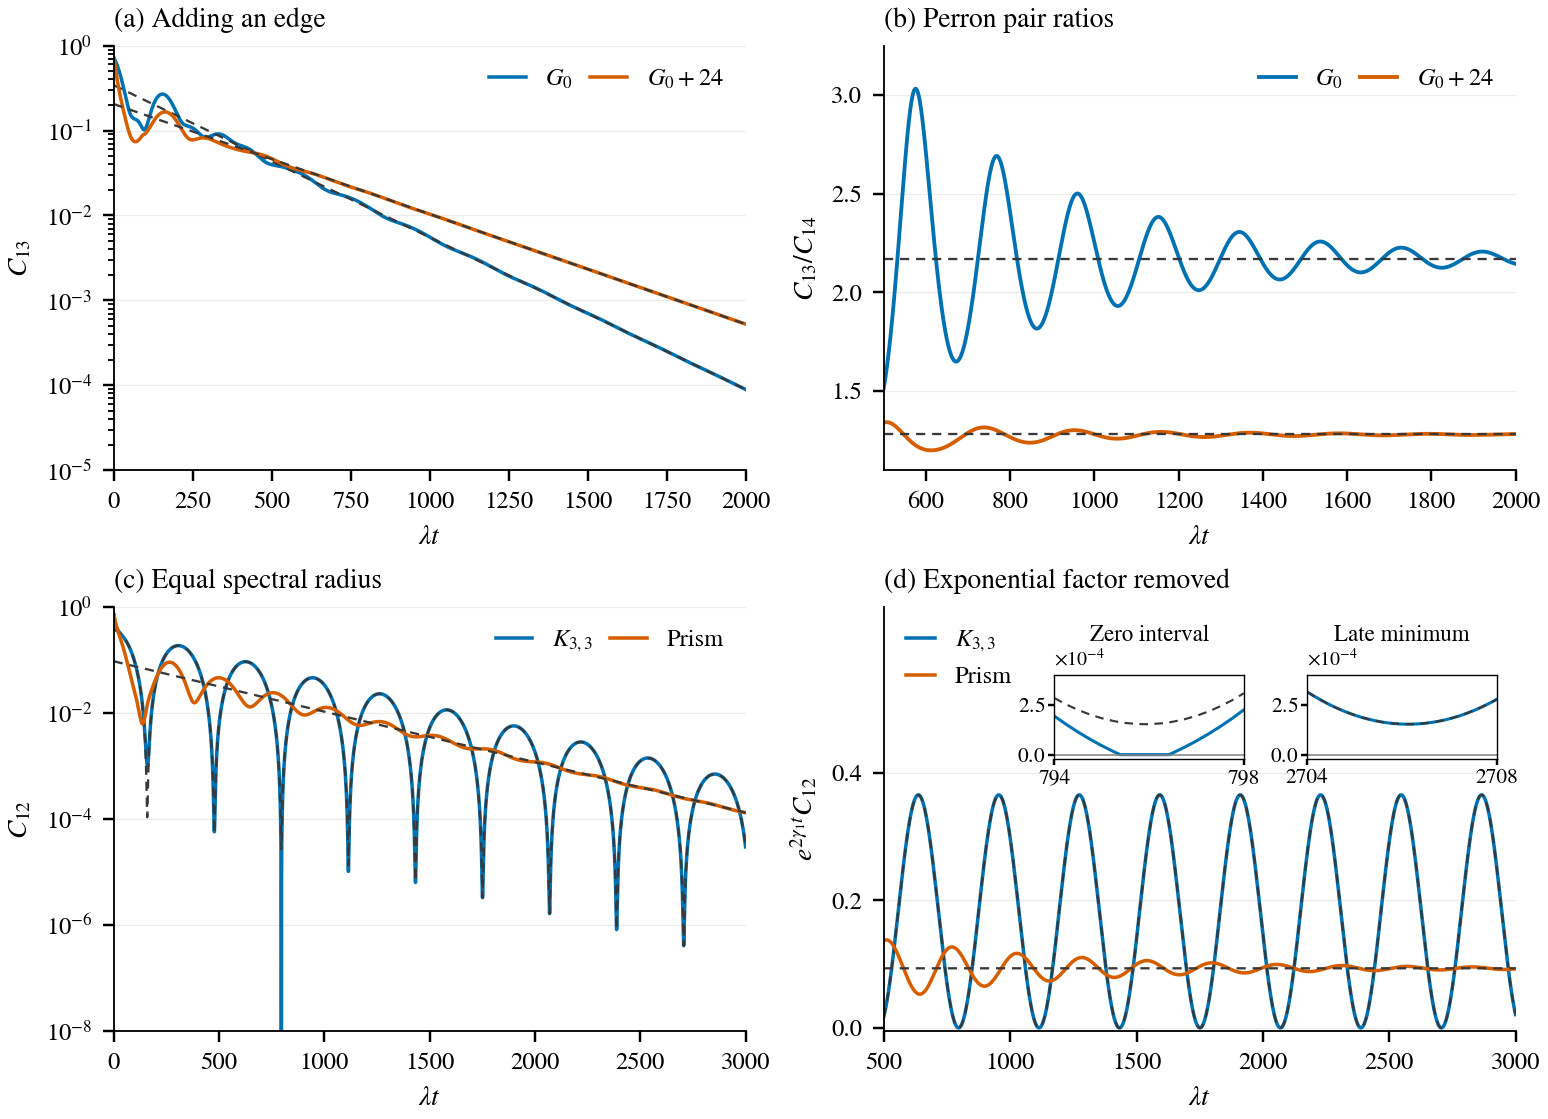

feed_0.1: roots of C [35.9263, 58.1824, 84.6067]
  t=15.8136  C=0  x_part=-0.10313  min eig partial transpose=0.0303
  t=69.3194  C=0  x_part=-0.010022  min eig partial transpose=0.000271
feed_0.8: roots of C [37.4235, 55.6829, 98.7772]
  t=17.3738  C=0  x_part=-0.41134  min eig partial transpose=0.131
  t=72.9306  C=0  x_part=-0.066909  min eig partial transpose=0.00429
  t=283.5191  C=0.019658  x_part=0.019658  min eig partial transpose=-0.000103
  t=456.3409  C=0.0054536  x_part=0.0054536  min eig partial transpose=-7.84e-06
  t=634.0897  C=0.0015294  x_part=0.0015294  min eig partial transpose=-5.97e-07
  t=811.4494  C=0.00042566  x_part=0.00042566  min eig partial transpose=-4.57e-08
  t=988.6892  C=0.00011802  x_part=0.00011802  min eig partial transpose=-3.49e-09
feed_0.1_23: roots of C [7.733, 56.9548]
  t=26.1469  C=0  x_part=-0.042629  min eig partial transpose=0.00239
  t=184.9732  C=0.0072888  x_part=0.0072888  min eig partial transpose=-5.15e-05
feed_0.8_23: roots of C [53

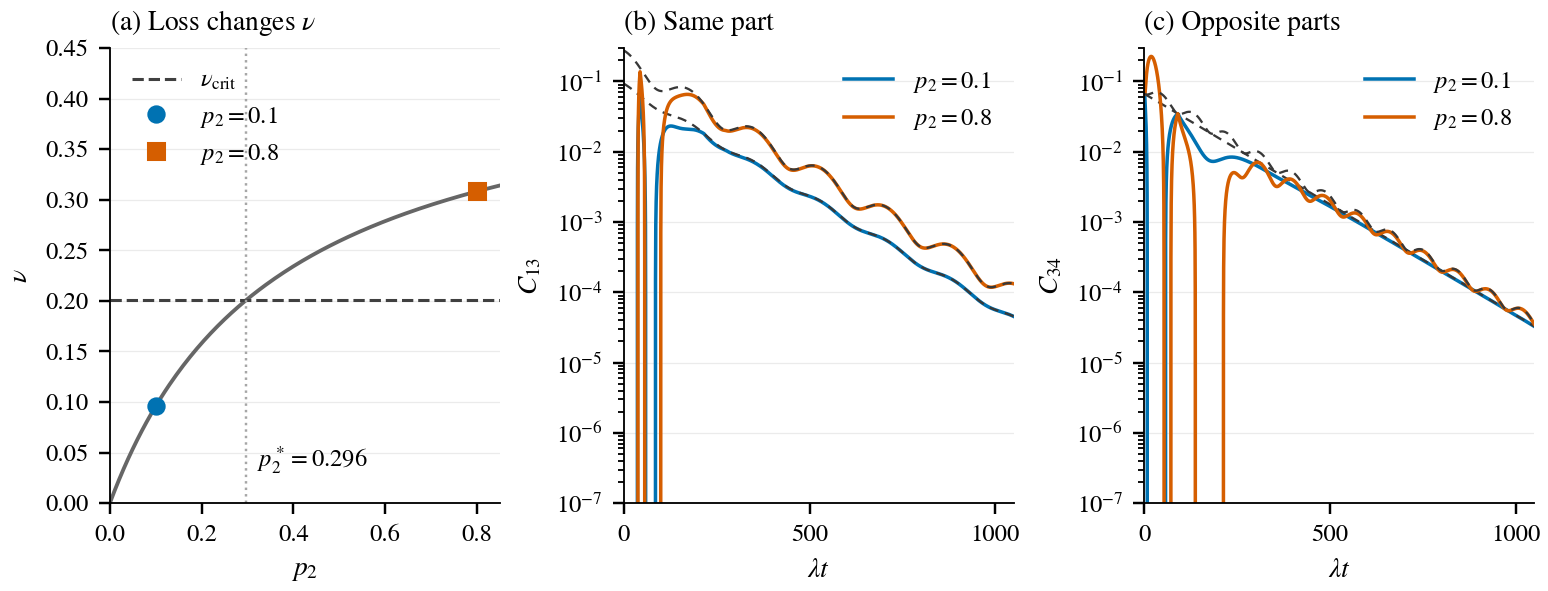

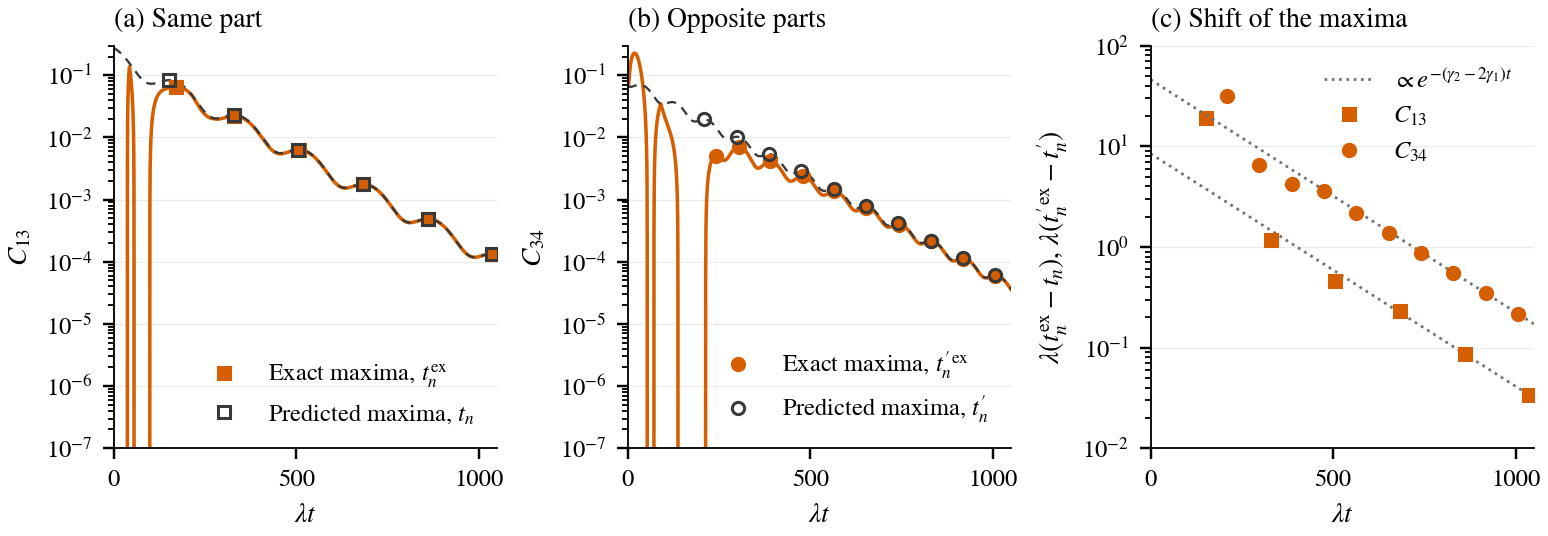

critical_analytic: roots of C []
  t=1.1641  C=0.063116  x_part=0.063116  min eig partial transpose=-0.0316
detuning_0: roots of C []
  t=90.1067  C=0.00017487  x_part=-0.00086834  min eig partial transpose=-3.66e-05
  t=265.7293  C=0.0012549  x_part=0.0012538  min eig partial transpose=-4.83e-07
  t=443.1254  C=0.00033934  x_part=0.00033933  min eig partial transpose=-3.88e-08
  t=620.3327  C=0.00010362  x_part=0.00010362  min eig partial transpose=-3.02e-09
  t=797.5135  C=2.9744e-05  x_part=2.9744e-05  min eig partial transpose=-2.31e-10
  t=974.6890  C=8.3401e-06  x_part=8.3401e-06  min eig partial transpose=-1.77e-11
  t=1151.8625  C=2.3193e-06  x_part=2.3193e-06  min eig partial transpose=-1.36e-12
  t=1329.0353  C=6.4292e-07  x_part=6.4292e-07  min eig partial transpose=-1.04e-13
  t=1506.2076  C=1.78e-07  x_part=1.78e-07  min eig partial transpose=-7.95e-15
  t=1683.3799  C=4.9258e-08  x_part=4.9258e-08  min eig partial transpose=-6.08e-16
detuning_1: roots of C [87.9051, 96.43

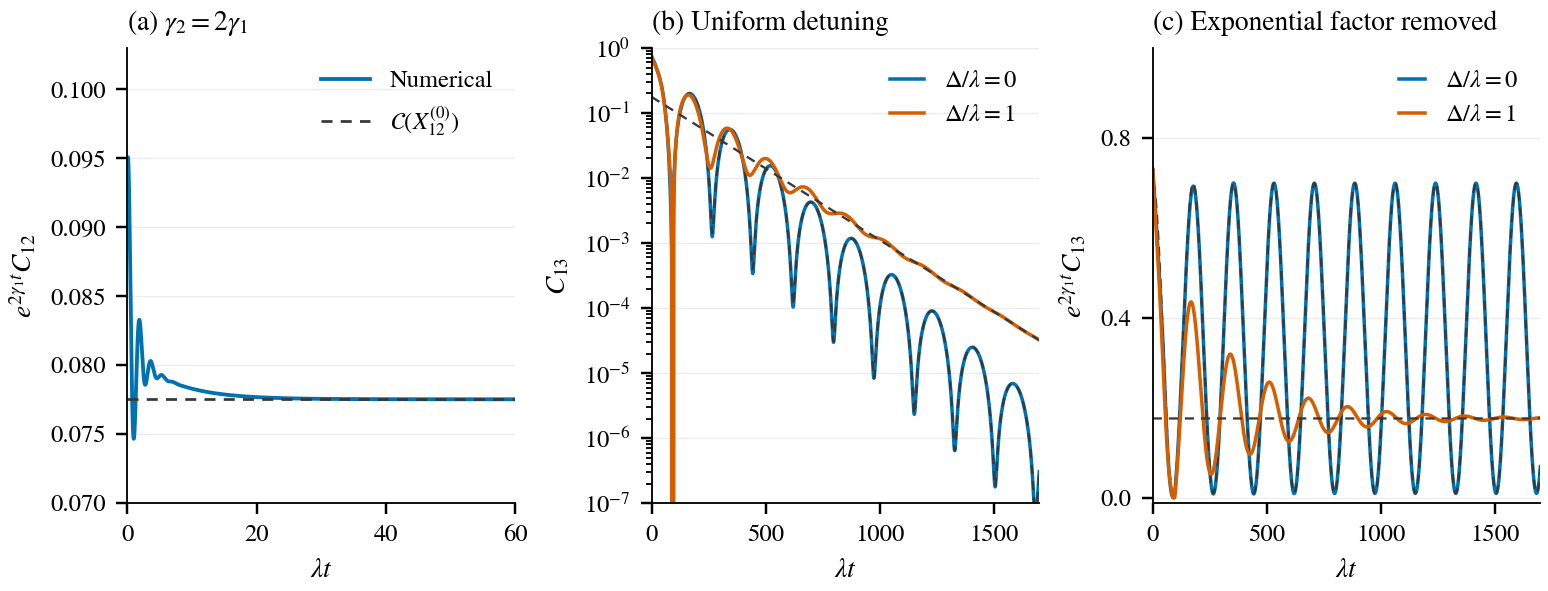

In [27]:
# Direct propagated values. No uniform raw-concurrence cutoff. Markers appear only in fig3_feeding (a) and fig4_times.
plot_audit = []
figure_layout_audit = []


def log_values(values):
    """A logarithmic coordinate cannot represent a computed exact zero."""
    values = np.asarray(values)
    return np.where(values > 0, values, np.nan)


def plot_comparison(ax, key, color, label, scaled=False, log=False,
                    xscaled=False, window=None):
    d = display_data[key]
    t = d['t']
    x = 2 * d['gamma'] * t if xscaled else t
    factor = np.exp(2 * d['gamma'] * t) if scaled else np.ones(len(t))
    cc, ll = d['C'] * factor, d['leading'] * factor
    if log and 'unresolved_boundary_mask' in d:
        cc = cc.copy()
        cc[d['unresolved_boundary_mask']] = np.nan
    mask = ((x >= window[0]) & (x <= window[1])) if window else np.ones(len(t), bool)
    ax.plot(x, log_values(cc) if log else cc, color=color, label=label, lw=1.15)
    ax.plot(x, log_values(ll) if log else ll, color='0.22', ls=(0, (4, 3)), lw=.75)
    if log:
        ax.set_yscale('log')
    plot_audit.append({
        'key': key, 'window': window, 'raw_height_cutoff': None,
        'numerical_sample_count_in_window': int(mask.sum()),
        'log_unresolved_boundary_count': int(d.get('unresolved_boundary_mask', np.zeros(len(t), bool))[mask].sum()) if log else 0,
        'log_computed_zero_count': int(np.count_nonzero((d['C'] == 0) & mask)) if log else 0,
        'minimum_positive_C_in_window': float(d['C'][mask & (d['C'] > 0)].min()),
        'max_exact_asymptotic_difference_plotted_units': float(abs(cc[mask] - ll[mask]).max()),
        'difference_meaning': 'Asymptotic error, not numerical solver error',
        'sampling': 'Direct propagation with optimized extrema and bracketed zero boundaries'})


def trough_inset(ax, key, bounds, window, unit_power, ymax, title='Late minimum', data=None):
    """Enlarge a minimum of the rescaled concurrence, retaining the zero baseline."""
    d = data if data is not None else globals().get('trough_curves', {}).get(key, display_data[key])
    t = d['t']
    mask = (t >= window[0]) & (t <= window[1])
    factor = np.exp(2 * d['gamma'] * t[mask])
    ins = ax.inset_axes(bounds)
    ins.plot(t[mask], d['C'][mask] * factor, color=BLUE, lw=1.0)
    ins.plot(t[mask], d['leading'][mask] * factor, color='0.22', ls=(0, (4, 3)), lw=.7)
    ins.axhline(0, color='0.5', lw=.5)
    ymax = ymax * 10 ** (-unit_power)
    ins.set(xlim=window, ylim=(-ymax * .06, ymax), xticks=[window[0], window[1]])
    ins.set_title(title, fontsize=7.5, pad=2)
    ins.tick_params(labelsize=7, length=2, pad=1)
    ins.ticklabel_format(axis='x', style='plain', useOffset=False)
    ins.ticklabel_format(axis='y', style='sci', scilimits=(0, 0), useMathText=True)
    ins.yaxis.get_offset_text().set_fontsize(6.5)
    for spine in ins.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(.45)
    plot_audit.append({'key': key, 'view': title, 'window': window,
                       'rescaled': True, 'unit_power': unit_power,
                       'zero_baseline': True,
                       'minimum_displayed_Y': float(np.min(d['C'][mask] * np.exp(2 * d['gamma'] * t[mask])))})
    return ins


def report_minima(keys):
    """Print the roots and every local minimum of C, located by refine_display."""
    for key in keys:
        d, events = display_data[key], sampling_audit[key]['events']
        print(f"{key}: roots of C {sorted(round(r['t'], 4) for r in events if r['kind'] == 'root')}")
        for r in (r for r in events if r['kind'] == 'signed_min'):
            # For every two-qubit state, C >= x_part, and C = 0 if the partial transpose has min eigenvalue >= 0.
            X = d['rho'][np.argmin(abs(d['t'] - r['t']))]
            x_part = 2 * max(abs(X[1, 2]) - np.sqrt(X[0, 0].real * X[3, 3].real), abs(X[0, 3]) - np.sqrt(X[1, 1].real * X[2, 2].real))
            ppt = la.eigvalsh(X.reshape(2, 2, 2, 2).transpose(0, 3, 2, 1).reshape(4, 4)).min()
            print(f"  t={r['t']:.4f}  C={r['C']:.5g}  x_part={x_part:.5g}  min eig partial transpose={ppt:.3g}")


def style_axes(axes, titles):
    for ax, title in zip(np.ravel(axes), titles):
        ax.set_title(title, loc='left', pad=6)
        ax.grid(axis='y', color='0.92', lw=.4)


def save_checked_figure(fig, name):
    def all_axes(ax):
        yield ax
        for child in ax.child_axes:
            yield from all_axes(child)
    actual_axes = [a for root in fig.axes for a in all_axes(root)]
    markers = [line.get_marker() for ax in actual_axes for line in ax.lines
               if line.get_marker() not in [None, '', 'None', 'none', ' ']]
    if name == 'fig3_feeding':
        assert markers == ['o', 's'], (name, markers)
        assert all(line.get_marker() in [None, '', 'None', 'none', ' '] for ax in actual_axes[1:] for line in ax.lines)
    elif name == 'fig4_times':
        assert markers == ['s', 's', 'o', 'o', 's', 'o'], (name, markers)
    else:
        assert not markers, (name, markers)
    figure_layout_audit.append({'figure': name, 'curve_markers': markers,
                               'zero_interval_insets': sum(ax.get_title() == 'Zero interval' for ax in actual_axes),
                               'axes_titles': [ax.get_title(loc='left') or ax.get_title() for ax in actual_axes]})
    save_figure(fig, name)


fig, axes = plt.subplots(2, 2, figsize=(7.05, 5.10), layout='constrained')
for name, color, label in [('G0', BLUE, r'$G_0$'), ('G0+24', ORANGE, r'$G_0+24$')]:
    plot_comparison(axes[0, 0], name, color, label, log=True, window=[0, 2000])
    d = display_data[name]
    t = d['t']
    sel = (t >= 500) & (t <= 2000)
    assert np.all(d['C14'][sel] > 0)
    axes[0, 1].plot(t[sel], d['C'][sel] / d['C14'][sel], color=color, label=label)
    axes[0, 1].axhline(summary['graphs'][name]['Perron_pair_ratio'], color='0.22', ls=(0, (4, 3)), lw=.75)
    plot_audit.append({'key': name + '_ratio', 'window': [500, 2000],
                       'raw_height_cutoff': None,
                       'minimum_denominator': float(d['C14'][sel].min()),
                       'sample_count': int(sel.sum())})
axes[0, 0].set(xlim=(0, 2000), ylim=(1e-5, 1), xlabel=r'$\lambda t$', ylabel=r'$C_{13}$')
axes[0, 1].set(xlim=(500, 2000), ylim=(1.1, 3.25), xlabel=r'$\lambda t$', ylabel=r'$C_{13}/C_{14}$')
for key, color, label in [('K33', BLUE, r'$K_{3,3}$'), ('prism', ORANGE, 'Prism')]:
    plot_comparison(axes[1, 0], key, color, label, log=True, window=[0, 3000])
    plot_comparison(axes[1, 1], key, color, label, scaled=True, window=[500, 3000])
axes[1, 0].set(xlim=(0, 3000), ylim=(1e-8, 1), xlabel=r'$\lambda t$', ylabel=r'$C_{12}$')
report_minima(['K33', 'prism'])
axes[1, 1].set(xlim=(500, 3000), ylim=(-.005, .66), xlabel=r'$\lambda t$', ylabel=r'$e^{2\gamma_1t}C_{12}$', yticks=[0, .2, .4])
style_axes(axes, ['(a) Adding an edge', '(b) Perron pair ratios', '(c) Equal spectral radius', '(d) Exponential factor removed'])
for ax in axes.flat:
    ax.legend(frameon=False, loc='upper right', ncol=2, columnspacing=.7, handlelength=1.5)
axes[1, 0].legend(frameon=False, loc='upper right', ncol=2, columnspacing=.7, handlelength=1.5)
axes[1, 1].legend(frameon=False, loc='upper left', ncol=1, handlelength=1.2)
trough_inset(axes[1, 1], 'K33', [.27, .64, .3, .2], [794, 798], 4, 4.0, title='Zero interval', data=display_data['K33'])
trough_inset(axes[1, 1], 'K33', [.67, .64, .3, .2], [2704, 2708], 4, 4.0)
save_checked_figure(fig, 'fig2_graph')

fig, axes = plt.subplots(1, 3, figsize=(7.05, 2.7), layout='constrained')
axes[0].plot(p2_grid, nu_grid, color=GRAY)
axes[0].axhline(threshold, color='0.25', ls='--', lw=1, label=r'$\nu_{\mathrm{crit}}$')
axes[0].axvline(crossing, color='0.65', ls=':', lw=.8)
axes[0].text(crossing + .025, .035, rf'$p_2^*={crossing:.3f}$', fontsize=8)
for p2, color, marker in [(.1, BLUE, 'o'), (.8, ORANGE, 's')]:
    nu = next(row['nu'] for row in summary['feeding']['preparations'] if row['p2'] == p2)
    axes[0].plot([p2], [nu], color=color, marker=marker, markersize=5, ls='none', label=rf'$p_2={p2:g}$', zorder=3)
for p2, color in [(.1, BLUE), (.8, ORANGE)]:
    plot_comparison(axes[1], f'feed_{p2:g}', color, rf'$p_2={p2:g}$', log=True, window=[0, 1050])
    plot_comparison(axes[2], f'feed_{p2:g}_23', color, rf'$p_2={p2:g}$', log=True, window=[0, 1050])
axes[0].set(xlim=(0, .85), ylim=(0, .45), xlabel=r'$p_2$', ylabel=r'$\nu$')
axes[1].set(xlim=(0, 1050), ylim=(1e-7, .3), xticks=[0, 500, 1000], xlabel=r'$\lambda t$', ylabel=r'$C_{13}$')
axes[2].set(xlim=(0, 1050), ylim=(1e-7, .3), xticks=[0, 500, 1000], xlabel=r'$\lambda t$', ylabel=r'$C_{34}$')
style_axes(axes, [r'(a) Loss changes $\nu$', '(b) Same part', '(c) Opposite parts'])
axes[0].legend(frameon=False, loc='upper left')
for ax in axes[1:]:
    ax.legend(frameon=False, loc='upper right')
report_minima(['feed_0.1', 'feed_0.8', 'feed_0.1_23', 'feed_0.8_23'])
save_checked_figure(fig, 'fig3_feeding')

# Late revival times for p2 = 0.8 on the time axis of Fig. 3. Markers show the computed local maxima and the predicted times.
fig, axes = plt.subplots(1, 3, figsize=(7.05, 2.45), layout='constrained')
for ax, key, marker, exact, label in [(axes[0], '13', 's', r'$t_n^{\mathrm{ex}}$', r'$t_n$'),
                                     (axes[1], '34', 'o', r'$t_n^{\prime\,\mathrm{ex}}$', r"$t_n'$")]:
    r = summary['revival_times'][key]
    plot_comparison(ax, 'feed_0.8' if key == '13' else 'feed_0.8_23', ORANGE, None, log=True, window=[0, 1050])
    shown = r['t_pred'] <= 1050
    ax.plot(r['t_exact'][shown], r['C_exact'][shown], color=ORANGE, marker=marker, markersize=4, ls='none', label='Exact maxima, ' + exact)
    ax.plot(r['t_pred'][shown], r['leading_at_pred'][shown], color='0.22', marker=marker, markersize=4, mfc='none', ls='none',
            label='Predicted maxima, ' + label)
    ax.set(ylim=(1e-7, .3), ylabel=rf'$C_{{{key}}}$')
    ax.legend(frameon=False, loc='lower right')
line = np.linspace(0, 1050, 200)
for key, marker in [('13', 's'), ('34', 'o')]:
    r = summary['revival_times'][key]
    shown = r['t_pred'] <= 1050
    t_last, d_last = r['t_pred'][shown][-1], r['difference'][shown][-1]
    axes[2].plot(line, d_last * np.exp(-(r['gamma2'] - 2 * r['gamma1']) * (line - t_last)),
                 color='0.45', ls=':', lw=.9, label=r'$\propto e^{-(\gamma_2-2\gamma_1)t}$' if key == '13' else None)
    axes[2].plot(r['t_pred'][shown], r['difference'][shown], color=ORANGE, marker=marker, markersize=4, ls='none', label=rf'$C_{{{key}}}$')
axes[2].set_yscale('log')
axes[2].set(ylim=(.01, 100), ylabel=r'$\lambda(t_n^{\mathrm{ex}}-t_n)$, $\lambda(t_n^{\prime\,\mathrm{ex}}-t_n^{\prime})$')
axes[2].legend(frameon=False, loc='upper right')
for ax in axes:
    ax.set(xlim=(0, 1050), xticks=[0, 500, 1000], xlabel=r'$\lambda t$')
style_axes(axes, ['(a) Same part', '(b) Opposite parts', '(c) Shift of the maxima'])
save_checked_figure(fig, 'fig4_times')

fig, axs = plt.subplots(1, 3, figsize=(7.05, 2.7), layout='constrained')
d = display_data['critical_analytic']
scale = np.exp(2 * d['gamma'] * d['t'])
axs[0].plot(d['t'], d['C'] * scale, color=BLUE, label='Numerical')
axs[0].plot(d['t'], d['leading'] * scale, color='0.22', ls=(0, (4, 3)), lw=.9, label=r'$\mathcal{C}(X_{12}^{(0)})$')
axs[0].set(xlim=(0, 60), ylim=(.07, .103), xlabel=r'$\lambda t$', ylabel=r'$e^{2\gamma_1t}C_{12}$')
axs[0].legend(loc='upper right', frameon=False)
plot_audit.append({'key': 'critical_analytic', 'window': [0, 60], 'raw_height_cutoff': None,
                   'sample_count': len(d['t']), 'minimum_C': float(d['C'].min()),
                   'max_exact_asymptotic_difference_plotted_units': float(abs((d['C'] - d['leading']) * scale).max()),
                   'difference_meaning': 'Asymptotic error, not numerical solver error'})
for delta, color in [(0., BLUE), (1., ORANGE)]:
    key, label = f'detuning_{delta:g}', rf'$\Delta/\lambda={delta:g}$'
    plot_comparison(axs[2], key, color, label, scaled=True, window=[0, 1700])
    plot_comparison(axs[1], key, color, label, log=True, window=[0, 1700])
axs[2].set(xlim=(0, 1700), ylim=(-.012, 1.0), yticks=[0, .4, .8], xlabel=r'$\lambda t$', ylabel=r'$e^{2\gamma_1t}C_{13}$')
axs[1].set(xlim=(0, 1700), ylim=(1e-7, 1), xlabel=r'$\lambda t$', ylabel=r'$C_{13}$')
# Positive minima below the lower limit of (b), reported in the caption of Fig. 5.
summary['fig5_minima_below_lower_limit'] = [{'key': key, 't': r['t'], 'C': r['C']} for key in ['detuning_0', 'detuning_1']
                                            for r in sampling_audit[key]['events'] if r['kind'] == 'signed_min' and 0 < r['C'] < axs[1].get_ylim()[0]]
axs[2].legend(loc='upper right', frameon=False, handlelength=1.1)
axs[1].legend(loc='upper right', frameon=False, handlelength=1.4)
style_axes(axs, [r'(a) $\gamma_2=2\gamma_1$', '(b) Uniform detuning', '(c) Exponential factor removed'])
report_minima(['critical_analytic', 'detuning_0', 'detuning_1'])
save_checked_figure(fig, 'fig5_general')
summary['display_convention'] = {
    'raw_height_cutoff': None,
    'numerical_curves': 'Direct propagated values with locally refined extrema and zero boundaries',
    'log_zero_handling': 'Computed zeros and independently unresolved boundary residues are omitted on logarithmic axes. Samples near each zero show the approach to zero.',
    'markers': 'No sample markers on curves. Markers show the two p2 values in fig3_feeding (a) and the computed and predicted maxima in fig4_times.',
    'trough_insets': 'Rescaled minima are enlarged with a visible zero baseline: the zero interval and a late positive minimum of K33. Each curve uses its own gamma1.',
    'theory': 'Dark dashed curves computed from manuscript formulas, without fitting trajectories',
    'error_scope': 'Finite empirical checks of propagation, Wootters arithmetic, time sampling and exponential rescaling'}
summary['figure_layout_audit'] = figure_layout_audit


## Complete execution record

The final record saves all five figures, preserved original arrays, separate refined display data, sampling rules, and independent precision checks. Asymptotic discrepancies and numerical accuracy evidence are reported separately.


In [28]:
import IPython
summary['environment'].update(ipython=IPython.__version__)
validation['display_comparisons']=plot_audit
(OUTPUT_DIR/'display_comparisons.json').write_text(json.dumps(_json_ready(plot_audit),indent=2))
summary['runtime_seconds']=time.time()-STARTED
summary['validation']=validation
summary['scope']='Figures 1 to 5 and the numerical checks of Appendix E'
summary['figures']=[name+'.pdf' for name in ['fig1_model','fig2_graph','fig3_feeding','fig4_times','fig5_general']]
assert all((FIGURE_DIR/name).exists() for name in summary['figures'])
(OUTPUT_DIR/'summary.json').write_text(json.dumps(_json_ready(summary),indent=2))
(OUTPUT_DIR/'validation.json').write_text(json.dumps(_json_ready(validation),indent=2))
np.savez_compressed(OUTPUT_DIR/'arrays.npz',**arrays)
execution_record={'status':'passed','numeric_timer_seconds':summary['runtime_seconds'],
    'numeric_timer_definition':'Time after setup imports through final save cell',
    'code_cell_count':28,'figure_count':len(summary['figures']),'array_count':len(arrays),'validation':validation}
(OUTPUT_DIR/'execution_validation.json').write_text(json.dumps(_json_ready(execution_record),indent=2))
print(f"Computed Figs. 1 to 5 and the Appendix E checks in {summary['runtime_seconds']:.1f} seconds after imports")
print('Saved every figure, numerical array, and independent check.')


Computed Figs. 1 to 5 and the Appendix E checks in 895.8 seconds after imports
Saved every figure, numerical array, and independent check.
